# Import Library

In [25]:
#Initial setup
import warnings
warnings.filterwarnings('ignore')
from IPython.display import display

import pandas as pd
import os
import numpy as np
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from decimal import Decimal, ROUND_HALF_UP
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.linear_model import LassoCV
from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.ensemble import RandomForestClassifier

from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import r2_score, mean_squared_error
from sklearn.metrics import r2_score, mean_absolute_error
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    roc_auc_score,
    roc_curve,
    RocCurveDisplay,
    confusion_matrix,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report
)

from sklearn.model_selection import KFold
from sklearn.model_selection import GridSearchCV, RandomizedSearchCV
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LassoCV
from sklearn.linear_model import LogisticRegression
import urllib.request
import joblib

# Import dataset

In [4]:
fileDir = "./Data/"
fileName = "pro_data_common_val_Assay.csv"

path = os.path.join(fileDir, fileName)
temp = pd.read_csv(path)
temp.set_index(temp.columns[0],inplace=True)
temp.index.name = None
pro_data = temp
display(pro_data)

,CCND1,CENPS,ERG,EVL,FBXO40,GSDMD,HDAC5,IFNB1,IFNL4,IL11RA,...,DUT,NDRG1,PDGFC,TRIP11,CBS,PTPRK,DNAJB1,PPME1,ANKRD11,FHIT
PE_R478_001,-0.250458,-0.391125,-0.252621,0.150167,-0.047767,-0.316298,-0.044654,0.516400,1.150911,-0.027801,...,0.734304,0.110696,0.058819,-0.250565,-0.145040,-0.262231,-0.306965,-0.328111,0.216998,-0.101624
PE_R478_002,0.650528,1.724016,0.550598,2.128050,-0.040240,1.335081,0.269637,-0.182468,-0.071227,-0.251168,...,3.043780,0.944960,-0.074905,-0.028470,-0.112292,0.009771,0.605862,1.732763,0.050603,-0.070623
PE_R478_003,-0.391076,0.827442,0.564473,0.000000,2.602543,0.168998,-0.149231,0.027239,1.254693,1.006632,...,-0.175562,0.927932,0.247506,1.032951,-0.320810,0.012949,0.187431,-0.014972,-0.272747,0.060313
PE_R478_004,0.070462,-0.096654,-0.382649,0.026322,0.003985,0.493930,-0.002798,-0.114333,-0.118398,1.043088,...,-0.603477,-0.421595,0.008789,-0.258851,1.877652,0.111118,0.459926,0.325601,3.782591,-0.063099
PE_R478_005,0.378868,0.522751,2.066188,1.183532,0.329253,1.291015,1.488711,1.123200,0.775145,-0.163659,...,2.440574,0.711782,0.082763,1.664001,1.675150,0.773179,0.788874,0.492789,0.191108,0.228033
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
PE_R478_396,2.090906,0.937016,0.432914,0.422205,-0.034455,0.301893,-0.417816,0.567447,-0.038375,0.396514,...,-0.318979,0.567542,-0.176940,-1.468123,0.858104,0.097731,-0.573343,-0.164230,0.004873,-0.195060
PE_R478_397,0.652913,-0.084482,0.471556,0.067670,0.048786,1.311366,0.047220,-0.000537,-0.037272,0.503015,...,0.953380,2.234465,0.233921,-0.020321,3.746860,0.025703,0.553025,0.145132,0.019710,2.857327
PE_R478_398,0.025657,-0.369096,-0.940943,-0.833491,-0.035938,-0.282643,0.902980,-0.354449,-0.378662,0.830012,...,0.373973,-0.330692,0.003094,0.760417,-0.094866,-0.042590,0.295296,0.252283,-0.597332,0.102647
PE_R478_399,0.115515,0.252649,0.799482,-0.555303,-0.095176,0.147232,-0.232622,0.275772,-0.090074,-0.284806,...,-0.294149,2.978748,-0.111313,-0.910355,0.684876,-0.089939,-0.454858,-0.286652,-0.528971,-0.131158


In [5]:
fileDir = "./Data/"
fileName = "pro_data_common_dis_Assay.csv"

path = os.path.join(fileDir, fileName)
temp = pd.read_csv(path)
temp.set_index(temp.columns[0],inplace=True)
temp.index.name = None
pro_data_dis = temp
display(pro_data_dis)

,CCND1,CENPS,ERG,EVL,FBXO40,GSDMD,HDAC5,IFNB1,IFNL4,IL11RA,...,PTPRB,PTPRZ1,ROBO2,S100A11,SIGLEC7,SMPD1,TIMP2,TNFRSF11B,TNFRSF13B,TNFSF13
PE_R345_001,-0.692179,0.014487,0.020949,0.756419,-6.905352,-1.666651,0.110046,0.232470,0.976434,0.333324,...,0.149422,0.109952,0.043224,-0.113186,-0.173051,-0.188583,-0.500891,-0.449172,0.256756,-0.047204
PE_R345_002,-0.369176,0.684363,0.107959,0.226569,-0.895626,0.109439,-0.303590,0.920268,0.553696,0.262794,...,0.138417,0.010032,-0.375500,-0.283585,-0.078765,-0.462358,-0.050531,-0.265815,-0.329777,-0.093153
PE_R345_003,-2.394688,-0.344467,0.324566,-0.662745,-0.618029,0.400878,0.781645,-1.083091,1.017989,-0.476468,...,0.297876,0.215148,-0.298019,0.230742,-0.446693,-0.238989,-0.149903,-0.368405,-0.777895,0.263554
PE_R345_004,0.639747,-0.618308,-6.105701,-0.604463,-0.660618,0.948256,0.658751,-5.307591,1.752600,0.242457,...,0.248981,-0.836763,-0.025668,0.707852,0.094298,0.143641,-1.107125,-0.370944,0.038383,-0.088797
PE_R345_005,-0.820588,1.828802,0.743556,0.944768,0.374343,-0.004282,0.768770,-0.472727,2.379818,0.355268,...,-0.719388,-0.386761,-0.057828,-0.293611,-0.615043,0.109108,-0.304250,-0.075093,-0.269609,-0.345198
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
PE_R345_116,0.562479,0.149407,-0.096848,-0.511773,1.161234,0.435930,0.034395,1.648347,-1.236074,0.230566,...,-0.024150,-0.454680,-0.295363,-0.015434,0.008547,-0.302837,0.642489,-0.415615,0.223440,0.364843
PE_R345_117,0.479147,-2.197393,-1.046985,-0.710840,0.222618,-1.514128,-0.754977,-0.603034,-0.655577,-0.820657,...,0.024235,0.431829,-0.105863,-0.214236,-0.203326,0.082807,0.208317,0.596235,0.059546,0.050563
PE_R345_118,-0.224505,1.418296,-0.638240,-0.916879,0.022731,-0.256893,1.527204,0.002125,0.944555,0.227068,...,0.024150,0.177696,0.283866,-0.576475,-0.369869,-0.202398,-0.477743,-0.116504,-0.035482,-0.582310
PE_R345_119,2.850504,2.163309,-0.020949,0.127092,1.120073,0.066293,-0.140565,0.364944,1.119934,-0.804565,...,-0.242695,0.292754,0.197778,-0.129258,0.404362,0.196653,0.153734,0.130001,-0.233168,0.494186


In [6]:
fileDir = "./Data/"
fileName = "pro_sample_val.csv"

path = os.path.join(fileDir, fileName)
temp = pd.read_csv(path)
temp.set_index(temp.columns[0],inplace=True)
temp.index.name = None
pro_sample = temp
display(pro_sample)

,progress,sex,fvage,CaCo_Status,icdo3t,icdo3m,smoker,py,drinker,quant_drink_gr,bmi,hx_dm,CA19_9,sIL2R,progress_group
PE_R478_001,0,1,58,0,NaN,NaN,2,8,1,25,20,0,4.100,134.0,0
PE_R478_002,0,1,62,0,NaN,NaN,2,10,1,33,23,0,1.999,5500.0,0
PE_R478_003,0,1,68,0,NaN,NaN,1,24,3,0,22,0,2.700,259.0,0
PE_R478_004,0,2,70,0,NaN,NaN,3,0,3,0,26,0,3.800,208.0,0
PE_R478_005,440,1,59,1,C252,81403.0,3,0,3,0,29,0,1200.000,1181.0,2
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
PE_R478_396,410,1,63,1,C250,84533.0,1,27,3,0,26,1,1.999,263.0,1
PE_R478_397,410,2,64,1,C250,85003.0,3,0,1,12,22,0,1.999,257.0,1
PE_R478_398,0,1,38,0,NaN,NaN,2,13,1,4,29,0,2.100,257.0,0
PE_R478_399,410,2,47,1,C250,85003.0,3,0,1,2,21,0,16.900,216.0,1


In [7]:
fileDir = "./Data/"
fileName = "map_OID_Uni_Sym.csv"

path = os.path.join(fileDir, fileName)
IDdata = pd.read_csv(path)
IDdata.set_index(IDdata.columns[0],inplace=True)
IDdata.index.name = None
display(IDdata)

,OlinkID,UniProt,Symbol
1,OID50001,AMP1,AMP1*
2,OID50002,INC1,INC1*
3,OID50003,EXT1,EXT1*
4,OID50004,P24385,CCND1
5,OID50005,Q8N2Z9,CENPS
...,...,...,...
1036,OID51099,Q15262,PTPRK
1037,OID51100,P25685,DNAJB1
1038,OID51101,Q9Y570,PPME1
1039,OID51102,Q6UB99,ANKRD11


In [8]:
fileDir = "./Data/"
fileName = "DEP_list.csv"

path = os.path.join(fileDir, fileName)
temp = pd.read_csv(path)
temp.set_index(temp.columns[0],inplace=True)
temp.index.name = None
display(temp)
DEPlist = temp

,logFC,AveExpr,t,P.Value,adj.P.Val,B,DEP
MUC16,0.985542,0.277109,8.094421,7.124543e-15,7.359653e-12,23.200691,Up
GP2,1.511764,0.788461,7.795842,5.690210e-14,1.975121e-11,21.192249,Up
ANXA10,0.855186,0.253980,7.794673,5.736074e-14,1.975121e-11,21.184493,Up
CDCP1,0.534318,0.048105,6.607271,1.263164e-10,2.174747e-08,13.764327,Up
CCL7,0.536885,0.113156,6.399043,4.414271e-10,5.066602e-08,12.562273,Up
CTRL,0.867936,0.232265,6.306886,7.604670e-10,7.855624e-08,12.040208,Up
SERPINI2,0.821832,0.240901,6.225526,1.222992e-09,1.009585e-07,11.584433,Up
REG3G,0.596529,0.260564,6.144717,1.951222e-09,1.185654e-07,11.136547,Up
KRT19,0.508638,0.206256,6.076392,2.885585e-09,1.530100e-07,10.761612,Up
S100A12,0.542721,0.039343,6.071780,2.962439e-09,1.530100e-07,10.736431,Up


In [9]:
fileDir = "./Data/"
fileName = "pro_data_common_dis.csv"

path = os.path.join(fileDir, fileName)
temp = pd.read_csv(path)
temp.set_index(temp.columns[0],inplace=True)
temp.index.name = None
pro_data_dis= temp
display(pro_data_dis)

,P24385,Q8N2Z9,P11308,Q9UI08,Q9UH90,P57764,Q9UQL6,P01574,K9M1U5,Q14626,...,P23467,P23471,Q9HCK4,P31949,Q9Y286,P17405,P16035,O00300,O14836,O75888
PE_R345_001,-0.692179,0.014487,0.020949,0.756419,-6.905352,-1.666651,0.110046,0.232470,0.976434,0.333324,...,0.149422,0.109952,0.043224,-0.113186,-0.173051,-0.188583,-0.500891,-0.449172,0.256756,-0.047204
PE_R345_002,-0.369176,0.684363,0.107959,0.226569,-0.895626,0.109439,-0.303590,0.920268,0.553696,0.262794,...,0.138417,0.010032,-0.375500,-0.283585,-0.078765,-0.462358,-0.050531,-0.265815,-0.329777,-0.093153
PE_R345_003,-2.394688,-0.344467,0.324566,-0.662745,-0.618029,0.400878,0.781645,-1.083091,1.017989,-0.476468,...,0.297876,0.215148,-0.298019,0.230742,-0.446693,-0.238989,-0.149903,-0.368405,-0.777895,0.263554
PE_R345_004,0.639747,-0.618308,-6.105701,-0.604463,-0.660618,0.948256,0.658751,-5.307591,1.752600,0.242457,...,0.248981,-0.836763,-0.025668,0.707852,0.094298,0.143641,-1.107125,-0.370944,0.038383,-0.088797
PE_R345_005,-0.820588,1.828802,0.743556,0.944768,0.374343,-0.004282,0.768770,-0.472727,2.379818,0.355268,...,-0.719388,-0.386761,-0.057828,-0.293611,-0.615043,0.109108,-0.304250,-0.075093,-0.269609,-0.345198
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
PE_R345_116,0.562479,0.149407,-0.096848,-0.511773,1.161234,0.435930,0.034395,1.648347,-1.236074,0.230566,...,-0.024150,-0.454680,-0.295363,-0.015434,0.008547,-0.302837,0.642489,-0.415615,0.223440,0.364843
PE_R345_117,0.479147,-2.197393,-1.046985,-0.710840,0.222618,-1.514128,-0.754977,-0.603034,-0.655577,-0.820657,...,0.024235,0.431829,-0.105863,-0.214236,-0.203326,0.082807,0.208317,0.596235,0.059546,0.050563
PE_R345_118,-0.224505,1.418296,-0.638240,-0.916879,0.022731,-0.256893,1.527204,0.002125,0.944555,0.227068,...,0.024150,0.177696,0.283866,-0.576475,-0.369869,-0.202398,-0.477743,-0.116504,-0.035482,-0.582310
PE_R345_119,2.850504,2.163309,-0.020949,0.127092,1.120073,0.066293,-0.140565,0.364944,1.119934,-0.804565,...,-0.242695,0.292754,0.197778,-0.129258,0.404362,0.196653,0.153734,0.130001,-0.233168,0.494186


In [10]:
fileDir = "../Proteomics/Data/"
fileName = "CA199.csv"

path = os.path.join(fileDir, fileName)
temp = pd.read_csv(path)
temp.set_index(temp.columns[0],inplace=True)
temp.index.name = None
temp = temp.sort_values('SampleID')
temp = temp.set_index('SampleID')
ca199_dis= temp
display(ca199_dis)

,CA199,acc,value,logvalue
SampleID,,,,
PE_R345_001,CA-19-9,14887,0.0,0.000000
PE_R345_002,CA-19-9,14961,109.4,2.042969
PE_R345_003,CA-19-9,15002,13.7,1.167317
PE_R345_004,CA-19-9,15271,8.0,0.954243
PE_R345_005,CA-19-9,15414,771.7,2.888011
...,...,...,...,...
PE_R345_116,CA-19-9,26188,0.0,0.000000
PE_R345_117,CA-19-9,26351,11.4,1.093422
PE_R345_118,CA-19-9,26399,21.8,1.357935


In [11]:
fileDir = "./Data/"
fileName = "pro_sample_dis.csv"

path = os.path.join(fileDir, fileName)
temp = pd.read_csv(path)
temp.set_index(temp.columns[0],inplace=True)
temp.index.name = None
pro_sample_dis = temp
display(pro_sample_dis)

,groupset1,groupset2,groupset3,progress,sex,fvage,CaCo_status,icdo3t,icdo3m,smoker,py,drinker,quant_drink_gr,bmi,hx_dm
PE_R345_001,2,0,1,NaN,2,52,control,NaN,NaN,Former,34,Current,1,21,0
PE_R345_002,1,1,2,440.0,1,56,case,C259,8140/39,Former,26,Current,31,23,0
PE_R345_003,1,1,2,430.0,1,62,case,C259,8211/32,Current,44,Current,6,19,0
PE_R345_004,1,1,2,440.0,1,39,case,C251,8500/39,Never,0,Never,0,24,0
PE_R345_005,2,1,3,440.0,2,48,case,C251,8140/39,Never,0,Never,0,17,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
PE_R345_116,1,0,0,NaN,1,59,control,NaN,NaN,Current,78,Current,69,26,0
PE_R345_117,2,0,1,NaN,2,64,control,NaN,NaN,Current,66,Current,21,17,0
PE_R345_118,2,1,3,430.0,2,39,case,C251,8150/39,Former,3,Current,46,21,0
PE_R345_119,2,1,3,440.0,2,51,case,C250,8140/39,Never,0,Former,2,19,0


# モデル学習

log変換、欠損値の処理、標準化済み

## ①全プロテオミクスver

In [101]:
X = pro_data
y = pro_sample["CaCo_Status"]

print(X.shape)
print(y.shape)

print(X.index[:5])
print(y.index[:5])

(398, 1033)
(398,)
Index(['PE_R478_001', 'PE_R478_002', 'PE_R478_003', 'PE_R478_004',
       'PE_R478_005'],
      dtype='object', name='SampleID')
Index(['PE_R478_001', 'PE_R478_002', 'PE_R478_003', 'PE_R478_004',
       'PE_R478_005'],
      dtype='object')


/opt/conda/lib/python3.11/site-packages/pandas/core/computation/expressions.py:23: UserWarning: Pandas requires version '2.10.2' or newer of 'numexpr' (version '2.8.7' currently installed).
  from pandas.core.computation.check import NUMEXPR_INSTALLED
/opt/conda/lib/python3.11/site-packages/pandas/core/arrays/masked.py:56: UserWarning: Pandas requires version '1.4.2' or newer of 'bottleneck' (version '1.3.7' currently installed).
  from pandas.core import (
/opt/conda/lib/python3.11/site-packages/pandas/core/computation/expressions.py:23: UserWarning: Pandas requires version '2.10.2' or newer of 'numexpr' (version '2.8.7' currently installed).
  from pandas.core.computation.check import NUMEXPR_INSTALLED
/opt/conda/lib/python3.11/site-packages/pandas/core/computation/expressions.py:23: UserWarning: Pandas requires version '2.10.2' or newer of 'numexpr' (version '2.8.7' currently installed).
  from pandas.core.computation.check import NUMEXPR_INSTALLED
/opt/conda/lib/python3.11/site-pac

Unexpected exception formatting exception. Falling back to standard exception


/opt/conda/lib/python3.11/site-packages/sklearn/base.py:525: InconsistentVersionWarning: Trying to unpickle estimator DecisionTreeClassifier from version 1.3.1 when using version 1.9.1. This might lead to breaking code or invalid results. Use at your own risk. For more info please refer to:
https://scikit-learn.org/stable/model_persistence.html#security-maintainability-limitations
  warnings.warn(
/opt/conda/lib/python3.11/site-packages/sklearn/base.py:525: InconsistentVersionWarning: Trying to unpickle estimator RandomForestClassifier from version 1.3.1 when using version 1.9.1. This might lead to breaking code or invalid results. Use at your own risk. For more info please refer to:
https://scikit-learn.org/stable/model_persistence.html#security-maintainability-limitations
  warnings.warn(
joblib.externals.loky.process_executor._RemoteTraceback: 
"""
Traceback (most recent call last):
  File "/opt/conda/lib/python3.11/site-packages/joblib/externals/loky/process_executor.py", line 453,

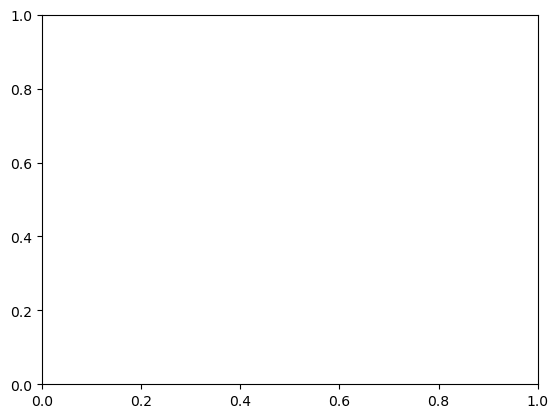

In [50]:
import time
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=123)
aucs = []
fig, ax = plt.subplots()

for i, (train_index, test_index) in enumerate(skf.split(X, y)):
    
    X_train, X_test = X.iloc[train_index], X.iloc[test_index]
    y_train, y_test = y.iloc[train_index], y.iloc[test_index]

# X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=123)
    param_grid = {
        'n_estimators': [50,100, 300, 500],
        "max_depth": [None, 3, 5, 10, 15],
        # 'min_samples_split': [2, 3, 4],
        'min_samples_leaf': [1, 2, 4],
        'max_features': [None, 'sqrt'],
        'class_weight': ['balanced']
    }

    model = RandomForestClassifier(
        criterion='gini',
        random_state=123,
        # class_weight='balanced',
        n_jobs=1 
    )
    
    cv_gen = StratifiedKFold(n_splits=5, shuffle=True, random_state=123)
    
    modelcv = GridSearchCV(
        model, 
        param_grid=param_grid,
        scoring='roc_auc',
        n_jobs=-1, 
        refit=True, 
        cv=cv_gen,
        verbose=0, 
        pre_dispatch='2*n_jobs', 
        error_score=np.nan, 
        return_train_score=False
    )

    start = time.time()
    # 訓練の実行
    modelcv.fit(X_train, y_train)
    elapsed = time.time() - start
    print(f"1回のGridSearchCV: {elapsed / 60:.2f} 分")
    print(f"全5 foldの推定時間: {elapsed * 5 / 60:.2f} 分")

    print('Best score: ', modelcv.best_score_)
    print('Best hyperparameters: ', modelcv.best_params_)
    dataframe = pd.DataFrame(modelcv.cv_results_).sort_values('mean_test_score', ascending=False)
    display(dataframe)
    
    model = modelcv.best_estimator_
    y_prob = model.predict_proba(X_test)[:, 1]
    score = roc_auc_score(y_test, y_prob)
    aucs.append(score)

    print('AUC: ', score)
    
    RocCurveDisplay.from_predictions(
        y_test,
        y_prob,
        name=f"Fold {i+1}", ax=ax
    )
    
print(f"5-Fold平均AUC: {np.mean(aucs):.4f} ± {np.std(aucs)}")
plt.show()



importance_df = pd.DataFrame({
    "Protein": X.columns,
    "Importance": model.feature_importances_
})
importance_df = importance_df.sort_values(
    "Importance",
    ascending=False
)
print(importance_df.head(20))



/opt/conda/lib/python3.11/site-packages/pandas/core/computation/expressions.py:23: UserWarning: Pandas requires version '2.10.2' or newer of 'numexpr' (version '2.8.7' currently installed).
  from pandas.core.computation.check import NUMEXPR_INSTALLED
/opt/conda/lib/python3.11/site-packages/pandas/core/arrays/masked.py:56: UserWarning: Pandas requires version '1.4.2' or newer of 'bottleneck' (version '1.3.7' currently installed).
  from pandas.core import (
/opt/conda/lib/python3.11/site-packages/pandas/core/computation/expressions.py:23: UserWarning: Pandas requires version '2.10.2' or newer of 'numexpr' (version '2.8.7' currently installed).
  from pandas.core.computation.check import NUMEXPR_INSTALLED
/opt/conda/lib/python3.11/site-packages/pandas/core/computation/expressions.py:23: UserWarning: Pandas requires version '2.10.2' or newer of 'numexpr' (version '2.8.7' currently installed).
  from pandas.core.computation.check import NUMEXPR_INSTALLED
/opt/conda/lib/python3.11/site-pac

Unexpected exception formatting exception. Falling back to standard exception


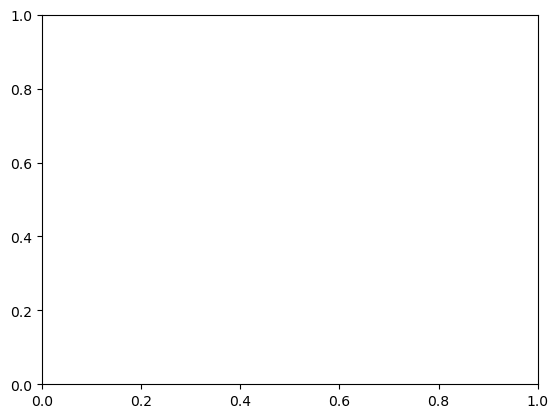

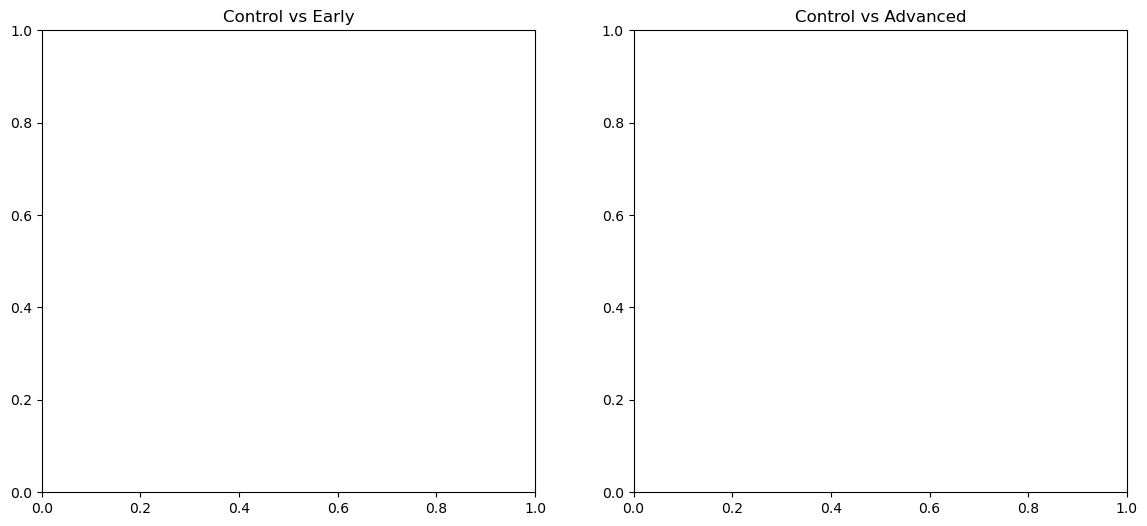

In [95]:
import time
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=123)
aucs = []
fig, ax = plt.subplots()

# ==========================================
# progress_group別ROC用の図
# ==========================================
fig_progress, axes_progress = plt.subplots(1, 2, figsize=(14, 6))

axes_progress[0].set_title("Control vs Early")
axes_progress[1].set_title("Control vs Advanced")

progress_auc = {
    "Early": [],
    "Advanced": []
}

# 各foldの予測結果を保存
y_prob_all = np.full(len(y), np.nan)
y_true_all = np.full(len(y), np.nan)
feature_importances = []

# 追加：各foldの評価指標・最適パラメータを保存
fold_metrics = []
best_params_all = []

save_dir = "./RF_Data/RF_status_all"
os.makedirs(save_dir, exist_ok=True)

for i, (train_index, test_index) in enumerate(skf.split(X, y)):

    X_train, X_test = X.iloc[train_index], X.iloc[test_index]
    y_train, y_test = y.iloc[train_index], y.iloc[test_index]

    param_grid = {
        'n_estimators': [50, 100, 300, 500],
        "max_depth": [None, 3, 5, 10, 15],
        'min_samples_leaf': [1, 2, 4],
        'max_features': [None, 'sqrt'],
        'class_weight': ['balanced']
    }
    # param_grid = {
    #     'n_estimators': [50],
    #     "max_depth": [10],
    #     'min_samples_leaf': [4],
    #     'max_features': ['sqrt'],
    #     'class_weight': ['balanced']
    # }

    model = RandomForestClassifier(
        criterion='gini',
        random_state=123,
        n_jobs=1
    )

    cv_gen = StratifiedKFold(n_splits=5, shuffle=True, random_state=123)

    modelcv = GridSearchCV(
        model,
        param_grid=param_grid,
        scoring='roc_auc',
        n_jobs=-1,
        refit=True,
        cv=cv_gen,
        verbose=0,
        pre_dispatch='2*n_jobs',
        error_score=np.nan,
        return_train_score=False
    )

    start = time.time()
    modelcv.fit(X_train, y_train)
    elapsed = time.time() - start

    print(f"1回のGridSearchCV: {elapsed / 60:.2f} 分")
    print(f"全5 foldの推定時間: {elapsed * 5 / 60:.2f} 分")
    print('Best score: ', modelcv.best_score_)
    print('Best hyperparameters: ', modelcv.best_params_)

    # 追加：各foldの最適パラメータを保存
    best_params_all.append({
        "Fold": i + 1,
        "Best_Params": modelcv.best_params_
    })

    dataframe = pd.DataFrame(
        modelcv.cv_results_
    ).sort_values('mean_test_score', ascending=False)
    display(dataframe)

    model = modelcv.best_estimator_

    # Foldごとの学習済みモデルを保存
    joblib.dump(
        model,
        f"{save_dir}/rf_model_fold_{i+1}.joblib"
    )
    
    # Foldごとのテストデータを保存
    X_test.to_csv(
        f"{save_dir}/X_test_fold_{i+1}.csv",
        index=True
    )
    
    # テストデータの正解ラベルを保存
    y_test.to_csv(
        f"{save_dir}/y_test_fold_{i+1}.csv",
        index=True
    )
    
    # 特徴量名を保存
    pd.Series(X.columns).to_csv(
        f"{save_dir}/feature_names.csv",
        index=False,
        header=["Feature"]
    )
    # 予測確率とAUC
    y_prob = model.predict_proba(X_test)[:, 1]
    score = roc_auc_score(y_test, y_prob)
    aucs.append(score)


    # ==========================================
    # progress_group別ROC曲線
    # ==========================================

    # テストデータのprogress_groupを取得
    # pro_sampleとXは同じ行順であることを前提とする
    progress_test = (
        pro_sample["progress_group"]
        .iloc[test_index]
        .astype(str)
        .str.strip()
        .str.lower()
    )
    comparisons = [
        {"name": "Early", "positive": ["1", "early"], "ax": axes_progress[0]},
        {"name": "Advanced", "positive": ["2", "advanced", "advanced/metastatic"], "ax": axes_progress[1]}
    ]
    
    for comp in comparisons:
        mask = (
            progress_test.isin(["0", "control"]) |
            progress_test.isin(comp["positive"])
        )
    
        progress_labels = (
            progress_test[mask].isin(comp["positive"]).astype(int)
        )
        prob_subset = y_prob[mask.to_numpy()]
    
        if progress_labels.nunique() == 2:
            fpr, tpr, thresholds = roc_curve(
                progress_labels, prob_subset
            )
            auc_progress = roc_auc_score(
                progress_labels, prob_subset
            )
    
            # 各foldのAUCをlegendに表示
            comp["ax"].plot(
                fpr,
                tpr,
                label=f"Fold {i+1} (AUC = {auc_progress:.3f})"
            )
    
            progress_auc[comp["name"]].append(auc_progress)


    # OOF予測を保存
    y_prob_all[test_index] = y_prob
    y_true_all[test_index] = np.asarray(y_test)

    # 各foldの特徴量重要度
    feature_importances.append(model.feature_importances_)

    # 追加：各foldの評価指標を計算
    y_pred = (y_prob >= 0.5).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        y_test, y_pred, labels=[0, 1]
    ).ravel()

    fold_metrics.append({
        "Fold": i + 1,
        "AUC": score,
        "Accuracy": (tp + tn) / (tp + tn + fp + fn),
        "Sensitivity": tp / (tp + fn) if tp + fn else np.nan,
        "Specificity": tn / (tn + fp) if tn + fp else np.nan,
        "False Positive Rate": fp / (fp + tn) if fp + tn else np.nan,
        "False Negative Rate": fn / (fn + tp) if fn + tp else np.nan,
        "PPV": tp / (tp + fp) if tp + fp else np.nan,
        "NPV": tn / (tn + fn) if tn + fn else np.nan
    })

    print('AUC: ', score)

    RocCurveDisplay.from_predictions(
        y_test,
        y_prob,
        name=f"Fold {i+1}",
        ax=ax
    )

print(f"5-Fold平均AUC: {np.mean(aucs):.4f} ± {np.std(aucs, ddof=1):.4f}")
plt.show()
# ==========================================
# progress_group別ROC曲線を表示
# ==========================================

for ax in axes_progress:
    # ax.plot(
    #     [0, 1], [0, 1],
    #     linestyle="--",
    #     color="gray",
    #     label="Chance"
    # )
    # ax.set_xlim(0, 1)
    # ax.set_ylim(0, 1)
    ax.set_xlabel("False Positive Rate")
    ax.set_ylabel("True Positive Rate")
    ax.legend(loc="lower right")
    # ax.grid(alpha=0.3)

fig_progress.tight_layout()
display(fig_progress)
# ==========================================
# 各比較のfold別AUCと平均・標準偏差
# ==========================================

for group, values in progress_auc.items():

    print(f"\nControl vs {group}")

    if len(values) > 0:
        print("各foldのAUC:", np.round(values, 4))
        print(f"平均AUC: {np.mean(values):.4f}")
        print(
            f"標準偏差: "
            f"{np.std(values, ddof=1):.4f}"
            if len(values) > 1
            else "標準偏差: 算出不可（有効なfoldが1つ）"
        )
    else:
        print("ROCを計算できるfoldがありません。")
# ==========================================
# 全foldの予測結果を保存
# ==========================================
y_true_all = y_true_all.astype(int)
y_pred_all = (y_prob_all >= 0.5).astype(int)

oof_df = pd.DataFrame({
    "TrueClass": y_true_all,
    "PredictedProbability": y_prob_all,
    "PredictedClass": y_pred_all
}, index=X.index)

oof_df.index.name = "SampleID"
oof_df.to_csv(f"{save_dir}/oof_predictions.csv")

# ==========================================
# 各foldの評価指標と平均・標準偏差を保存
# ==========================================
fold_metrics_df = pd.DataFrame(fold_metrics)

# 各foldの結果
display(fold_metrics_df.round(4))
fold_metrics_df.to_csv(
    f"{save_dir}/metrics_each_fold.csv",
    index=False
)

# 5-foldの平均と標準偏差
metrics_df = pd.DataFrame({
    "Metric": fold_metrics_df.columns.drop("Fold"),
    "Mean": [
        fold_metrics_df[col].mean()
        for col in fold_metrics_df.columns.drop("Fold")
    ],
    "SD": [
        fold_metrics_df[col].std(ddof=1)
        for col in fold_metrics_df.columns.drop("Fold")
    ]
})

display(metrics_df.round(4))
metrics_df.to_csv(f"{save_dir}/metrics.csv", index=False)

# ==========================================
# foldごとの特徴量重要度の平均を保存
# ==========================================
importance_df = pd.DataFrame({
    "Protein": X.columns,
    "Importance": np.mean(feature_importances, axis=0),
    "SD_Importance": np.std(feature_importances, axis=0, ddof=1)
}).sort_values("Importance", ascending=False)

importance_df.to_csv(
    f"{save_dir}/feature_importance.csv",
    index=False
)

display(importance_df.head(20))

# ==========================================
# 各foldの最適パラメータ5つを保存
# ==========================================
with open(f"{save_dir}/best_parameters.json", "w") as f:
    json.dump(
        best_params_all,
        f,
        indent=2,
        default=str
    )

print("結果を保存しました:", save_dir)

### progress

1回のGridSearchCV: 75.56 分
全5 foldの推定時間: 377.80 分
Best score:  0.8463331653225806
Best hyperparameters:  {'class_weight': 'balanced', 'max_depth': 5, 'max_features': None, 'min_samples_leaf': 4, 'n_estimators': 300}


,mean_fit_time,std_fit_time,mean_score_time,std_score_time,param_class_weight,param_max_depth,param_max_features,param_min_samples_leaf,param_n_estimators,params,split0_test_score,split1_test_score,split2_test_score,split3_test_score,split4_test_score,mean_test_score,std_test_score,rank_test_score
58,16.863095,0.062603,0.016493,0.000633,balanced,5,None,4,300,"{'class_weight': 'balanced', 'max_depth': 5, '...",0.867188,0.747070,0.860352,0.872984,0.884073,0.846333,0.050238,1
56,2.781296,0.024497,0.006698,0.000109,balanced,5,None,4,50,"{'class_weight': 'balanced', 'max_depth': 5, '...",0.854492,0.736328,0.841797,0.861895,0.936492,0.846201,0.064123,2
102,20.638806,0.145669,0.017271,0.000671,balanced,15,None,2,300,"{'class_weight': 'balanced', 'max_depth': 15, ...",0.867188,0.744141,0.843750,0.876008,0.893145,0.844846,0.052812,3
6,20.622671,0.127251,0.016521,0.000177,balanced,None,None,2,300,"{'class_weight': 'balanced', 'max_depth': None...",0.867188,0.744141,0.843750,0.876008,0.893145,0.844846,0.052812,3
50,18.075826,0.058432,0.016908,0.000383,balanced,5,None,1,300,"{'class_weight': 'balanced', 'max_depth': 5, '...",0.861328,0.746094,0.851562,0.878024,0.887097,0.844821,0.050901,5
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
44,0.100862,0.001820,0.006592,0.000333,balanced,3,sqrt,4,50,"{'class_weight': 'balanced', 'max_depth': 3, '...",0.873047,0.659180,0.807617,0.823589,0.828629,0.798412,0.072921,116
60,0.140251,0.006858,0.006716,0.000294,balanced,5,sqrt,1,50,"{'class_weight': 'balanced', 'max_depth': 5, '...",0.851562,0.719727,0.802734,0.830645,0.787298,0.798393,0.045161,117
92,0.141152,0.002135,0.006521,0.000043,balanced,10,sqrt,4,50,"{'class_weight': 'balanced', 'max_depth': 10, ...",0.826172,0.704102,0.796875,0.786290,0.837702,0.790228,0.046954,118
20,0.139697,0.000915,0.006608,0.000143,balanced,None,sqrt,4,50,"{'class_weight': 'balanced', 'max_depth': None...",0.826172,0.707031,0.791016,0.786290,0.838710,0.789844,0.045999,119


AUC:  0.82375
1回のGridSearchCV: 76.65 分
全5 foldの推定時間: 383.27 分
Best score:  0.8243951612903226
Best hyperparameters:  {'class_weight': 'balanced', 'max_depth': None, 'max_features': None, 'min_samples_leaf': 4, 'n_estimators': 500}


,mean_fit_time,std_fit_time,mean_score_time,std_score_time,param_class_weight,param_max_depth,param_max_features,param_min_samples_leaf,param_n_estimators,params,split0_test_score,split1_test_score,split2_test_score,split3_test_score,split4_test_score,mean_test_score,std_test_score,rank_test_score
107,32.087982,0.636108,0.024681,0.000878,balanced,15,None,4,500,"{'class_weight': 'balanced', 'max_depth': 15, ...",0.791992,0.899414,0.933594,0.857863,0.639113,0.824395,0.103973,1
83,32.174897,0.649986,0.024512,0.000410,balanced,10,None,4,500,"{'class_weight': 'balanced', 'max_depth': 10, ...",0.791992,0.899414,0.933594,0.857863,0.639113,0.824395,0.103973,1
11,32.976401,1.227856,0.024736,0.000727,balanced,None,None,4,500,"{'class_weight': 'balanced', 'max_depth': None...",0.791992,0.899414,0.933594,0.857863,0.639113,0.824395,0.103973,1
82,19.313058,0.448850,0.016869,0.000528,balanced,10,None,4,300,"{'class_weight': 'balanced', 'max_depth': 10, ...",0.785156,0.898438,0.932617,0.861895,0.643145,0.824250,0.102948,4
10,19.370917,0.510302,0.016497,0.000338,balanced,None,None,4,300,"{'class_weight': 'balanced', 'max_depth': None...",0.785156,0.896484,0.932617,0.861895,0.643145,0.823860,0.102669,5
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
112,0.158279,0.003110,0.006762,0.000264,balanced,15,sqrt,2,50,"{'class_weight': 'balanced', 'max_depth': 15, ...",0.760742,0.794922,0.866211,0.753024,0.649194,0.764819,0.070301,116
16,0.166568,0.007331,0.007144,0.000366,balanced,None,sqrt,2,50,"{'class_weight': 'balanced', 'max_depth': None...",0.760742,0.794922,0.866211,0.753024,0.649194,0.764819,0.070301,116
88,0.157089,0.002397,0.006575,0.000080,balanced,10,sqrt,2,50,"{'class_weight': 'balanced', 'max_depth': 10, ...",0.751953,0.791016,0.873047,0.754032,0.649194,0.763848,0.072175,118
60,0.140050,0.005988,0.006771,0.000266,balanced,5,sqrt,1,50,"{'class_weight': 'balanced', 'max_depth': 5, '...",0.755859,0.815430,0.867188,0.746976,0.630040,0.763099,0.079486,119


AUC:  0.8325
1回のGridSearchCV: 75.12 分
全5 foldの推定時間: 375.61 分
Best score:  0.8236580141129032
Best hyperparameters:  {'class_weight': 'balanced', 'max_depth': 3, 'max_features': 'sqrt', 'min_samples_leaf': 2, 'n_estimators': 100}


...

AUC:  0.7631249999999999
1回のGridSearchCV: 77.19 分
全5 foldの推定時間: 385.96 分
Best score:  0.8334141885080644
Best hyperparameters:  {'class_weight': 'balanced', 'max_depth': None, 'max_features': None, 'min_samples_leaf': 1, 'n_estimators': 500}


,mean_fit_time,std_fit_time,mean_score_time,std_score_time,param_class_weight,param_max_depth,param_max_features,param_min_samples_leaf,param_n_estimators,params,split0_test_score,split1_test_score,split2_test_score,split3_test_score,split4_test_score,mean_test_score,std_test_score,rank_test_score
99,36.280462,0.394973,0.024662,0.000727,balanced,15,None,1,500,"{'class_weight': 'balanced', 'max_depth': 15, ...",0.873535,0.850098,0.850098,0.825195,0.768145,0.833414,0.036039,1
3,36.106757,0.442908,0.024583,0.000750,balanced,None,None,1,500,"{'class_weight': 'balanced', 'max_depth': None...",0.873535,0.850098,0.850098,0.825195,0.768145,0.833414,0.036039,1
74,21.780545,0.277423,0.016622,0.000660,balanced,10,None,1,300,"{'class_weight': 'balanced', 'max_depth': 10, ...",0.862305,0.851562,0.846680,0.830566,0.772681,0.832759,0.031731,3
78,20.936043,0.234433,0.016789,0.000544,balanced,10,None,2,300,"{'class_weight': 'balanced', 'max_depth': 10, ...",0.862305,0.851562,0.843750,0.831055,0.774698,0.832674,0.030729,4
79,35.042308,0.409077,0.024622,0.000634,balanced,10,None,2,500,"{'class_weight': 'balanced', 'max_depth': 10, ...",0.870117,0.844727,0.847656,0.825195,0.775202,0.832579,0.032033,5
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
46,0.595327,0.008236,0.016202,0.000504,balanced,3,sqrt,4,300,"{'class_weight': 'balanced', 'max_depth': 3, '...",0.863281,0.792969,0.873047,0.790039,0.650202,0.793908,0.079678,116
92,0.143107,0.001975,0.006592,0.000045,balanced,10,sqrt,4,50,"{'class_weight': 'balanced', 'max_depth': 10, ...",0.869141,0.828125,0.805664,0.777344,0.688508,0.793756,0.060584,117
47,0.985810,0.019129,0.023660,0.000354,balanced,3,sqrt,4,500,"{'class_weight': 'balanced', 'max_depth': 3, '...",0.867188,0.781250,0.871094,0.791016,0.645161,0.791142,0.081955,118
39,1.012714,0.014697,0.023464,0.000115,balanced,3,sqrt,1,500,"{'class_weight': 'balanced', 'max_depth': 3, '...",0.861328,0.796875,0.865234,0.795898,0.635081,0.790883,0.083458,119


AUC:  0.8464743589743591
1回のGridSearchCV: 76.27 分
全5 foldの推定時間: 381.34 分
Best score:  0.8373298891129032
Best hyperparameters:  {'class_weight': 'balanced', 'max_depth': 5, 'max_features': None, 'min_samples_leaf': 2, 'n_estimators': 50}


,mean_fit_time,std_fit_time,mean_score_time,std_score_time,param_class_weight,param_max_depth,param_max_features,param_min_samples_leaf,param_n_estimators,params,split0_test_score,split1_test_score,split2_test_score,split3_test_score,split4_test_score,mean_test_score,std_test_score,rank_test_score
52,2.999081,0.025357,0.006667,0.000034,balanced,5,None,2,50,"{'class_weight': 'balanced', 'max_depth': 5, '...",0.902344,0.805664,0.810547,0.789062,0.879032,0.837330,0.044756,1
51,30.891011,0.179144,0.024736,0.000528,balanced,5,None,1,500,"{'class_weight': 'balanced', 'max_depth': 5, '...",0.894531,0.814453,0.801758,0.799805,0.876008,0.837311,0.039912,2
55,30.228908,0.068756,0.024656,0.000717,balanced,5,None,2,500,"{'class_weight': 'balanced', 'max_depth': 5, '...",0.894531,0.813477,0.799805,0.800781,0.872984,0.836316,0.039626,3
27,21.164968,0.075509,0.023746,0.000236,balanced,3,None,1,500,"{'class_weight': 'balanced', 'max_depth': 3, '...",0.905273,0.801758,0.797852,0.811523,0.862903,0.835862,0.041832,4
31,20.901300,0.051444,0.024050,0.000514,balanced,3,None,2,500,"{'class_weight': 'balanced', 'max_depth': 3, '...",0.906250,0.800781,0.796875,0.810547,0.861895,0.835270,0.042478,5
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
40,0.103219,0.000932,0.006475,0.000062,balanced,3,sqrt,2,50,"{'class_weight': 'balanced', 'max_depth': 3, '...",0.837891,0.766602,0.769531,0.768555,0.817540,0.792024,0.029859,115
64,0.137299,0.002620,0.006693,0.000219,balanced,5,sqrt,2,50,"{'class_weight': 'balanced', 'max_depth': 5, '...",0.849609,0.774414,0.771484,0.727539,0.831653,0.790940,0.044206,117
112,0.156265,0.001895,0.006568,0.000052,balanced,15,sqrt,2,50,"{'class_weight': 'balanced', 'max_depth': 15, ...",0.863770,0.768555,0.759766,0.735352,0.815020,0.788492,0.045644,118
16,0.155869,0.002827,0.006512,0.000023,balanced,None,sqrt,2,50,"{'class_weight': 'balanced', 'max_depth': None...",0.863770,0.768555,0.759766,0.735352,0.815020,0.788492,0.045644,118


AUC:  0.751923076923077
5-Fold平均AUC: 0.8036 ± 0.0430


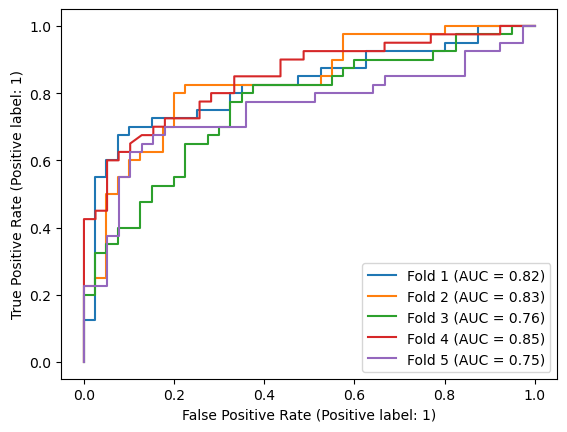

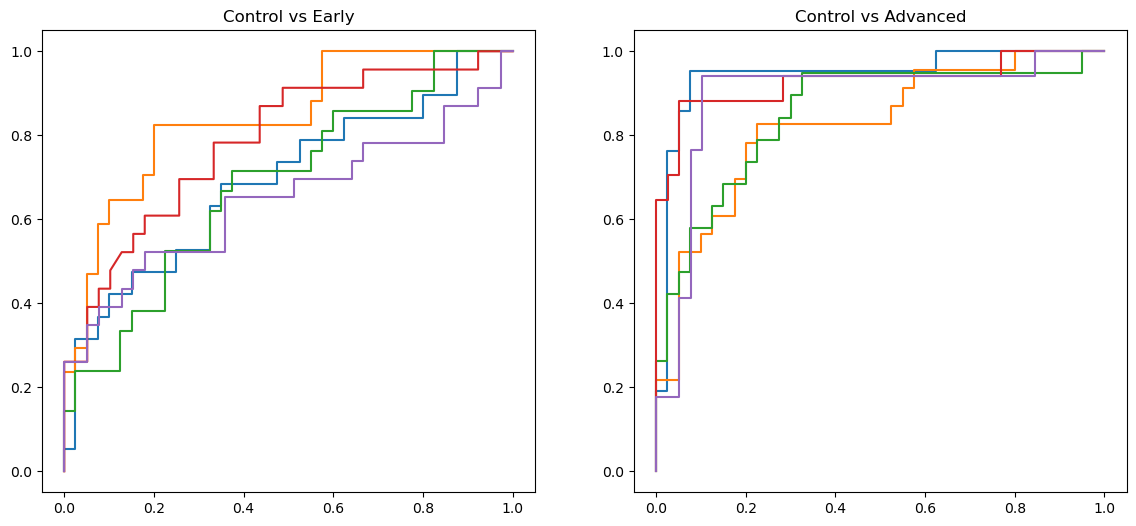

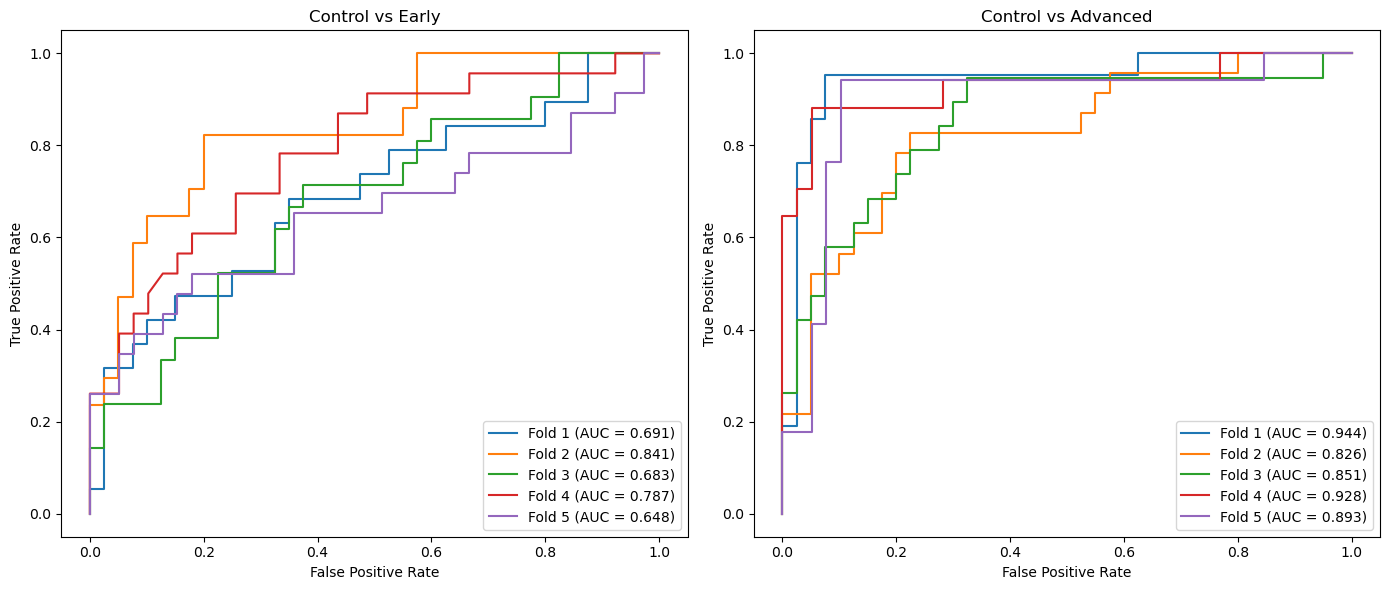


Control vs Early
各foldのAUC: [0.6908 0.8412 0.6833 0.7865 0.6477]
平均AUC: 0.7299
標準偏差: 0.0807

Control vs Advanced
各foldのAUC: [0.944  0.8261 0.8513 0.9276 0.8929]
平均AUC: 0.8884
標準偏差: 0.0498


,Fold,AUC,Accuracy,Sensitivity,Specificity,False Positive Rate,False Negative Rate,PPV,NPV
0,1,0.8238,0.8000,0.675,0.9250,0.0750,0.325,0.9000,0.7400
1,2,0.8325,0.7375,0.650,0.8250,0.1750,0.350,0.7879,0.7021
2,3,0.7631,0.7000,0.675,0.7250,0.2750,0.325,0.7105,0.6905
3,4,0.8465,0.7468,0.725,0.7692,0.2308,0.275,0.7632,0.7317
4,5,0.7519,0.6962,0.700,0.6923,0.3077,0.300,0.7000,0.6923


,Metric,Mean,SD
0,AUC,0.8036,0.0430
1,Accuracy,0.7361,0.0421
2,Sensitivity,0.6850,0.0285
3,Specificity,0.7873,0.0917
4,False Positive Rate,0.2127,0.0917
5,False Negative Rate,0.3150,0.0285
6,PPV,0.7723,0.0801
7,NPV,0.7113,0.0230


,Protein,Importance,SD_Importance
595,GP2,0.143689,0.073402
736,MUC16,0.036508,0.025553
357,ANXA10,0.027629,0.016629
498,CTRL,0.023615,0.012800
113,CFC1,0.022147,0.014526
734,MSTN,0.021511,0.024134
586,GFRA1,0.017205,0.013097
795,PNLIPRP1,0.014119,0.005064
536,Q14213_Q8NEV9*,0.010134,0.005301
765,NXPH3,0.009626,0.003781


結果を保存しました: ./RF_Data/RF_status_all


In [102]:
import time
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=123)
aucs = []
fig, ax = plt.subplots()

# ==========================================
# progress_group別ROC用の図
# ==========================================
fig_progress, axes_progress = plt.subplots(1, 2, figsize=(14, 6))

axes_progress[0].set_title("Control vs Early")
axes_progress[1].set_title("Control vs Advanced")

progress_auc = {
    "Early": [],
    "Advanced": []
}

# 各foldの予測結果を保存
y_prob_all = np.full(len(y), np.nan)
y_true_all = np.full(len(y), np.nan)
feature_importances = []

# 追加：各foldの評価指標・最適パラメータを保存
fold_metrics = []
best_params_all = []

save_dir = "./RF_Data/RF_status_all"
os.makedirs(save_dir, exist_ok=True)

for i, (train_index, test_index) in enumerate(skf.split(X, y)):

    X_train, X_test = X.iloc[train_index], X.iloc[test_index]
    y_train, y_test = y.iloc[train_index], y.iloc[test_index]

    param_grid = {
        'n_estimators': [50, 100, 300, 500],
        "max_depth": [None, 3, 5, 10, 15],
        'min_samples_leaf': [1, 2, 4],
        'max_features': [None, 'sqrt'],
        'class_weight': ['balanced']
    }
    # param_grid = {
    #     'n_estimators': [50],
    #     "max_depth": [10],
    #     'min_samples_leaf': [4],
    #     'max_features': ['sqrt'],
    #     'class_weight': ['balanced']
    # }

    model = RandomForestClassifier(
        criterion='gini',
        random_state=123,
        n_jobs=1
    )

    cv_gen = StratifiedKFold(n_splits=5, shuffle=True, random_state=123)

    modelcv = GridSearchCV(
        model,
        param_grid=param_grid,
        scoring='roc_auc',
        n_jobs=1,
        refit=True,
        cv=cv_gen,
        verbose=0,
        pre_dispatch='2*n_jobs',
        error_score=np.nan,
        return_train_score=False
    )

    start = time.time()
    modelcv.fit(X_train, y_train)
    elapsed = time.time() - start

    print(f"1回のGridSearchCV: {elapsed / 60:.2f} 分")
    print(f"全5 foldの推定時間: {elapsed * 5 / 60:.2f} 分")
    print('Best score: ', modelcv.best_score_)
    print('Best hyperparameters: ', modelcv.best_params_)

    # 追加：各foldの最適パラメータを保存
    best_params_all.append({
        "Fold": i + 1,
        "Best_Params": modelcv.best_params_
    })

    dataframe = pd.DataFrame(
        modelcv.cv_results_
    ).sort_values('mean_test_score', ascending=False)
    display(dataframe)

    model = modelcv.best_estimator_


    # Foldごとの学習済みモデルを保存
    joblib.dump(
        model,
        f"{save_dir}/rf_model_fold_{i+1}.joblib"
    )
    
    # Foldごとのテストデータを保存
    X_test.to_csv(
        f"{save_dir}/X_test_fold_{i+1}.csv",
        index=True
    )
    
    # テストデータの正解ラベルを保存
    y_test.to_csv(
        f"{save_dir}/y_test_fold_{i+1}.csv",
        index=True
    )
    
    # 特徴量名を保存
    pd.Series(X.columns).to_csv(
        f"{save_dir}/feature_names.csv",
        index=False,
        header=["Feature"]
    )

    # 予測確率とAUC
    y_prob = model.predict_proba(X_test)[:, 1]
    score = roc_auc_score(y_test, y_prob)
    aucs.append(score)


    # ==========================================
    # progress_group別ROC曲線
    # ==========================================

    # テストデータのprogress_groupを取得
    # pro_sampleとXは同じ行順であることを前提とする
    progress_test = (
        pro_sample["progress_group"]
        .iloc[test_index]
        .astype(str)
        .str.strip()
        .str.lower()
    )
    comparisons = [
        {"name": "Early", "positive": ["1", "early"], "ax": axes_progress[0]},
        {"name": "Advanced", "positive": ["2", "advanced", "advanced/metastatic"], "ax": axes_progress[1]}
    ]
    
    for comp in comparisons:
        mask = (
            progress_test.isin(["0", "control"]) |
            progress_test.isin(comp["positive"])
        )
    
        progress_labels = (
            progress_test[mask].isin(comp["positive"]).astype(int)
        )
        prob_subset = y_prob[mask.to_numpy()]
    
        if progress_labels.nunique() == 2:
            fpr, tpr, thresholds = roc_curve(
                progress_labels, prob_subset
            )
            auc_progress = roc_auc_score(
                progress_labels, prob_subset
            )
    
            # 各foldのAUCをlegendに表示
            comp["ax"].plot(
                fpr,
                tpr,
                label=f"Fold {i+1} (AUC = {auc_progress:.3f})"
            )
    
            progress_auc[comp["name"]].append(auc_progress)


    # OOF予測を保存
    y_prob_all[test_index] = y_prob
    y_true_all[test_index] = np.asarray(y_test)

    # 各foldの特徴量重要度
    feature_importances.append(model.feature_importances_)

    # 追加：各foldの評価指標を計算
    y_pred = (y_prob >= 0.5).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        y_test, y_pred, labels=[0, 1]
    ).ravel()

    fold_metrics.append({
        "Fold": i + 1,
        "AUC": score,
        "Accuracy": (tp + tn) / (tp + tn + fp + fn),
        "Sensitivity": tp / (tp + fn) if tp + fn else np.nan,
        "Specificity": tn / (tn + fp) if tn + fp else np.nan,
        "False Positive Rate": fp / (fp + tn) if fp + tn else np.nan,
        "False Negative Rate": fn / (fn + tp) if fn + tp else np.nan,
        "PPV": tp / (tp + fp) if tp + fp else np.nan,
        "NPV": tn / (tn + fn) if tn + fn else np.nan
    })

    print('AUC: ', score)

    RocCurveDisplay.from_predictions(
        y_test,
        y_prob,
        name=f"Fold {i+1}",
        ax=ax
    )

print(f"5-Fold平均AUC: {np.mean(aucs):.4f} ± {np.std(aucs, ddof=1):.4f}")
plt.show()
# ==========================================
# progress_group別ROC曲線を表示
# ==========================================

for ax in axes_progress:
    # ax.plot(
    #     [0, 1], [0, 1],
    #     linestyle="--",
    #     color="gray",
    #     label="Chance"
    # )
    # ax.set_xlim(0, 1)
    # ax.set_ylim(0, 1)
    ax.set_xlabel("False Positive Rate")
    ax.set_ylabel("True Positive Rate")
    ax.legend(loc="lower right")
    # ax.grid(alpha=0.3)

fig_progress.tight_layout()
display(fig_progress)
# ==========================================
# 各比較のfold別AUCと平均・標準偏差
# ==========================================

for group, values in progress_auc.items():

    print(f"\nControl vs {group}")

    if len(values) > 0:
        print("各foldのAUC:", np.round(values, 4))
        print(f"平均AUC: {np.mean(values):.4f}")
        print(
            f"標準偏差: "
            f"{np.std(values, ddof=1):.4f}"
            if len(values) > 1
            else "標準偏差: 算出不可（有効なfoldが1つ）"
        )
    else:
        print("ROCを計算できるfoldがありません。")
# ==========================================
# 全foldの予測結果を保存
# ==========================================
y_true_all = y_true_all.astype(int)
y_pred_all = (y_prob_all >= 0.5).astype(int)

oof_df = pd.DataFrame({
    "TrueClass": y_true_all,
    "PredictedProbability": y_prob_all,
    "PredictedClass": y_pred_all
}, index=X.index)

oof_df.index.name = "SampleID"
oof_df.to_csv(f"{save_dir}/oof_predictions.csv")

# ==========================================
# 各foldの評価指標と平均・標準偏差を保存
# ==========================================
fold_metrics_df = pd.DataFrame(fold_metrics)

# 各foldの結果
display(fold_metrics_df.round(4))
fold_metrics_df.to_csv(
    f"{save_dir}/metrics_each_fold.csv",
    index=False
)

# 5-foldの平均と標準偏差
metrics_df = pd.DataFrame({
    "Metric": fold_metrics_df.columns.drop("Fold"),
    "Mean": [
        fold_metrics_df[col].mean()
        for col in fold_metrics_df.columns.drop("Fold")
    ],
    "SD": [
        fold_metrics_df[col].std(ddof=1)
        for col in fold_metrics_df.columns.drop("Fold")
    ]
})

display(metrics_df.round(4))
metrics_df.to_csv(f"{save_dir}/metrics.csv", index=False)

# ==========================================
# foldごとの特徴量重要度の平均を保存
# ==========================================
importance_df = pd.DataFrame({
    "Protein": X.columns,
    "Importance": np.mean(feature_importances, axis=0),
    "SD_Importance": np.std(feature_importances, axis=0, ddof=1)
}).sort_values("Importance", ascending=False)

importance_df.to_csv(
    f"{save_dir}/feature_importance.csv",
    index=False
)

display(importance_df.head(20))

# ==========================================
# 各foldの最適パラメータ5つを保存
# ==========================================
with open(f"{save_dir}/best_parameters.json", "w") as f:
    json.dump(
        best_params_all,
        f,
        indent=2,
        default=str
    )

print("結果を保存しました:", save_dir)

In [103]:
import os
import joblib
import numpy as np
import pandas as pd
from sklearn.metrics import confusion_matrix, accuracy_score, roc_auc_score

save_dir = "./RF_Data/RF_status_all"

fold_metrics = []

for i in range(1, 6):

    # ==========================================
    # 保存済みファイルを読み込む
    # ==========================================
    model = joblib.load(
        f"{save_dir}/rf_model_fold_{i}.joblib"
    )

    X_test = pd.read_csv(
        f"{save_dir}/X_test_fold_{i}.csv",
        index_col=0
    )

    y_test = pd.read_csv(
        f"{save_dir}/y_test_fold_{i}.csv",
        index_col=0
    ).iloc[:, 0]

    # X_testのサンプル順に合わせてprogress_groupを取得
    progress_test = (
        pro_sample.loc[X_test.index, "progress_group"]
        .astype(str)
        .str.strip()
        .str.lower()
    )

    # ControlとEarlyだけを抽出
    control_mask = progress_test.isin(["0", "control"])
    early_mask = progress_test.isin(["1", "early"])
    mask = control_mask | early_mask

    X_sub = X_test.loc[mask]
    progress_sub = progress_test.loc[mask]

    # Control=0、Early=1
    y_true = early_mask.loc[mask].astype(int).to_numpy()

    # 保存済みモデルで予測（再学習なし）
    y_prob = model.predict_proba(X_sub)[:, 1]
    y_pred = (y_prob >= 0.5).astype(int)

    # ==========================================
    # 評価指標を計算
    # ==========================================
    tn, fp, fn, tp = confusion_matrix(
        y_true, y_pred, labels=[0, 1]
    ).ravel()

    fold_metrics.append({
        "Fold": i,
        "AUC": roc_auc_score(y_true, y_prob),
        "Accuracy": accuracy_score(y_true, y_pred),
        "Sensitivity": tp / (tp + fn) if tp + fn else np.nan,
        "Specificity": tn / (tn + fp) if tn + fp else np.nan
    })

# ==========================================
# Foldごとの結果
# ==========================================
metrics_df = pd.DataFrame(fold_metrics)
display(metrics_df.round(4))

# ==========================================
# 平均 ± SD
# ==========================================
summary = pd.DataFrame({
    "Mean": metrics_df.drop(columns="Fold").mean(),
    "SD": metrics_df.drop(columns="Fold").std(ddof=1)
})

summary["Mean ± SD"] = summary.apply(
    lambda row: f"{row['Mean']:.3f} ± {row['SD']:.3f}",
    axis=1
)

display(summary[["Mean ± SD"]])

,Fold,AUC,Accuracy,Sensitivity,Specificity
0,1,0.6908,0.7458,0.3684,0.9250
1,2,0.8412,0.7719,0.6471,0.8250
2,3,0.6833,0.6557,0.5238,0.7250
3,4,0.7865,0.7097,0.6087,0.7692
4,5,0.6477,0.6290,0.5217,0.6923


,Mean ± SD
AUC,0.730 ± 0.081
Accuracy,0.702 ± 0.060
Sensitivity,0.534 ± 0.107
Specificity,0.787 ± 0.092


### 偽陰性などチェック

,Fold,AUC,Accuracy,Sensitivity,Specificity,False Positive Rate,False Negative Rate,PPV,NPV
0,1,0.8494,0.7875,0.700,0.8750,0.1250,0.300,0.8485,0.7447
1,2,0.8194,0.7625,0.775,0.7500,0.2500,0.225,0.7561,0.7692
2,3,0.7763,0.7125,0.675,0.7500,0.2500,0.325,0.7297,0.6977
3,4,0.8167,0.7342,0.750,0.7179,0.2821,0.250,0.7317,0.7368
4,5,0.6859,0.6582,0.650,0.6667,0.3333,0.350,0.6667,0.6500


,Metric,Mean,SD
0,AUC,0.7895,0.0635
1,Accuracy,0.7310,0.0496
2,Sensitivity,0.7100,0.0518
3,Specificity,0.7519,0.0768
4,False Positive Rate,0.2481,0.0768
5,False Negative Rate,0.2900,0.0518
6,PPV,0.7465,0.0659
7,NPV,0.7197,0.0467


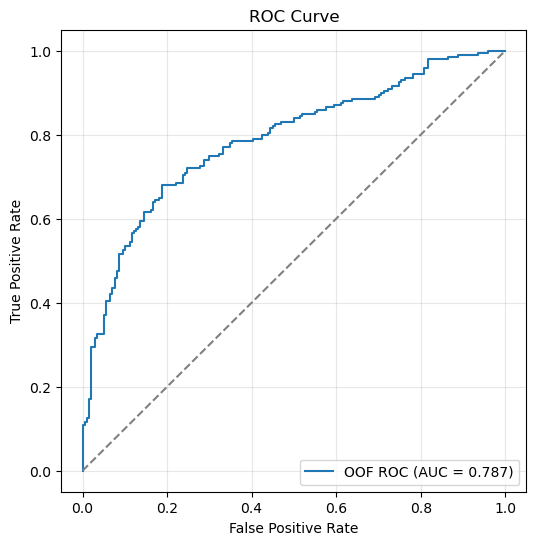

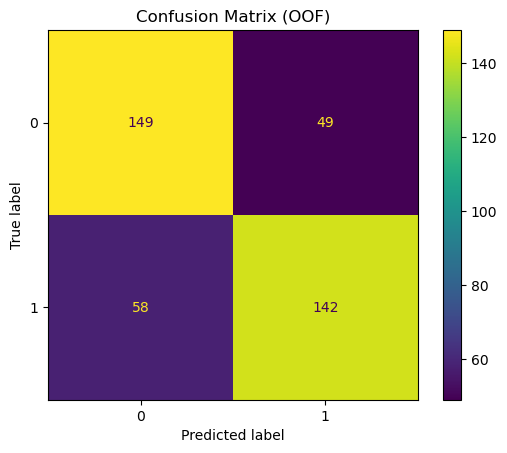

偽陽性（False Positive）: 49 samples


,TrueClass,PredictedProbability,PredictedClass
SampleID,,,
PE_R478_002,0,0.624143,1
PE_R478_011,0,0.541605,1
PE_R478_017,0,0.544447,1
PE_R478_027,0,0.585207,1
PE_R478_036,0,0.623177,1
PE_R478_040,0,0.531952,1
PE_R478_042,0,0.598525,1
PE_R478_055,0,0.519594,1
PE_R478_056,0,0.510874,1


偽陰性（False Negative）: 58 samples


,TrueClass,PredictedProbability,PredictedClass
SampleID,,,
PE_R478_008,1,0.430281,0
PE_R478_019,1,0.462493,0
PE_R478_021,1,0.406458,0
PE_R478_032,1,0.438290,0
PE_R478_037,1,0.249717,0
PE_R478_060,1,0.444233,0
PE_R478_063,1,0.462693,0
PE_R478_066,1,0.332713,0
PE_R478_077,1,0.480051,0


,Protein,Importance,SD_Importance
0,GP2,0.025408,0.001880
1,CTRL,0.016346,0.003977
2,MUC16,0.015260,0.005290
3,CTRC,0.012318,0.003805
4,LIFR,0.012166,0.002469
5,ANXA10,0.009835,0.003774
6,IL17A,0.009641,0.006361
7,NXPH3,0.009340,0.003184
8,PNLIPRP1,0.007528,0.003771
9,FKBP15,0.007432,0.005531


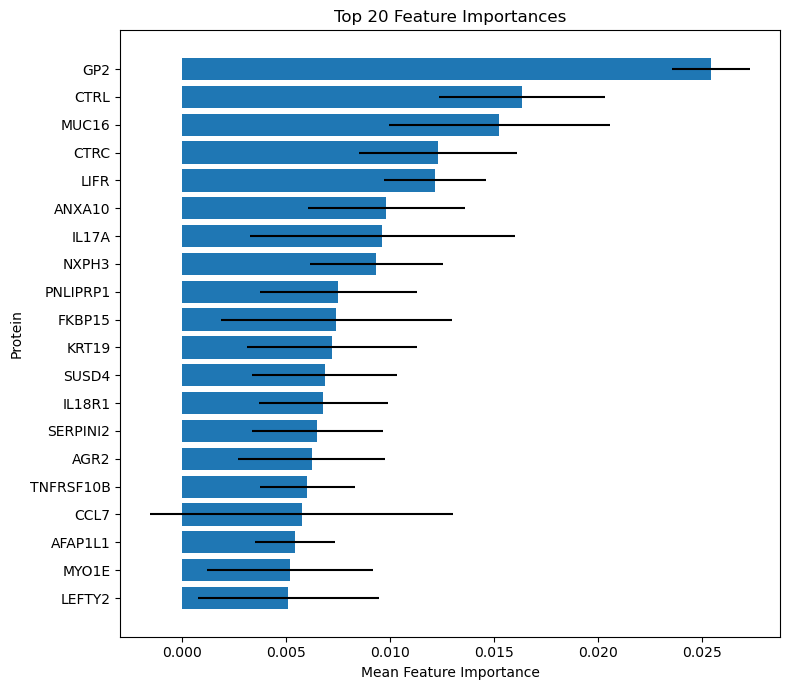

,Fold,class_weight,max_depth,max_features,min_samples_leaf,n_estimators
0,1,balanced,10,sqrt,4,50
1,2,balanced,10,sqrt,4,50
2,3,balanced,10,sqrt,4,50
3,4,balanced,10,sqrt,4,50
4,5,balanced,10,sqrt,4,50


In [14]:
import os
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import (
    roc_curve,
    roc_auc_score,
    confusion_matrix,
    ConfusionMatrixDisplay
)

save_dir = "./RF_Data/RF_status_all"

# ==========================================
# 1. 各foldの評価指標
# ==========================================
fold_metrics_df = pd.read_csv(
    f"{save_dir}/metrics_each_fold.csv"
)

display(fold_metrics_df.round(4))

# ==========================================
# 2. 5-foldの平均・標準偏差
# ==========================================
metrics_df = pd.read_csv(
    f"{save_dir}/metrics.csv"
)

display(metrics_df.round(4))

# ==========================================
# 3. ROC曲線（各foldのOOF予測から作成）
# ==========================================
oof_df = pd.read_csv(
    f"{save_dir}/oof_predictions.csv",
    index_col="SampleID"
)

y_true = oof_df["TrueClass"].to_numpy()
y_prob = oof_df["PredictedProbability"].to_numpy()
y_pred = oof_df["PredictedClass"].to_numpy()

fpr, tpr, thresholds = roc_curve(y_true, y_prob)
auc = roc_auc_score(y_true, y_prob)

plt.figure(figsize=(6, 6))
plt.plot(fpr, tpr, label=f"OOF ROC (AUC = {auc:.3f})")
plt.plot([0, 1], [0, 1], linestyle="--", color="gray")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve")
plt.legend(loc="lower right")
plt.grid(alpha=0.3)
plt.show()

# ==========================================
# 4. 混同行列
# ==========================================
cm = confusion_matrix(y_true, y_pred, labels=[0, 1])

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=[0, 1]
)
disp.plot()
plt.title("Confusion Matrix (OOF)")
plt.show()

# ==========================================
# 5. 偽陽性・偽陰性のサンプルを確認
# ==========================================
fp_df = oof_df[
    (oof_df["TrueClass"] == 0) &
    (oof_df["PredictedClass"] == 1)
]

fn_df = oof_df[
    (oof_df["TrueClass"] == 1) &
    (oof_df["PredictedClass"] == 0)
]

print("偽陽性（False Positive）:", len(fp_df), "samples")
display(fp_df)

print("偽陰性（False Negative）:", len(fn_df), "samples")
display(fn_df)

# 必要ならCSVとして個別に保存
fp_df.to_csv(f"{save_dir}/false_positive_samples.csv")
fn_df.to_csv(f"{save_dir}/false_negative_samples.csv")

# ==========================================
# 6. 特徴量重要度
# ==========================================
importance_df = pd.read_csv(
    f"{save_dir}/feature_importance.csv"
)

display(importance_df.head(20))

top_n = 20
top_features = importance_df.head(top_n).sort_values(
    "Importance", ascending=True
)

plt.figure(figsize=(8, 7))
plt.barh(
    top_features["Protein"],
    top_features["Importance"],
    xerr=top_features["SD_Importance"]
)
plt.xlabel("Mean Feature Importance")
plt.ylabel("Protein")
plt.title(f"Top {top_n} Feature Importances")
plt.tight_layout()
plt.show()

# ==========================================
# 7. 各foldの最適パラメータ
# ==========================================
with open(
    f"{save_dir}/best_parameters.json",
    "r"
) as f:
    best_params_all = json.load(f)

best_params_df = pd.DataFrame([
    {
        "Fold": item["Fold"],
        **item["Best_Params"]
    }
    for item in best_params_all
])

display(best_params_df)

### 進行度で分けてみる

OOF予測サンプル数: 398
結合後のサンプル数: 398

進行度別のサンプル数:
Stage
Control     198
Early       103
Advanced     97
Name: count, dtype: int64


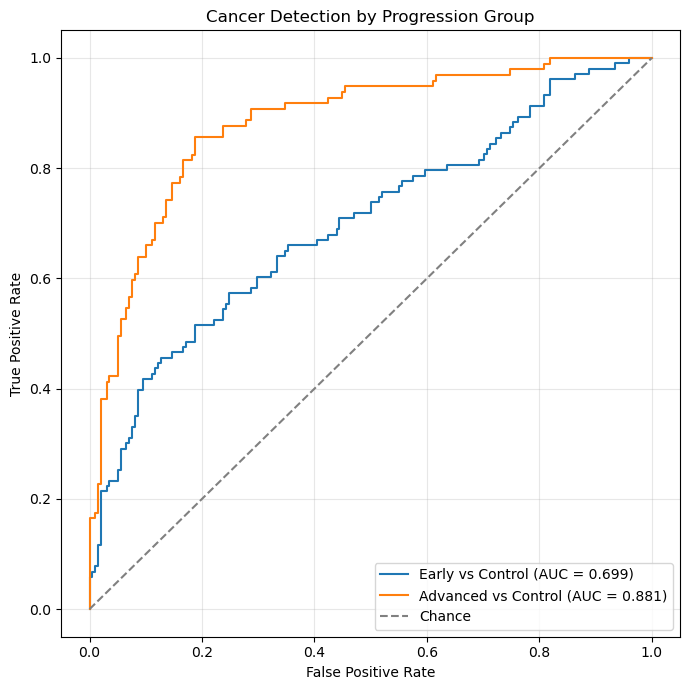

,Comparison,N_Control,N_Early,AUC,N_Advanced
0,Early vs Control,198,103.0,0.6991,NaN
1,Advanced vs Control,198,NaN,0.8812,97.0


In [15]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import roc_curve, roc_auc_score

# ==========================================
# 1. 保存済みのOOF予測結果を読み込む
# ==========================================
save_dir = "./RF_Data/RF_status_all"

oof_df = pd.read_csv(
    f"{save_dir}/oof_predictions.csv",
    index_col="SampleID"
)

# ==========================================
# 2. pro_sampleから進行度を結合
# ==========================================
meta = pro_sample.copy()

# SampleIDをインデックスに統一
if "SampleID" in meta.columns:
    meta = meta.set_index("SampleID")

# SampleIDを文字列に統一
oof_df.index = oof_df.index.astype(str)
meta.index = meta.index.astype(str)

# 予測結果とメタデータを結合
roc_df = oof_df.join(
    meta[["progress_group"]],
    how="inner"
)

print("OOF予測サンプル数:", len(oof_df))
print("結合後のサンプル数:", len(roc_df))

# ==========================================
# 3. 進行度をControl / Early / Advancedに分類
# ==========================================
pg = (
    roc_df["progress_group"]
    .astype(str)
    .str.strip()
    .str.lower()
)

stage = pd.Series(
    np.nan,
    index=roc_df.index,
    dtype="object"
)

# Control
stage.loc[pg.isin(["0"])] = "Control"

# Early
stage.loc[pg.isin(["1"])] = "Early"

# Advanced
stage.loc[pg.isin(["2"])] = "Advanced"

# progress_groupが欠損しているControlを補完
if "CaCo_Status" in meta.columns:
    control_ids = meta.index[
        pd.to_numeric(
            meta["CaCo_Status"], errors="coerce"
        ) == 0
    ]
    stage.loc[
        stage.index.isin(control_ids)
    ] = "Control"

roc_df["Stage"] = stage

print("\n進行度別のサンプル数:")
print(roc_df["Stage"].value_counts(dropna=False))

# ==========================================
# 4. Early vs Control / Advanced vs Control
# ==========================================
plt.figure(figsize=(7, 7))

results = []

for group in ["Early", "Advanced"]:

    # 対象群とControlだけを抽出
    subset = roc_df[
        roc_df["Stage"].isin(["Control", group])
    ].copy()

    # 陽性=対象群、陰性=Control
    y_true = (subset["Stage"] == group).astype(int)

    # 第1段階モデルのCancer予測確率
    y_score = subset["PredictedProbability"]


    fpr, tpr, thresholds = roc_curve(y_true, y_score)
    auc = roc_auc_score(y_true, y_score)

    plt.plot(
        fpr,
        tpr,
        label=f"{group} vs Control (AUC = {auc:.3f})"
    )

    results.append({
        "Comparison": f"{group} vs Control",
        "N_Control": int((subset["Stage"] == "Control").sum()),
        f"N_{group}": int((subset["Stage"] == group).sum()),
        "AUC": auc
    })

plt.plot(
    [0, 1], [0, 1],
    linestyle="--",
    color="gray",
    label="Chance"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("Cancer Detection by Progression Group")
plt.legend(loc="lower right")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# ==========================================
# 5. AUCとサンプル数を表示・保存
# ==========================================
results_df = pd.DataFrame(results)
display(results_df.round(4))




In [63]:
saved_assets = {
    'model': modelcv.best_estimator_
}
name = 'mdl_allpro.joblib'
save_dir = "./Data"
path = os.path.join(save_dir, name)
joblib.dump(saved_assets, path)

['./Data/mdl_allpro.joblib']

In [64]:

tempA = model.predict(X_test)
tempS = pd.Series(tempA, index = X_test.index, name = 'PredictedClass')
dataframe = y_test.rename('TrueClass')
dataframe = pd.merge(tempS, dataframe, left_index = True, right_index = True, how = 'left')

dataframe2 = pro_data.copy()
display(dataframe['TrueClass'].value_counts())
display(dataframe['PredictedClass'].value_counts())
display(dataframe.loc[dataframe['TrueClass']!=dataframe['PredictedClass']])


TrueClass
1    40
0    39
Name: count, dtype: int64

PredictedClass
0    41
1    38
Name: count, dtype: int64

,PredictedClass,TrueClass
PE_R478_036,1,0
PE_R478_037,0,1
PE_R478_053,1,0
PE_R478_060,0,1
PE_R478_063,0,1
PE_R478_089,0,1
PE_R478_092,1,0
PE_R478_119,0,1
PE_R478_122,0,1
PE_R478_127,1,0


### 120人での検証

In [65]:
import os
import joblib
import numpy as np
import pandas as pd

# 保存済みモデルの読み込み
path = "./Data/mdl_allpro.joblib"
saved_assets = joblib.load(path)

model = saved_assets["model"]

# データ
X = pro_data_dis.copy()
y = pro_sample_dis["groupset2"].copy()

print("X shape:", X.shape)
print("y shape:", y.shape)
print("モデル:", model)

X shape: (119, 1033)
y shape: (119,)
モデル: RandomForestClassifier(class_weight='balanced', max_depth=5, max_features=None,
                       min_samples_leaf=4, n_estimators=300, n_jobs=1,
                       random_state=123)


In [59]:
import os
import joblib
import numpy as np
import pandas as pd

from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    roc_auc_score,
    RocCurveDisplay
)
import matplotlib.pyplot as plt

# データセット
X = pro_data_dis.copy()
y = pro_sample_dis["groupset2"].copy()

# 保存済みモデルの読み込み
save_dir = "./Data"
name = "mdl_allpro.joblib"
path = os.path.join(save_dir, name)

saved_assets = joblib.load(path)
model = saved_assets["model"]

# 予測
y_pred = model.predict(X)

# 予測結果
print("Accuracy:", accuracy_score(y, y_pred))
print("\nConfusion matrix:")
print(confusion_matrix(y, y_pred))
print("\nClassification report:")
print(classification_report(y, y_pred))

# ROC-AUC（2クラス分類の場合）
if len(model.classes_) == 2:
    positive_class = 1
    positive_idx = list(model.classes_).index(positive_class)

    y_prob = model.predict_proba(X)[:, positive_idx]
    auc = roc_auc_score(y, y_prob)

    print(f"ROC-AUC: {auc:.4f}")

    RocCurveDisplay.from_predictions(y, y_prob)
    plt.title(f"ROC Curve (AUC = {auc:.3f})")
    plt.show()

# 予測結果を保存
results = pd.DataFrame({
    "Actual": y,
    "Predicted": y_pred
}, index=X.index)

if len(model.classes_) == 2:
    results["Predicted_probability_class1"] = y_prob

display(results.head())

ValueError: The feature names should match those that were passed during fit.
Feature names must be in the same order as they were in fit.


In [ ]:
# skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=123)
# aucs = []
# fig, ax = plt.subplots()

# for i, (train_index, test_index) in enumerate(skf.split(X, y)):
    
#     X_train, X_test = X.iloc[train_index], X.iloc[test_index]
#     y_train, y_test = y.iloc[train_index], y.iloc[test_index]
    
#     rf_model = RandomForestClassifier(
#         **grid_search.best_params_,
#         max_features="sqrt",
#         random_state=123,
#         class_weight="balanced",
#         n_jobs=-1
#     )
    
#     rf_model.fit(X_train, y_train)
    
#     print(rf_model)
    
#     y_prob = rf_model.predict_proba(X_test)[:, 1]
    
#     auc = roc_auc_score(y_test, y_prob)
#     aucs.append(auc)
    
#     print("AUC:", auc)
    
#     RocCurveDisplay.from_predictions(
#         y_test,
#         y_prob,
#         name=f"Fold {i+1}", ax=ax
#     )
    
# print(f"5-Fold平均AUC: {np.mean(aucs):.4f} ± {np.std(aucs)}")
# plt.show()

# importance_df = pd.DataFrame({
#     "Protein": X.columns,
#     "Importance": model.feature_importances_
# })
# importance_df = importance_df.sort_values(
#     "Importance",
#     ascending=False
# )
# print(importance_df.head(20))

In [ ]:
# skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=123)
# aucs = []
# fig, ax = plt.subplots()

# for i, (train_index, test_index) in enumerate(skf.split(X, y)):
#     X_train, X_test, y_train, y_test = train_test_split(
#         X,
#         y,
#         test_size=0.3,
#         random_state=123,
#         stratify=y
#     )
    
#     rf_model = RandomForestClassifier(
#         n_estimators=300,
#         max_features="sqrt",
#         random_state=123,
#         class_weight="balanced",
#         n_jobs=-1
#     )
    
#     rf_model.fit(X_train, y_train)
    
#     print(rf_model)
    
#     y_prob = rf_model.predict_proba(X_test)[:, 1]
    
#     auc = roc_auc_score(y_test, y_prob)
    
#     print("AUC:", auc)
    
#     RocCurveDisplay.from_predictions(
#         y_test,
#         y_prob,
#         name=f"Fold {i+1}", ax=ax
#     )
    
# print(f"5-Fold平均AUC: {np.mean(aucs):.4f} ± {np.std(aucs)}")
# plt.show()

In [ ]:
# importance_df = pd.DataFrame({
#     "Protein": X.columns,
#     "Importance": rf_model.feature_importances_
# })
# importance_df = importance_df.sort_values(
#     "Importance",
#     ascending=False
# )
# print(importance_df.head(20))

## ②DEP listのもののみver

In [ ]:
display(DEPlist)

In [79]:
X = pro_data.loc[:, pro_data.columns.isin(DEPlist.index)]
y = pro_sample["CaCo_Status"]

print(DEPlist.shape)
print(X.shape)
print(y.shape)

print(X.index[:5])
print(y.index[:5])

(24, 7)
(398, 24)
(398,)
Index(['PE_R478_001', 'PE_R478_002', 'PE_R478_003', 'PE_R478_004',
       'PE_R478_005'],
      dtype='object', name='SampleID')
Index(['PE_R478_001', 'PE_R478_002', 'PE_R478_003', 'PE_R478_004',
       'PE_R478_005'],
      dtype='object')


1回のGridSearchCV: 3.90 分
全5 foldの推定時間: 19.52 分
Best score:  0.8337197580645161
Best hyperparameters:  {'class_weight': 'balanced', 'max_depth': 5, 'max_features': 'sqrt', 'min_samples_leaf': 1, 'n_estimators': 300}


,mean_fit_time,std_fit_time,mean_score_time,std_score_time,param_class_weight,param_max_depth,param_max_features,param_min_samples_leaf,param_n_estimators,params,split0_test_score,split1_test_score,split2_test_score,split3_test_score,split4_test_score,mean_test_score,std_test_score,rank_test_score
62,0.286802,0.003315,0.013913,0.000493,balanced,5,sqrt,1,300,"{'class_weight': 'balanced', 'max_depth': 5, '...",0.892578,0.696289,0.872070,0.865927,0.841734,0.833720,0.070603,1
110,0.315303,0.008880,0.013703,0.000240,balanced,15,sqrt,1,300,"{'class_weight': 'balanced', 'max_depth': 15, ...",0.881348,0.707031,0.875977,0.864415,0.837198,0.833194,0.064895,2
14,0.318918,0.005778,0.013923,0.000558,balanced,None,sqrt,1,300,"{'class_weight': 'balanced', 'max_depth': None...",0.881348,0.706543,0.875000,0.863911,0.837198,0.832800,0.064909,3
86,0.317853,0.010180,0.013737,0.000189,balanced,10,sqrt,1,300,"{'class_weight': 'balanced', 'max_depth': 10, ...",0.877930,0.703125,0.868164,0.878024,0.836694,0.832787,0.066578,4
111,0.525678,0.009716,0.022056,0.000792,balanced,15,sqrt,1,500,"{'class_weight': 'balanced', 'max_depth': 15, ...",0.878418,0.710449,0.872070,0.862903,0.837198,0.832208,0.062477,5
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
35,0.805492,0.010092,0.020654,0.000219,balanced,3,None,4,500,"{'class_weight': 'balanced', 'max_depth': 3, '...",0.865234,0.698242,0.853516,0.839718,0.825605,0.816463,0.060584,116
1,0.269745,0.006215,0.006018,0.000403,balanced,None,None,1,100,"{'class_weight': 'balanced', 'max_depth': None...",0.848633,0.723145,0.851074,0.833669,0.822581,0.815820,0.047482,117
97,0.267326,0.011157,0.005650,0.000052,balanced,15,None,1,100,"{'class_weight': 'balanced', 'max_depth': 15, ...",0.848633,0.723145,0.851074,0.833165,0.822581,0.815720,0.047444,118
24,0.082659,0.001161,0.003633,0.000043,balanced,3,None,1,50,"{'class_weight': 'balanced', 'max_depth': 3, '...",0.853516,0.702148,0.857422,0.826613,0.835685,0.815077,0.057587,119


AUC:  0.87625
1回のGridSearchCV: 3.87 分
全5 foldの推定時間: 19.35 分
Best score:  0.838801033266129
Best hyperparameters:  {'class_weight': 'balanced', 'max_depth': None, 'max_features': 'sqrt', 'min_samples_leaf': 1, 'n_estimators': 100}


,mean_fit_time,std_fit_time,mean_score_time,std_score_time,param_class_weight,param_max_depth,param_max_features,param_min_samples_leaf,param_n_estimators,params,split0_test_score,split1_test_score,split2_test_score,split3_test_score,split4_test_score,mean_test_score,std_test_score,rank_test_score
13,0.104993,0.000576,0.005617,0.000030,balanced,None,sqrt,1,100,"{'class_weight': 'balanced', 'max_depth': None...",0.851562,0.849609,0.909668,0.863407,0.719758,0.838801,0.063370,1
109,0.105396,0.000769,0.005758,0.000067,balanced,15,sqrt,1,100,"{'class_weight': 'balanced', 'max_depth': 15, ...",0.850098,0.850098,0.910156,0.863407,0.719758,0.838703,0.063440,2
85,0.110553,0.002803,0.006188,0.000353,balanced,10,sqrt,1,100,"{'class_weight': 'balanced', 'max_depth': 10, ...",0.864258,0.838867,0.910156,0.852823,0.715726,0.836366,0.064891,3
118,0.302724,0.007121,0.014280,0.000638,balanced,15,sqrt,4,300,"{'class_weight': 'balanced', 'max_depth': 15, ...",0.838867,0.856445,0.924805,0.857863,0.694556,0.834507,0.075876,4
22,0.291132,0.000861,0.013602,0.000134,balanced,None,sqrt,4,300,"{'class_weight': 'balanced', 'max_depth': None...",0.838867,0.856445,0.924805,0.857863,0.694556,0.834507,0.075876,4
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
24,0.081051,0.000613,0.003629,0.000069,balanced,3,None,1,50,"{'class_weight': 'balanced', 'max_depth': 3, '...",0.768555,0.840820,0.900391,0.839718,0.654234,0.800743,0.084328,116
29,0.164504,0.004381,0.005695,0.000265,balanced,3,None,2,100,"{'class_weight': 'balanced', 'max_depth': 3, '...",0.762695,0.849609,0.902344,0.834677,0.653226,0.800510,0.086106,117
28,0.085029,0.003418,0.004034,0.000272,balanced,3,None,2,50,"{'class_weight': 'balanced', 'max_depth': 3, '...",0.769531,0.844727,0.900391,0.829637,0.649194,0.798696,0.085580,118
33,0.157216,0.001290,0.005533,0.000036,balanced,3,None,4,100,"{'class_weight': 'balanced', 'max_depth': 3, '...",0.757812,0.840820,0.904297,0.829637,0.655242,0.797562,0.085003,119


AUC:  0.8621875
1回のGridSearchCV: 3.90 分
全5 foldの推定時間: 19.50 分
Best score:  0.8374432963709676
Best hyperparameters:  {'class_weight': 'balanced', 'max_depth': None, 'max_features': 'sqrt', 'min_samples_leaf': 4, 'n_estimators': 100}


...

AUC:  0.811875
1回のGridSearchCV: 3.97 分
全5 foldの推定時間: 19.83 分
Best score:  0.8423387096774194
Best hyperparameters:  {'class_weight': 'balanced', 'max_depth': 5, 'max_features': 'sqrt', 'min_samples_leaf': 1, 'n_estimators': 300}


,mean_fit_time,std_fit_time,mean_score_time,std_score_time,param_class_weight,param_max_depth,param_max_features,param_min_samples_leaf,param_n_estimators,params,split0_test_score,split1_test_score,split2_test_score,split3_test_score,split4_test_score,mean_test_score,std_test_score,rank_test_score
62,0.290560,0.007671,0.013965,0.000612,balanced,5,sqrt,1,300,"{'class_weight': 'balanced', 'max_depth': 5, '...",0.844727,0.833008,0.871094,0.826172,0.836694,0.842339,0.015575,1
92,0.049802,0.000596,0.003702,0.000048,balanced,10,sqrt,4,50,"{'class_weight': 'balanced', 'max_depth': 10, ...",0.814453,0.856445,0.877930,0.829102,0.832661,0.842118,0.022414,2
19,0.518826,0.010656,0.021859,0.000340,balanced,None,sqrt,2,500,"{'class_weight': 'balanced', 'max_depth': None...",0.828125,0.847656,0.876953,0.827148,0.827621,0.841501,0.019351,3
115,0.514583,0.007588,0.021798,0.000279,balanced,15,sqrt,2,500,"{'class_weight': 'balanced', 'max_depth': 15, ...",0.828125,0.847656,0.876953,0.827148,0.827621,0.841501,0.019351,3
70,0.282876,0.006880,0.014188,0.000716,balanced,5,sqrt,4,300,"{'class_weight': 'balanced', 'max_depth': 5, '...",0.839844,0.838867,0.873047,0.825195,0.829637,0.841318,0.016801,5
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
96,0.134666,0.002336,0.003761,0.000066,balanced,15,None,1,50,"{'class_weight': 'balanced', 'max_depth': 15, ...",0.801270,0.784180,0.833008,0.823242,0.798387,0.808017,0.017680,116
100,0.130942,0.005207,0.003926,0.000202,balanced,15,None,2,50,"{'class_weight': 'balanced', 'max_depth': 15, ...",0.812500,0.787109,0.855469,0.795898,0.784274,0.807050,0.026134,117
4,0.133184,0.007872,0.004100,0.000267,balanced,None,None,2,50,"{'class_weight': 'balanced', 'max_depth': None...",0.812500,0.787109,0.855469,0.795898,0.784274,0.807050,0.026134,117
76,0.127967,0.004679,0.003829,0.000116,balanced,10,None,2,50,"{'class_weight': 'balanced', 'max_depth': 10, ...",0.808594,0.784180,0.854492,0.796875,0.786290,0.806086,0.025714,119


AUC:  0.8307692307692308
1回のGridSearchCV: 3.90 分
全5 foldの推定時間: 19.48 分
Best score:  0.8478767641129032
Best hyperparameters:  {'class_weight': 'balanced', 'max_depth': 10, 'max_features': 'sqrt', 'min_samples_leaf': 2, 'n_estimators': 100}


,mean_fit_time,std_fit_time,mean_score_time,std_score_time,param_class_weight,param_max_depth,param_max_features,param_min_samples_leaf,param_n_estimators,params,split0_test_score,split1_test_score,split2_test_score,split3_test_score,split4_test_score,mean_test_score,std_test_score,rank_test_score
89,0.101883,0.000616,0.005753,0.000076,balanced,10,sqrt,2,100,"{'class_weight': 'balanced', 'max_depth': 10, ...",0.881836,0.835938,0.830078,0.812500,0.879032,0.847877,0.027694,1
119,0.491639,0.006039,0.022017,0.000856,balanced,15,sqrt,4,500,"{'class_weight': 'balanced', 'max_depth': 15, ...",0.875977,0.835938,0.829102,0.831055,0.865927,0.847600,0.019458,2
23,0.484465,0.007579,0.021613,0.000357,balanced,None,sqrt,4,500,"{'class_weight': 'balanced', 'max_depth': None...",0.875977,0.835938,0.829102,0.831055,0.865927,0.847600,0.019458,2
70,0.285056,0.007982,0.013792,0.000438,balanced,5,sqrt,4,300,"{'class_weight': 'balanced', 'max_depth': 5, '...",0.877930,0.831055,0.819336,0.832031,0.873992,0.846869,0.024202,4
95,0.490340,0.013575,0.021697,0.000340,balanced,10,sqrt,4,500,"{'class_weight': 'balanced', 'max_depth': 10, ...",0.875977,0.835938,0.828125,0.829102,0.864919,0.846812,0.019797,5
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
73,0.267746,0.012810,0.005905,0.000251,balanced,10,None,1,100,"{'class_weight': 'balanced', 'max_depth': 10, ...",0.876465,0.778320,0.795898,0.788574,0.826613,0.813174,0.035510,116
0,0.132740,0.001681,0.003845,0.000163,balanced,None,None,1,50,"{'class_weight': 'balanced', 'max_depth': None...",0.880371,0.795898,0.784668,0.777344,0.824597,0.812576,0.037521,117
96,0.129292,0.003499,0.003822,0.000082,balanced,15,None,1,50,"{'class_weight': 'balanced', 'max_depth': 15, ...",0.880371,0.795898,0.784668,0.777344,0.824597,0.812576,0.037521,117
1,0.269129,0.007315,0.005890,0.000221,balanced,None,None,1,100,"{'class_weight': 'balanced', 'max_depth': None...",0.877441,0.783203,0.782227,0.784668,0.826613,0.810830,0.037288,119


AUC:  0.7698717948717949
5-Fold平均AUC: 0.8302 ± 0.0422


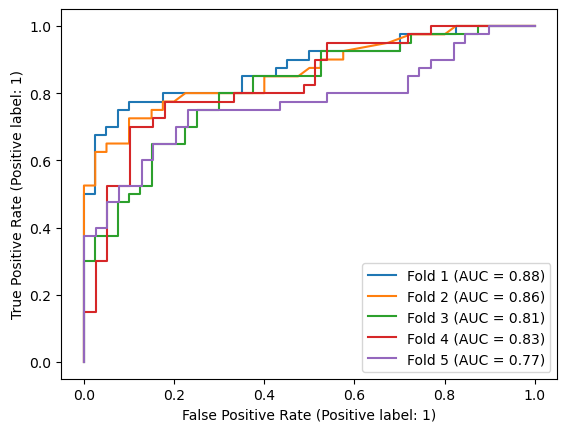

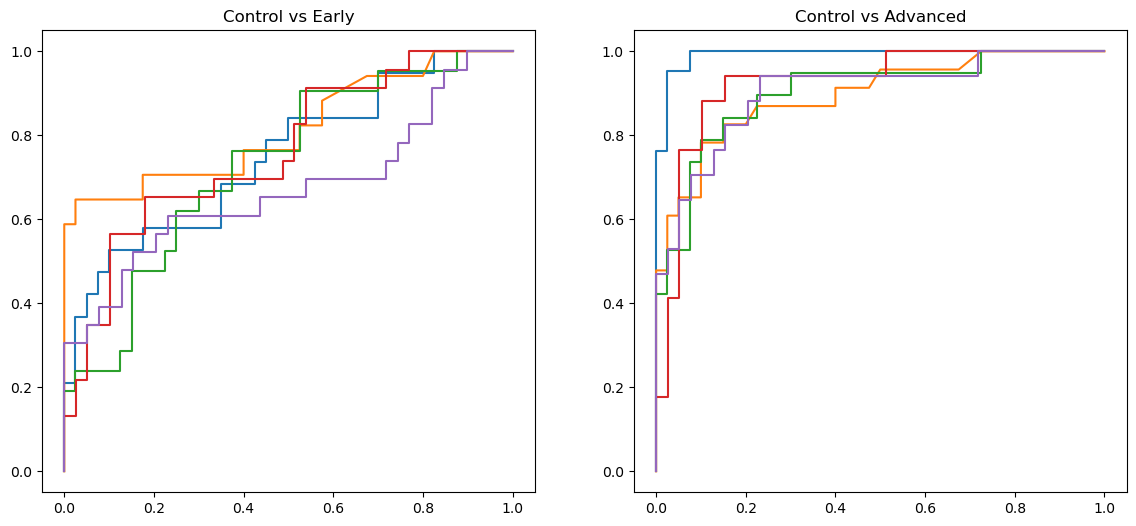

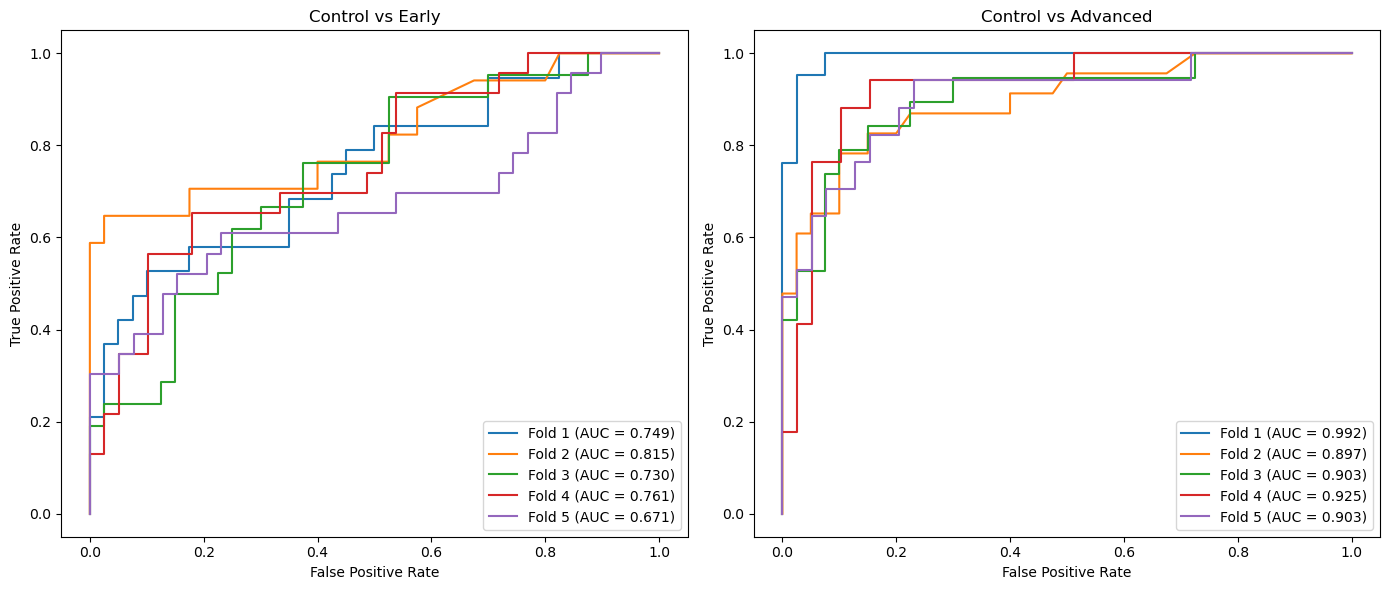


Control vs Early
各foldのAUC: [0.7487 0.8154 0.7298 0.7614 0.6711]
平均AUC: 0.7453
標準偏差: 0.0523

Control vs Advanced
各foldのAUC: [0.9917 0.8967 0.9026 0.9246 0.9035]
平均AUC: 0.9238
標準偏差: 0.0394


,Fold,AUC,Accuracy,Sensitivity,Specificity,False Positive Rate,False Negative Rate,PPV,NPV
0,1,0.8762,0.8250,0.675,0.9750,0.0250,0.325,0.9643,0.7500
1,2,0.8622,0.8000,0.750,0.8500,0.1500,0.250,0.8333,0.7727
2,3,0.8119,0.7250,0.675,0.7750,0.2250,0.325,0.7500,0.7045
3,4,0.8308,0.7975,0.775,0.8205,0.1795,0.225,0.8158,0.7805
4,5,0.7699,0.7468,0.725,0.7692,0.2308,0.275,0.7632,0.7317


,Metric,Mean,SD
0,AUC,0.8302,0.0422
1,Accuracy,0.7789,0.0414
2,Sensitivity,0.7200,0.0447
3,Specificity,0.8379,0.0835
4,False Positive Rate,0.1621,0.0835
5,False Negative Rate,0.2800,0.0447
6,PPV,0.8253,0.0852
7,NPV,0.7479,0.0309


,Protein,Importance,SD_Importance
13,GP2,0.113696,0.014886
17,MUC16,0.074129,0.014215
10,CTRL,0.060474,0.004459
18,PNLIPRP1,0.058912,0.011471
6,ANXA10,0.058438,0.010633
22,TMPRSS15,0.045253,0.011006
20,S100A12,0.044324,0.009040
16,KRT19,0.043997,0.005278
21,SERPINI2,0.041315,0.007850
7,CCL20,0.039838,0.007201


結果を保存しました: ./RF_Data/RF_status_DEP


In [80]:
import time
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=123)
aucs = []
fig, ax = plt.subplots()

# ==========================================
# progress_group別ROC用の図
# ==========================================
fig_progress, axes_progress = plt.subplots(1, 2, figsize=(14, 6))

axes_progress[0].set_title("Control vs Early")
axes_progress[1].set_title("Control vs Advanced")

progress_auc = {
    "Early": [],
    "Advanced": []
}

# 各foldの予測結果を保存
y_prob_all = np.full(len(y), np.nan)
y_true_all = np.full(len(y), np.nan)
feature_importances = []

# 追加：各foldの評価指標・最適パラメータを保存
fold_metrics = []
best_params_all = []

save_dir = "./RF_Data/RF_status_DEP"
os.makedirs(save_dir, exist_ok=True)

for i, (train_index, test_index) in enumerate(skf.split(X, y)):

    X_train, X_test = X.iloc[train_index], X.iloc[test_index]
    y_train, y_test = y.iloc[train_index], y.iloc[test_index]

    param_grid = {
        'n_estimators': [50, 100, 300, 500],
        "max_depth": [None, 3, 5, 10, 15],
        'min_samples_leaf': [1, 2, 4],
        'max_features': [None, 'sqrt'],
        'class_weight': ['balanced']
    }
    # param_grid = {
    #     'n_estimators': [50],
    #     "max_depth": [10],
    #     'min_samples_leaf': [4],
    #     'max_features': ['sqrt'],
    #     'class_weight': ['balanced']
    # }

    model = RandomForestClassifier(
        criterion='gini',
        random_state=123,
        n_jobs=1
    )

    cv_gen = StratifiedKFold(n_splits=5, shuffle=True, random_state=123)

    modelcv = GridSearchCV(
        model,
        param_grid=param_grid,
        scoring='roc_auc',
        n_jobs=1,
        refit=True,
        cv=cv_gen,
        verbose=0,
        pre_dispatch='2*n_jobs',
        error_score=np.nan,
        return_train_score=False
    )

    start = time.time()
    modelcv.fit(X_train, y_train)
    elapsed = time.time() - start

    print(f"1回のGridSearchCV: {elapsed / 60:.2f} 分")
    print(f"全5 foldの推定時間: {elapsed * 5 / 60:.2f} 分")
    print('Best score: ', modelcv.best_score_)
    print('Best hyperparameters: ', modelcv.best_params_)

    # 追加：各foldの最適パラメータを保存
    best_params_all.append({
        "Fold": i + 1,
        "Best_Params": modelcv.best_params_
    })

    dataframe = pd.DataFrame(
        modelcv.cv_results_
    ).sort_values('mean_test_score', ascending=False)
    display(dataframe)

    model = modelcv.best_estimator_


    # Foldごとの学習済みモデルを保存
    joblib.dump(
        model,
        f"{save_dir}/rf_model_fold_{i+1}.joblib"
    )
    
    # Foldごとのテストデータを保存
    X_test.to_csv(
        f"{save_dir}/X_test_fold_{i+1}.csv",
        index=True
    )
    
    # テストデータの正解ラベルを保存
    y_test.to_csv(
        f"{save_dir}/y_test_fold_{i+1}.csv",
        index=True
    )
    
    # 特徴量名を保存
    pd.Series(X.columns).to_csv(
        f"{save_dir}/feature_names.csv",
        index=False,
        header=["Feature"]
    )

    # 予測確率とAUC
    y_prob = model.predict_proba(X_test)[:, 1]
    score = roc_auc_score(y_test, y_prob)
    aucs.append(score)


    # ==========================================
    # progress_group別ROC曲線
    # ==========================================

    # テストデータのprogress_groupを取得
    # pro_sampleとXは同じ行順であることを前提とする
    progress_test = (
        pro_sample["progress_group"]
        .iloc[test_index]
        .astype(str)
        .str.strip()
        .str.lower()
    )
    comparisons = [
        {"name": "Early", "positive": ["1", "early"], "ax": axes_progress[0]},
        {"name": "Advanced", "positive": ["2", "advanced", "advanced/metastatic"], "ax": axes_progress[1]}
    ]
    
    for comp in comparisons:
        mask = (
            progress_test.isin(["0", "control"]) |
            progress_test.isin(comp["positive"])
        )
    
        progress_labels = (
            progress_test[mask].isin(comp["positive"]).astype(int)
        )
        prob_subset = y_prob[mask.to_numpy()]
    
        if progress_labels.nunique() == 2:
            fpr, tpr, thresholds = roc_curve(
                progress_labels, prob_subset
            )
            auc_progress = roc_auc_score(
                progress_labels, prob_subset
            )
    
            # 各foldのAUCをlegendに表示
            comp["ax"].plot(
                fpr,
                tpr,
                label=f"Fold {i+1} (AUC = {auc_progress:.3f})"
            )
    
            progress_auc[comp["name"]].append(auc_progress)


    # OOF予測を保存
    y_prob_all[test_index] = y_prob
    y_true_all[test_index] = np.asarray(y_test)

    # 各foldの特徴量重要度
    feature_importances.append(model.feature_importances_)

    # 追加：各foldの評価指標を計算
    y_pred = (y_prob >= 0.5).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        y_test, y_pred, labels=[0, 1]
    ).ravel()

    fold_metrics.append({
        "Fold": i + 1,
        "AUC": score,
        "Accuracy": (tp + tn) / (tp + tn + fp + fn),
        "Sensitivity": tp / (tp + fn) if tp + fn else np.nan,
        "Specificity": tn / (tn + fp) if tn + fp else np.nan,
        "False Positive Rate": fp / (fp + tn) if fp + tn else np.nan,
        "False Negative Rate": fn / (fn + tp) if fn + tp else np.nan,
        "PPV": tp / (tp + fp) if tp + fp else np.nan,
        "NPV": tn / (tn + fn) if tn + fn else np.nan
    })

    print('AUC: ', score)

    RocCurveDisplay.from_predictions(
        y_test,
        y_prob,
        name=f"Fold {i+1}",
        ax=ax
    )

print(f"5-Fold平均AUC: {np.mean(aucs):.4f} ± {np.std(aucs, ddof=1):.4f}")
plt.show()
# ==========================================
# progress_group別ROC曲線を表示
# ==========================================

for ax in axes_progress:
    # ax.plot(
    #     [0, 1], [0, 1],
    #     linestyle="--",
    #     color="gray",
    #     label="Chance"
    # )
    # ax.set_xlim(0, 1)
    # ax.set_ylim(0, 1)
    ax.set_xlabel("False Positive Rate")
    ax.set_ylabel("True Positive Rate")
    ax.legend(loc="lower right")
    # ax.grid(alpha=0.3)

fig_progress.tight_layout()
display(fig_progress)
# ==========================================
# 各比較のfold別AUCと平均・標準偏差
# ==========================================

for group, values in progress_auc.items():

    print(f"\nControl vs {group}")

    if len(values) > 0:
        print("各foldのAUC:", np.round(values, 4))
        print(f"平均AUC: {np.mean(values):.4f}")
        print(
            f"標準偏差: "
            f"{np.std(values, ddof=1):.4f}"
            if len(values) > 1
            else "標準偏差: 算出不可（有効なfoldが1つ）"
        )
    else:
        print("ROCを計算できるfoldがありません。")
# ==========================================
# 全foldの予測結果を保存
# ==========================================
y_true_all = y_true_all.astype(int)
y_pred_all = (y_prob_all >= 0.5).astype(int)

oof_df = pd.DataFrame({
    "TrueClass": y_true_all,
    "PredictedProbability": y_prob_all,
    "PredictedClass": y_pred_all
}, index=X.index)

oof_df.index.name = "SampleID"
oof_df.to_csv(f"{save_dir}/oof_predictions.csv")

# ==========================================
# 各foldの評価指標と平均・標準偏差を保存
# ==========================================
fold_metrics_df = pd.DataFrame(fold_metrics)

# 各foldの結果
display(fold_metrics_df.round(4))
fold_metrics_df.to_csv(
    f"{save_dir}/metrics_each_fold.csv",
    index=False
)

# 5-foldの平均と標準偏差
metrics_df = pd.DataFrame({
    "Metric": fold_metrics_df.columns.drop("Fold"),
    "Mean": [
        fold_metrics_df[col].mean()
        for col in fold_metrics_df.columns.drop("Fold")
    ],
    "SD": [
        fold_metrics_df[col].std(ddof=1)
        for col in fold_metrics_df.columns.drop("Fold")
    ]
})

display(metrics_df.round(4))
metrics_df.to_csv(f"{save_dir}/metrics.csv", index=False)

# ==========================================
# foldごとの特徴量重要度の平均を保存
# ==========================================
importance_df = pd.DataFrame({
    "Protein": X.columns,
    "Importance": np.mean(feature_importances, axis=0),
    "SD_Importance": np.std(feature_importances, axis=0, ddof=1)
}).sort_values("Importance", ascending=False)

importance_df.to_csv(
    f"{save_dir}/feature_importance.csv",
    index=False
)

display(importance_df.head(20))

# ==========================================
# 各foldの最適パラメータ5つを保存
# ==========================================
with open(f"{save_dir}/best_parameters.json", "w") as f:
    json.dump(
        best_params_all,
        f,
        indent=2,
        default=str
    )

print("結果を保存しました:", save_dir)

In [88]:
import os
import joblib
import numpy as np
import pandas as pd
from sklearn.metrics import confusion_matrix, accuracy_score, roc_auc_score

save_dir = "./RF_Data/RF_status_DEP"

fold_metrics = []

for i in range(1, 6):

    # ==========================================
    # 保存済みファイルを読み込む
    # ==========================================
    model = joblib.load(
        f"{save_dir}/rf_model_fold_{i}.joblib"
    )

    X_test = pd.read_csv(
        f"{save_dir}/X_test_fold_{i}.csv",
        index_col=0
    )

    y_test = pd.read_csv(
        f"{save_dir}/y_test_fold_{i}.csv",
        index_col=0
    ).iloc[:, 0]

    # X_testのサンプル順に合わせてprogress_groupを取得
    progress_test = (
        pro_sample.loc[X_test.index, "progress_group"]
        .astype(str)
        .str.strip()
        .str.lower()
    )

    # ControlとEarlyだけを抽出
    control_mask = progress_test.isin(["0", "control"])
    early_mask = progress_test.isin(["1", "early"])
    mask = control_mask | early_mask

    X_sub = X_test.loc[mask]
    progress_sub = progress_test.loc[mask]

    # Control=0、Early=1
    y_true = early_mask.loc[mask].astype(int).to_numpy()

    # 保存済みモデルで予測（再学習なし）
    y_prob = model.predict_proba(X_sub)[:, 1]
    y_pred = (y_prob >= 0.5).astype(int)

    # ==========================================
    # 評価指標を計算
    # ==========================================
    tn, fp, fn, tp = confusion_matrix(
        y_true, y_pred, labels=[0, 1]
    ).ravel()

    fold_metrics.append({
        "Fold": i,
        "AUC": roc_auc_score(y_true, y_prob),
        "Accuracy": accuracy_score(y_true, y_pred),
        "Sensitivity": tp / (tp + fn) if tp + fn else np.nan,
        "Specificity": tn / (tn + fp) if tn + fp else np.nan
    })

# ==========================================
# Foldごとの結果
# ==========================================
metrics_df = pd.DataFrame(fold_metrics)
display(metrics_df.round(4))

# ==========================================
# 平均 ± SD
# ==========================================
summary = pd.DataFrame({
    "Mean": metrics_df.drop(columns="Fold").mean(),
    "SD": metrics_df.drop(columns="Fold").std(ddof=1)
})

summary["Mean ± SD"] = summary.apply(
    lambda row: f"{row['Mean']:.3f} ± {row['SD']:.3f}",
    axis=1
)

display(summary[["Mean ± SD"]])

,Fold,AUC,Accuracy,Sensitivity,Specificity
0,1,0.7487,0.7797,0.3684,0.9750
1,2,0.8154,0.7895,0.6471,0.8500
2,3,0.7298,0.6721,0.4762,0.7750
3,4,0.7614,0.7581,0.6522,0.8205
4,5,0.6711,0.7097,0.6087,0.7692


,Mean ± SD
AUC,0.745 ± 0.052
Accuracy,0.742 ± 0.050
Sensitivity,0.551 ± 0.124
Specificity,0.838 ± 0.084


/opt/conda/lib/python3.11/site-packages/pandas/core/computation/expressions.py:23: UserWarning: Pandas requires version '2.10.2' or newer of 'numexpr' (version '2.8.7' currently installed).
  from pandas.core.computation.check import NUMEXPR_INSTALLED
/opt/conda/lib/python3.11/site-packages/pandas/core/computation/expressions.py:23: UserWarning: Pandas requires version '2.10.2' or newer of 'numexpr' (version '2.8.7' currently installed).
  from pandas.core.computation.check import NUMEXPR_INSTALLED
/opt/conda/lib/python3.11/site-packages/pandas/core/computation/expressions.py:23: UserWarning: Pandas requires version '2.10.2' or newer of 'numexpr' (version '2.8.7' currently installed).
  from pandas.core.computation.check import NUMEXPR_INSTALLED
/opt/conda/lib/python3.11/site-packages/pandas/core/computation/expressions.py:23: UserWarning: Pandas requires version '2.10.2' or newer of 'numexpr' (version '2.8.7' currently installed).
  from pandas.core.computation.check import NUMEXPR_IN

1回のGridSearchCV: 3.95 分
全5 foldの推定時間: 19.77 分
Best score:  0.8365612399193548
Best hyperparameters:  {'class_weight': 'balanced', 'max_depth': 10, 'max_features': None, 'min_samples_leaf': 2, 'n_estimators': 100}


,mean_fit_time,std_fit_time,mean_score_time,std_score_time,param_class_weight,param_max_depth,param_max_features,param_min_samples_leaf,param_n_estimators,params,split0_test_score,split1_test_score,split2_test_score,split3_test_score,split4_test_score,mean_test_score,std_test_score,rank_test_score
39,0.301378,0.149946,0.010915,0.002362,balanced,10,NaN,2,100,"{'class_weight': 'balanced', 'max_depth': 10, ...",0.872070,0.727539,0.858398,0.892137,0.832661,0.836561,0.057840,1
57,0.234832,0.007116,0.009998,0.000392,balanced,15,NaN,2,100,"{'class_weight': 'balanced', 'max_depth': 15, ...",0.873047,0.725586,0.860352,0.888609,0.832661,0.836051,0.058199,2
3,0.238077,0.007931,0.009948,0.000363,balanced,None,NaN,2,100,"{'class_weight': 'balanced', 'max_depth': None...",0.873047,0.725586,0.860352,0.888609,0.832661,0.836051,0.058199,2
40,0.722471,0.049202,0.021946,0.000744,balanced,10,NaN,2,300,"{'class_weight': 'balanced', 'max_depth': 10, ...",0.869141,0.730469,0.857422,0.882056,0.823589,0.832535,0.054606,4
36,11.962102,3.376557,1.528684,0.653959,balanced,10,NaN,1,100,"{'class_weight': 'balanced', 'max_depth': 10, ...",0.865234,0.724121,0.864258,0.871976,0.831653,0.831448,0.055461,5
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
27,0.129247,0.004885,0.009910,0.000326,balanced,5,sqrt,1,100,"{'class_weight': 'balanced', 'max_depth': 5, '...",0.862305,0.690430,0.853516,0.854839,0.838710,0.819960,0.065215,68
44,45.328296,22.144896,1.803490,0.168630,balanced,10,NaN,4,500,"{'class_weight': 'balanced', 'max_depth': 10, ...",0.865234,0.727539,0.847656,0.851815,0.806452,0.819739,0.050111,69
8,1.056806,0.022311,0.033835,0.000654,balanced,None,NaN,4,500,"{'class_weight': 'balanced', 'max_depth': None...",0.865234,0.727539,0.847656,0.849798,0.807460,0.819538,0.049808,70
62,3.627332,5.175801,1.034054,0.546817,balanced,15,NaN,4,500,"{'class_weight': 'balanced', 'max_depth': 15, ...",0.865234,0.727539,0.847656,0.849798,0.807460,0.819538,0.049808,70


AUC:  0.8581249999999999
1回のGridSearchCV: 4.44 分
全5 foldの推定時間: 22.20 分
Best score:  0.8358870967741936
Best hyperparameters:  {'class_weight': 'balanced', 'max_depth': None, 'max_features': 'sqrt', 'min_samples_leaf': 2, 'n_estimators': 500}


,mean_fit_time,std_fit_time,mean_score_time,std_score_time,param_class_weight,param_max_depth,param_max_features,param_min_samples_leaf,param_n_estimators,params,split0_test_score,split1_test_score,split2_test_score,split3_test_score,split4_test_score,mean_test_score,std_test_score,rank_test_score
68,0.634976,0.005170,0.033556,0.000548,balanced,15,sqrt,2,500,"{'class_weight': 'balanced', 'max_depth': 15, ...",0.832031,0.867188,0.925781,0.847782,0.706653,0.835887,0.071998,1
14,0.673630,0.014368,0.034057,0.000348,balanced,None,sqrt,2,500,"{'class_weight': 'balanced', 'max_depth': None...",0.832031,0.867188,0.925781,0.847782,0.706653,0.835887,0.071998,1
67,0.382037,0.004288,0.021686,0.000264,balanced,15,sqrt,2,300,"{'class_weight': 'balanced', 'max_depth': 15, ...",0.832031,0.862305,0.925781,0.851815,0.697581,0.833902,0.075042,3
13,0.392512,0.007608,0.025081,0.005632,balanced,None,sqrt,2,300,"{'class_weight': 'balanced', 'max_depth': None...",0.832031,0.862305,0.925781,0.851815,0.697581,0.833902,0.075042,3
50,0.642133,0.015397,0.034141,0.001143,balanced,10,sqrt,2,500,"{'class_weight': 'balanced', 'max_depth': 10, ...",0.829102,0.861328,0.922852,0.849798,0.704637,0.833543,0.071622,5
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
54,0.253697,0.007204,0.009874,0.000164,balanced,15,NaN,1,100,"{'class_weight': 'balanced', 'max_depth': 15, ...",0.802734,0.864258,0.874512,0.846774,0.674899,0.812635,0.073114,68
18,0.207903,0.003335,0.009833,0.000559,balanced,5,NaN,1,100,"{'class_weight': 'balanced', 'max_depth': 5, '...",0.789062,0.863281,0.891602,0.841734,0.668347,0.810805,0.078747,69
57,0.231867,0.007500,0.010148,0.000903,balanced,15,NaN,2,100,"{'class_weight': 'balanced', 'max_depth': 15, ...",0.801758,0.858398,0.873047,0.850302,0.657762,0.808254,0.078957,70
3,2.947459,0.974486,0.518530,0.252384,balanced,None,NaN,2,100,"{'class_weight': 'balanced', 'max_depth': None...",0.801758,0.858398,0.873047,0.850302,0.657762,0.808254,0.078957,70


...

AUC:  0.805625
1回のGridSearchCV: 0.87 分
全5 foldの推定時間: 4.34 分
Best score:  0.8428742439516128
Best hyperparameters:  {'class_weight': 'balanced', 'max_depth': 5, 'max_features': 'sqrt', 'min_samples_leaf': 1, 'n_estimators': 300}


,mean_fit_time,std_fit_time,mean_score_time,std_score_time,param_class_weight,param_max_depth,param_max_features,param_min_samples_leaf,param_n_estimators,params,split0_test_score,split1_test_score,split2_test_score,split3_test_score,split4_test_score,mean_test_score,std_test_score,rank_test_score
28,0.395098,0.032738,0.023097,0.002221,balanced,5,sqrt,1,300,"{'class_weight': 'balanced', 'max_depth': 5, '...",0.850586,0.836914,0.867188,0.831055,0.828629,0.842874,0.014344,1
68,0.633665,0.006988,0.036178,0.004766,balanced,15,sqrt,2,500,"{'class_weight': 'balanced', 'max_depth': 15, ...",0.838867,0.846680,0.875000,0.826172,0.823589,0.842061,0.018494,2
14,0.691360,0.025496,0.034192,0.001053,balanced,None,sqrt,2,500,"{'class_weight': 'balanced', 'max_depth': None...",0.838867,0.846680,0.875000,0.826172,0.823589,0.842061,0.018494,2
50,0.703100,0.036945,0.034357,0.001102,balanced,10,sqrt,2,500,"{'class_weight': 'balanced', 'max_depth': 10, ...",0.838867,0.848633,0.874023,0.826172,0.821573,0.841854,0.018692,4
29,0.669137,0.037396,0.033218,0.000197,balanced,5,sqrt,1,500,"{'class_weight': 'balanced', 'max_depth': 5, '...",0.843750,0.838867,0.862305,0.829102,0.834677,0.841740,0.011356,5
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
37,0.806202,0.048998,0.021454,0.000189,balanced,10,NaN,1,300,"{'class_weight': 'balanced', 'max_depth': 10, ...",0.821289,0.810547,0.839844,0.791016,0.799395,0.812418,0.017100,68
18,0.204639,0.002558,0.009528,0.000102,balanced,5,NaN,1,100,"{'class_weight': 'balanced', 'max_depth': 5, '...",0.798828,0.812500,0.846680,0.792969,0.800403,0.810276,0.019278,69
54,0.243089,0.005400,0.010338,0.001270,balanced,15,NaN,1,100,"{'class_weight': 'balanced', 'max_depth': 15, ...",0.803223,0.822266,0.845215,0.784180,0.792843,0.809545,0.021893,70
0,0.253390,0.019532,0.010946,0.000926,balanced,None,NaN,1,100,"{'class_weight': 'balanced', 'max_depth': None...",0.803223,0.822266,0.843750,0.784180,0.792843,0.809252,0.021418,71


AUC:  0.8358974358974359
1回のGridSearchCV: 0.85 分
全5 foldの推定時間: 4.27 分
Best score:  0.8515435987903226
Best hyperparameters:  {'class_weight': 'balanced', 'max_depth': None, 'max_features': 'sqrt', 'min_samples_leaf': 4, 'n_estimators': 100}


,mean_fit_time,std_fit_time,mean_score_time,std_score_time,param_class_weight,param_max_depth,param_max_features,param_min_samples_leaf,param_n_estimators,params,split0_test_score,split1_test_score,split2_test_score,split3_test_score,split4_test_score,mean_test_score,std_test_score,rank_test_score
15,0.151638,0.038615,0.010221,0.000708,balanced,None,sqrt,4,100,"{'class_weight': 'balanced', 'max_depth': None...",0.896484,0.846680,0.811523,0.831055,0.871976,0.851544,0.029941,1
69,0.134666,0.011012,0.011693,0.002991,balanced,15,sqrt,4,100,"{'class_weight': 'balanced', 'max_depth': 15, ...",0.896484,0.846680,0.811523,0.831055,0.871976,0.851544,0.029941,1
51,0.128042,0.002312,0.009792,0.000104,balanced,10,sqrt,4,100,"{'class_weight': 'balanced', 'max_depth': 10, ...",0.896484,0.846680,0.811523,0.833008,0.869960,0.851531,0.029420,3
48,0.129692,0.000573,0.009740,0.000074,balanced,10,sqrt,2,100,"{'class_weight': 'balanced', 'max_depth': 10, ...",0.896484,0.842773,0.825195,0.819336,0.867944,0.850347,0.028601,4
53,0.676766,0.058984,0.033303,0.000271,balanced,10,sqrt,4,500,"{'class_weight': 'balanced', 'max_depth': 10, ...",0.883789,0.832031,0.830078,0.828125,0.869960,0.848797,0.023371,5
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
56,1.181541,0.054715,0.033297,0.000324,balanced,15,NaN,1,500,"{'class_weight': 'balanced', 'max_depth': 15, ...",0.871094,0.814941,0.792480,0.801270,0.853327,0.826622,0.030449,68
2,1.193754,0.031130,0.033345,0.000316,balanced,None,NaN,1,500,"{'class_weight': 'balanced', 'max_depth': None...",0.871094,0.814941,0.792480,0.801270,0.853327,0.826622,0.030449,68
36,0.267711,0.020879,0.013311,0.006127,balanced,10,NaN,1,100,"{'class_weight': 'balanced', 'max_depth': 10, ...",0.868164,0.815918,0.775391,0.800293,0.851815,0.822316,0.033764,70
54,0.241975,0.008223,0.010097,0.000853,balanced,15,NaN,1,100,"{'class_weight': 'balanced', 'max_depth': 15, ...",0.869141,0.811035,0.777832,0.796387,0.854335,0.821746,0.034625,71


AUC:  0.7775641025641026
5-Fold平均AUC: 0.8291 ± 0.03352200886095034


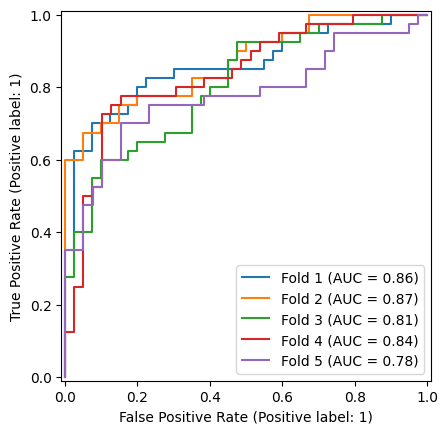

     Protein  Importance
13       GP2    0.099329
17     MUC16    0.081467
6     ANXA10    0.073266
20   S100A12    0.066062
10      CTRL    0.056046
18  PNLIPRP1    0.053977
22  TMPRSS15    0.049008
11     CXCL8    0.044913
21  SERPINI2    0.043632
8       CCL7    0.042213
15       IL6    0.041171
12     DPP10    0.036012
7      CCL20    0.034910
5       AGR2    0.033791
0      MYO1E    0.033566
19     REG3G    0.028702
2    CEACAM5    0.028140
1       ALPI    0.027357
16     KRT19    0.026505
4      IL17A    0.022347


['./Data/mdl_DEPlist']

In [72]:
import time
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=123)
aucs = []
fig, ax = plt.subplots()
modelsets_HER_DEP = []

for i, (train_index, test_index) in enumerate(skf.split(X, y)):
    
    X_train, X_test = X.iloc[train_index], X.iloc[test_index]
    y_train, y_test = y.iloc[train_index], y.iloc[test_index]

# X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=123)
    param_grid = {
        'n_estimators': [100, 300, 500],
        "max_depth": [None, 5, 10, 15],
        # 'min_samples_split': [2, 3, 4],
        'min_samples_leaf': [1, 2, 4],
        'max_features': [None, 'sqrt'],
        'class_weight': ['balanced']
    }

    model = RandomForestClassifier(
        criterion='gini',
        random_state=123,
        # class_weight='balanced',
        n_jobs=1 
    )
    
    cv_gen = StratifiedKFold(n_splits=5, shuffle=True, random_state=123)
    
    modelcv = GridSearchCV(
        model, 
        param_grid=param_grid,
        scoring='roc_auc',
        n_jobs=-1, 
        refit=True, 
        cv=cv_gen,
        verbose=0, 
        pre_dispatch='2*n_jobs', 
        error_score=np.nan, 
        return_train_score=False
    )

    start = time.time()
    # 訓練の実行
    modelcv.fit(X_train, y_train)
    elapsed = time.time() - start
    print(f"1回のGridSearchCV: {elapsed / 60:.2f} 分")
    print(f"全5 foldの推定時間: {elapsed * 5 / 60:.2f} 分")

    print('Best score: ', modelcv.best_score_)
    print('Best hyperparameters: ', modelcv.best_params_)
    dataframe = pd.DataFrame(modelcv.cv_results_).sort_values('mean_test_score', ascending=False)
    display(dataframe)
    
    model = modelcv.best_estimator_
    modelsets_HER_DEP.append(model)


    y_prob = model.predict_proba(X_test)[:, 1]
    score = roc_auc_score(y_test, y_prob)
    aucs.append(score)

    print('AUC: ', score)
    
    RocCurveDisplay.from_predictions(
        y_test,
        y_prob,
        name=f"Fold {i+1}", ax=ax
    )
    
print(f"5-Fold平均AUC: {np.mean(aucs):.4f} ± {np.std(aucs)}")
plt.show()

importance_df = pd.DataFrame({
    "Protein": X.columns,
    "Importance": model.feature_importances_
})
importance_df = importance_df.sort_values(
    "Importance",
    ascending=False
)
print(importance_df.head(20))

saved_assets = {
    'model': modelcv.best_estimator_
}
name = 'mdl_DEPlist'
save_dir = "./Data"
path = os.path.join(save_dir, name)
joblib.dump(saved_assets, path)

/opt/conda/lib/python3.11/site-packages/pandas/core/computation/expressions.py:23: UserWarning: Pandas requires version '2.10.2' or newer of 'numexpr' (version '2.8.7' currently installed).
  from pandas.core.computation.check import NUMEXPR_INSTALLED
/opt/conda/lib/python3.11/site-packages/pandas/core/computation/expressions.py:23: UserWarning: Pandas requires version '2.10.2' or newer of 'numexpr' (version '2.8.7' currently installed).
  from pandas.core.computation.check import NUMEXPR_INSTALLED
/opt/conda/lib/python3.11/site-packages/pandas/core/computation/expressions.py:23: UserWarning: Pandas requires version '2.10.2' or newer of 'numexpr' (version '2.8.7' currently installed).
  from pandas.core.computation.check import NUMEXPR_INSTALLED
/opt/conda/lib/python3.11/site-packages/pandas/core/computation/expressions.py:23: UserWarning: Pandas requires version '2.10.2' or newer of 'numexpr' (version '2.8.7' currently installed).
  from pandas.core.computation.check import NUMEXPR_IN

KeyboardInterrupt: 

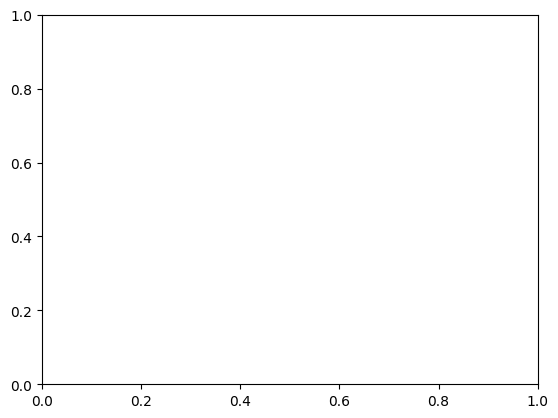

In [68]:
modelsets_HER_DEP = []

skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=123)
aucs = []
fig, ax = plt.subplots()

for i, (train_index, test_index) in enumerate(skf.split(X, y)):
    
    X_train, X_test = X.iloc[train_index], X.iloc[test_index]
    y_train, y_test = y.iloc[train_index], y.iloc[test_index]

# X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=123)
    param_grid = {
        'n_estimators': [100, 300, 500],
        "max_depth": [None, 5, 10, 15],
        # 'min_samples_split': [2, 3, 4],
        'min_samples_leaf': [1, 2, 4],
        'max_features': [None, 'sqrt'],
        'class_weight': ['balanced']
    }

    model = RandomForestClassifier(
        criterion='gini',
        random_state=123,
        # class_weight='balanced',
        n_jobs=1 
    )
    
    cv_gen = StratifiedKFold(n_splits=5, shuffle=True, random_state=123)
    
    modelcv = GridSearchCV(
        model, 
        param_grid=param_grid,
        scoring='roc_auc',
        n_jobs=-1, 
        refit=True, 
        cv=cv_gen,
        verbose=0, 
        pre_dispatch='2*n_jobs', 
        error_score=np.nan, 
        return_train_score=False
    )
    
    # 実行
    modelcv.fit(X_train, y_train)
    
    print('Best score: ', modelcv.best_score_)
    print('Best hyperparameters: ', modelcv.best_params_)
    dataframe = pd.DataFrame(modelcv.cv_results_).sort_values('mean_test_score', ascending=False)
    display(dataframe)
    
    model = modelcv.best_estimator_
    modelsets_HER_DEP.append(model)


    y_prob = model.predict_proba(X_test)[:, 1]
    score = roc_auc_score(y_test, y_prob)
    aucs.append(score)

    print('AUC: ', score)
    
    RocCurveDisplay.from_predictions(
        y_test,
        y_prob,
        name=f"Fold {i+1}", ax=ax
    )
    
print(f"5-Fold平均AUC: {np.mean(aucs):.4f} ± {np.std(aucs)}")
plt.show()

importance_df = pd.DataFrame({
    "Protein": X.columns,
    "Importance": model.feature_importances_
})
importance_df = importance_df.sort_values(
    "Importance",
    ascending=False
)
print(importance_df.head(20))

saved_assets = {
    'model': modelcv.best_estimator_
}
name = 'mdl_DEPlist'
save_dir = "./Data"
path = os.path.join(save_dir, name)
joblib.dump(saved_assets, path)

### 120人の方で検証

In [ ]:
X = pro_data_dis.loc[:, pro_data_dis.columns.isin(DEPlist.index)]

y = pro_sample_dis['groupset2']
print(X.shape)
print(y.shape)

print(X.index[:5])
print(y.index[:5])

In [ ]:
val_probs = []
val_aucs = []

fig, ax = plt.subplots()

for i, model in enumerate(modelsets_HER_DEP):

    y_val = model.predict_proba(X)[:, 1]
    val_probs.append(y_val)

    auc_val = roc_auc_score(y, y_val)
    val_aucs.append(auc_val) 

    print(f"Fold {i+1} Validation AUC: {auc_val:.4f}")

    RocCurveDisplay.from_predictions(
        y,
        y_val,
        name=f"Fold {i+1} (AUC = {auc_val:.3f})",
        ax=ax
    )

# 5モデルの予測確率を平均
val_probs = np.array(val_probs)
y_val_mean = val_probs.mean(axis=0)

# Ensemble AUC
auc_mean = roc_auc_score(y, y_val_mean)

# 平均予測のROC
RocCurveDisplay.from_predictions(
    y,
    y_val_mean,
    name=f"Mean prediction (AUC = {auc_mean:.3f})",
    ax=ax
)
# 5モデルのAUCの平均と標準偏差
auc_val_mean = np.mean(val_aucs)
auc_val_sd = np.std(val_aucs, ddof=1)

print(f"Validation AUC: {auc_val_mean:.4f} ± {auc_val_sd:.4f}")

ax.plot([0, 1], [0, 1], linestyle="--")

ax.set_title("Validation ROC curves")
plt.show()


print(f"Ensemble Validation AUC: {auc_mean:.4f}")

# CA-19-9とIL2RAのモデル

## CA-19-9とIL2RAのデータ読み込み

In [20]:
ca199 = pro_sample[['CA19_9']].copy()
display(ca199)

il2ra = pro_sample[['sIL2R']].copy()
display(il2ra)

,CA19_9
PE_R478_001,4.100
PE_R478_002,1.999
PE_R478_003,2.700
PE_R478_004,3.800
PE_R478_005,1200.000
...,...
PE_R478_396,1.999
PE_R478_397,1.999
PE_R478_398,2.100
PE_R478_399,16.900


,sIL2R
PE_R478_001,134.0
PE_R478_002,5500.0
PE_R478_003,259.0
PE_R478_004,208.0
PE_R478_005,1181.0
...,...
PE_R478_396,263.0
PE_R478_397,257.0
PE_R478_398,257.0
PE_R478_399,216.0


In [21]:
print((ca199['CA19_9'] <= 0).sum())
print((il2ra['sIL2R'] <= 0).sum())

0
0


In [22]:
ca199['logvalue'] = np.log10(ca199['CA19_9'])
il2ra['logvalue'] = np.log10(il2ra['sIL2R'])


## CA-19-9単独

In [90]:
X = ca199[["logvalue"]]
y = pro_sample["CaCo_Status"]

print(X.shape)
print(y.shape)

print(X.index[:5])
print(y.index[:5])

(398, 1)
(398,)
Index(['PE_R478_001', 'PE_R478_002', 'PE_R478_003', 'PE_R478_004',
       'PE_R478_005'],
      dtype='object', name='SampleID')
Index(['PE_R478_001', 'PE_R478_002', 'PE_R478_003', 'PE_R478_004',
       'PE_R478_005'],
      dtype='object')


1回のGridSearchCV: 1.89 分
全5 foldの推定時間: 9.46 分
Best score:  0.8032100554435484
Best hyperparameters:  {'class_weight': 'balanced', 'max_depth': 3, 'max_features': None, 'min_samples_leaf': 4, 'n_estimators': 500}


,mean_fit_time,std_fit_time,mean_score_time,std_score_time,param_class_weight,param_max_depth,param_max_features,param_min_samples_leaf,param_n_estimators,params,split0_test_score,split1_test_score,split2_test_score,split3_test_score,split4_test_score,mean_test_score,std_test_score,rank_test_score
35,0.357839,0.007860,0.020548,0.000337,balanced,3,None,4,500,"{'class_weight': 'balanced', 'max_depth': 3, '...",0.762207,0.815430,0.815430,0.798387,0.824597,0.803210,0.022184,1
47,0.358571,0.004444,0.021136,0.000969,balanced,3,sqrt,4,500,"{'class_weight': 'balanced', 'max_depth': 3, '...",0.762207,0.815430,0.815430,0.798387,0.824597,0.803210,0.022184,1
34,0.212391,0.000788,0.012916,0.000109,balanced,3,None,4,300,"{'class_weight': 'balanced', 'max_depth': 3, '...",0.760254,0.816406,0.812500,0.802923,0.823085,0.803034,0.022363,3
46,0.215567,0.005864,0.013131,0.000458,balanced,3,sqrt,4,300,"{'class_weight': 'balanced', 'max_depth': 3, '...",0.760254,0.816406,0.812500,0.802923,0.823085,0.803034,0.022363,3
33,0.071052,0.000360,0.005422,0.000081,balanced,3,None,4,100,"{'class_weight': 'balanced', 'max_depth': 3, '...",0.762695,0.811523,0.812012,0.801915,0.824093,0.802448,0.021085,5
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
13,0.079632,0.002669,0.005926,0.000390,balanced,None,sqrt,1,100,"{'class_weight': 'balanced', 'max_depth': None...",0.689453,0.755371,0.834961,0.794355,0.778226,0.770473,0.048128,115
85,0.077075,0.000885,0.005626,0.000052,balanced,10,sqrt,1,100,"{'class_weight': 'balanced', 'max_depth': 10, ...",0.690918,0.767578,0.821777,0.792339,0.778226,0.770168,0.043606,117
73,0.075851,0.000302,0.005597,0.000057,balanced,10,None,1,100,"{'class_weight': 'balanced', 'max_depth': 10, ...",0.690918,0.767578,0.821777,0.792339,0.778226,0.770168,0.043606,117
109,0.077551,0.000808,0.005591,0.000058,balanced,15,sqrt,1,100,"{'class_weight': 'balanced', 'max_depth': 15, ...",0.685547,0.756348,0.830566,0.795363,0.780242,0.769613,0.048445,119


AUC:  0.8106249999999999
1回のGridSearchCV: 1.89 分
全5 foldの推定時間: 9.43 分
Best score:  0.8070217993951614
Best hyperparameters:  {'class_weight': 'balanced', 'max_depth': 3, 'max_features': None, 'min_samples_leaf': 1, 'n_estimators': 100}


,mean_fit_time,std_fit_time,mean_score_time,std_score_time,param_class_weight,param_max_depth,param_max_features,param_min_samples_leaf,param_n_estimators,params,split0_test_score,split1_test_score,split2_test_score,split3_test_score,split4_test_score,mean_test_score,std_test_score,rank_test_score
37,0.073744,0.001281,0.005681,0.000267,balanced,3,sqrt,1,100,"{'class_weight': 'balanced', 'max_depth': 3, '...",0.889160,0.849121,0.876465,0.696069,0.724294,0.807022,0.080617,1
25,0.073568,0.002020,0.005713,0.000285,balanced,3,None,1,100,"{'class_weight': 'balanced', 'max_depth': 3, '...",0.889160,0.849121,0.876465,0.696069,0.724294,0.807022,0.080617,1
32,0.036682,0.000141,0.003657,0.000086,balanced,3,None,4,50,"{'class_weight': 'balanced', 'max_depth': 3, '...",0.885254,0.860352,0.874512,0.695565,0.718246,0.806786,0.082247,3
44,0.036662,0.000689,0.003543,0.000032,balanced,3,sqrt,4,50,"{'class_weight': 'balanced', 'max_depth': 3, '...",0.885254,0.860352,0.874512,0.695565,0.718246,0.806786,0.082247,3
40,0.036970,0.000259,0.003595,0.000083,balanced,3,sqrt,2,50,"{'class_weight': 'balanced', 'max_depth': 3, '...",0.886719,0.857422,0.877441,0.696573,0.713710,0.806373,0.083372,5
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
13,0.076894,0.000319,0.005570,0.000037,balanced,None,sqrt,1,100,"{'class_weight': 'balanced', 'max_depth': None...",0.690918,0.744629,0.852051,0.663810,0.713710,0.733024,0.065174,115
96,0.039234,0.000424,0.003838,0.000293,balanced,15,None,1,50,"{'class_weight': 'balanced', 'max_depth': 15, ...",0.685059,0.760254,0.845703,0.653730,0.719254,0.732800,0.066657,117
108,0.039034,0.000340,0.003640,0.000051,balanced,15,sqrt,1,50,"{'class_weight': 'balanced', 'max_depth': 15, ...",0.685059,0.760254,0.845703,0.653730,0.719254,0.732800,0.066657,117
12,0.039842,0.001181,0.003639,0.000042,balanced,None,sqrt,1,50,"{'class_weight': 'balanced', 'max_depth': None...",0.684082,0.747559,0.846680,0.650706,0.719254,0.729656,0.066983,119


AUC:  0.8178124999999999
1回のGridSearchCV: 1.90 分
全5 foldの推定時間: 9.50 分
Best score:  0.793390877016129
Best hyperparameters:  {'class_weight': 'balanced', 'max_depth': 3, 'max_features': None, 'min_samples_leaf': 1, 'n_estimators': 500}


...

AUC:  0.76375
1回のGridSearchCV: 1.89 分
全5 foldの推定時間: 9.45 分
Best score:  0.8151524697580645
Best hyperparameters:  {'class_weight': 'balanced', 'max_depth': 3, 'max_features': None, 'min_samples_leaf': 4, 'n_estimators': 50}


,mean_fit_time,std_fit_time,mean_score_time,std_score_time,param_class_weight,param_max_depth,param_max_features,param_min_samples_leaf,param_n_estimators,params,split0_test_score,split1_test_score,split2_test_score,split3_test_score,split4_test_score,mean_test_score,std_test_score,rank_test_score
32,0.039617,0.000701,0.004038,0.000107,balanced,3,None,4,50,"{'class_weight': 'balanced', 'max_depth': 3, '...",0.854980,0.814453,0.764160,0.811523,0.830645,0.815152,0.029800,1
44,0.037592,0.001572,0.003667,0.000269,balanced,3,sqrt,4,50,"{'class_weight': 'balanced', 'max_depth': 3, '...",0.854980,0.814453,0.764160,0.811523,0.830645,0.815152,0.029800,1
47,0.355897,0.000868,0.020615,0.000132,balanced,3,sqrt,4,500,"{'class_weight': 'balanced', 'max_depth': 3, '...",0.845215,0.805664,0.771973,0.823242,0.827117,0.814642,0.024761,3
35,0.358166,0.005423,0.021003,0.000845,balanced,3,None,4,500,"{'class_weight': 'balanced', 'max_depth': 3, '...",0.845215,0.805664,0.771973,0.823242,0.827117,0.814642,0.024761,3
29,0.073349,0.002681,0.005757,0.000411,balanced,3,None,2,100,"{'class_weight': 'balanced', 'max_depth': 3, '...",0.847168,0.811035,0.772461,0.810059,0.831653,0.814475,0.025141,5
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
3,0.381035,0.002776,0.021686,0.000277,balanced,None,None,1,500,"{'class_weight': 'balanced', 'max_depth': None...",0.834961,0.685547,0.732422,0.737305,0.764617,0.750970,0.049095,115
13,0.082409,0.003573,0.006184,0.000325,balanced,None,sqrt,1,100,"{'class_weight': 'balanced', 'max_depth': None...",0.832031,0.684082,0.729004,0.737793,0.767137,0.750009,0.048904,117
1,0.079667,0.003100,0.005975,0.000400,balanced,None,None,1,100,"{'class_weight': 'balanced', 'max_depth': None...",0.832031,0.684082,0.729004,0.737793,0.767137,0.750009,0.048904,117
12,0.039505,0.000217,0.003716,0.000090,balanced,None,sqrt,1,50,"{'class_weight': 'balanced', 'max_depth': None...",0.836426,0.687012,0.719727,0.729980,0.765625,0.747754,0.050937,119


AUC:  0.7955128205128205
1回のGridSearchCV: 1.90 分
全5 foldの推定時間: 9.48 分
Best score:  0.8113533266129032
Best hyperparameters:  {'class_weight': 'balanced', 'max_depth': 3, 'max_features': None, 'min_samples_leaf': 4, 'n_estimators': 500}


,mean_fit_time,std_fit_time,mean_score_time,std_score_time,param_class_weight,param_max_depth,param_max_features,param_min_samples_leaf,param_n_estimators,params,split0_test_score,split1_test_score,split2_test_score,split3_test_score,split4_test_score,mean_test_score,std_test_score,rank_test_score
35,0.356452,0.004530,0.020627,0.000152,balanced,3,None,4,500,"{'class_weight': 'balanced', 'max_depth': 3, '...",0.823242,0.745605,0.844727,0.779785,0.863407,0.811353,0.043091,1
47,0.356741,0.000573,0.020567,0.000136,balanced,3,sqrt,4,500,"{'class_weight': 'balanced', 'max_depth': 3, '...",0.823242,0.745605,0.844727,0.779785,0.863407,0.811353,0.043091,1
45,0.072255,0.000953,0.005470,0.000070,balanced,3,sqrt,4,100,"{'class_weight': 'balanced', 'max_depth': 3, '...",0.820312,0.742676,0.853516,0.778809,0.861391,0.811341,0.045028,3
33,0.074678,0.002085,0.005716,0.000215,balanced,3,None,4,100,"{'class_weight': 'balanced', 'max_depth': 3, '...",0.820312,0.742676,0.853516,0.778809,0.861391,0.811341,0.045028,3
34,0.214616,0.003300,0.013413,0.000746,balanced,3,None,4,300,"{'class_weight': 'balanced', 'max_depth': 3, '...",0.823242,0.744629,0.845703,0.776855,0.862399,0.810566,0.043740,5
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
114,0.228876,0.007172,0.013494,0.000268,balanced,15,sqrt,2,300,"{'class_weight': 'balanced', 'max_depth': 15, ...",0.773926,0.650391,0.820801,0.765625,0.786794,0.759507,0.057712,115
6,0.228807,0.005684,0.013602,0.000243,balanced,None,None,2,300,"{'class_weight': 'balanced', 'max_depth': None...",0.773926,0.649414,0.824707,0.765625,0.783770,0.759488,0.058661,117
18,0.229483,0.008544,0.013443,0.000323,balanced,None,sqrt,2,300,"{'class_weight': 'balanced', 'max_depth': None...",0.773926,0.649414,0.824707,0.765625,0.783770,0.759488,0.058661,117
12,0.042081,0.001436,0.004057,0.000358,balanced,None,sqrt,1,50,"{'class_weight': 'balanced', 'max_depth': None...",0.766113,0.660156,0.821289,0.769043,0.761089,0.755538,0.052433,119


AUC:  0.7724358974358975
5-Fold平均AUC: 0.7920 ± 0.0235


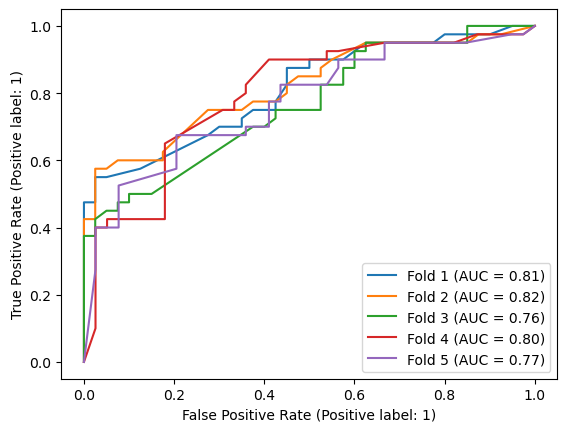

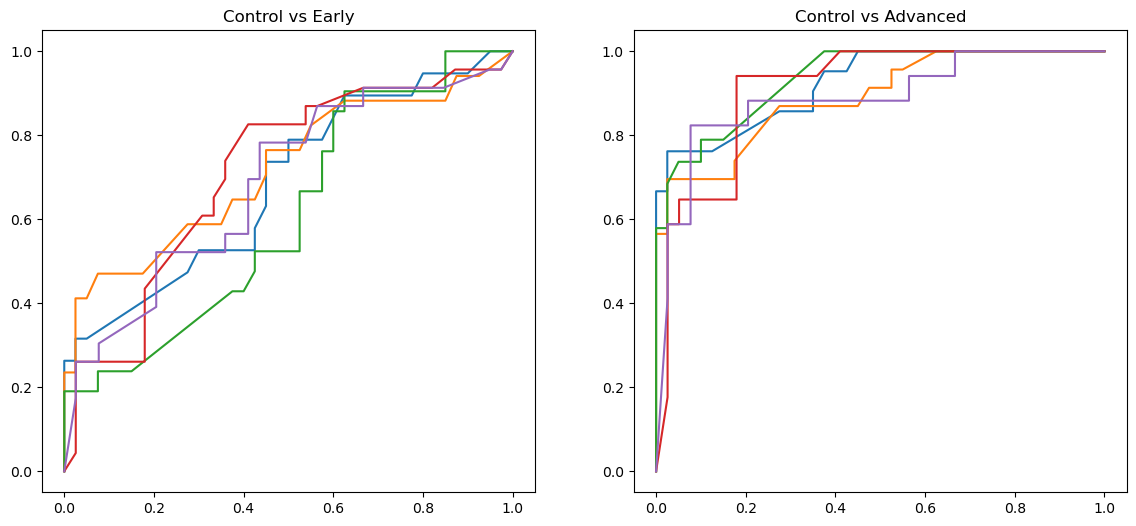

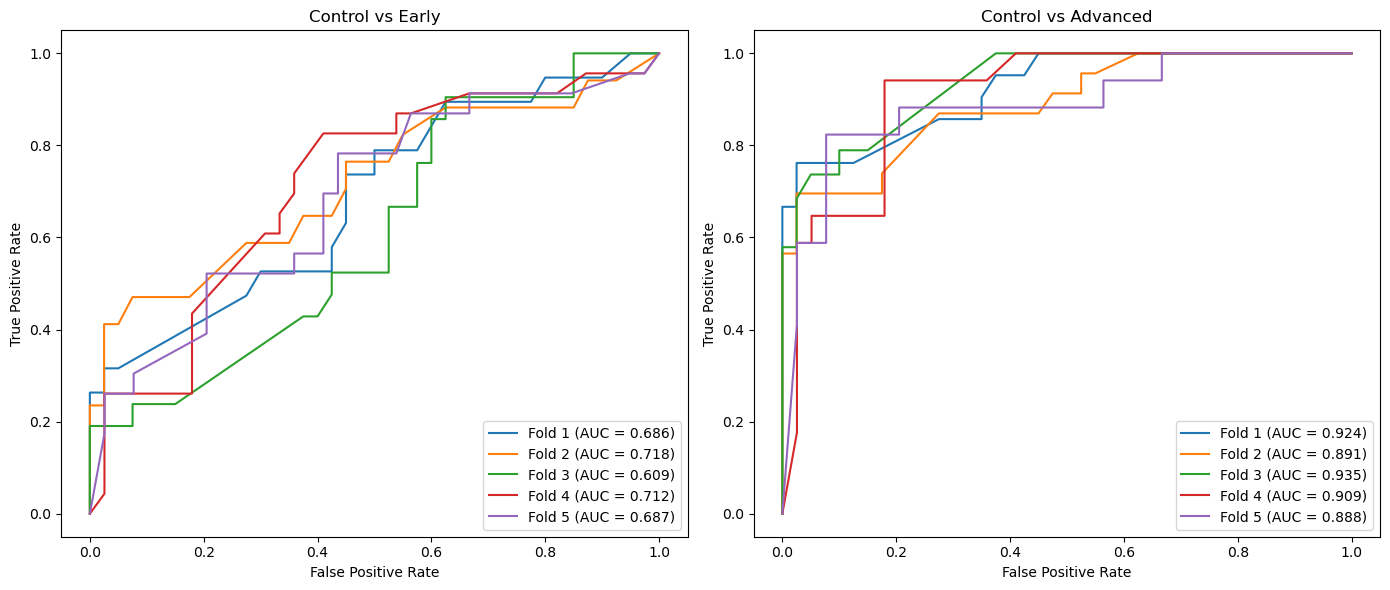


Control vs Early
各foldのAUC: [0.6855 0.7184 0.6089 0.7118 0.6873]
平均AUC: 0.6824
標準偏差: 0.0436

Control vs Advanced
各foldのAUC: [0.9238 0.8913 0.9349 0.9087 0.8876]
平均AUC: 0.9093
標準偏差: 0.0204


,Fold,AUC,Accuracy,Sensitivity,Specificity,False Positive Rate,False Negative Rate,PPV,NPV
0,1,0.8106,0.7250,0.575,0.8750,0.1250,0.425,0.8214,0.6731
1,2,0.8178,0.7375,0.600,0.8750,0.1250,0.400,0.8276,0.6863
2,3,0.7638,0.6875,0.475,0.9000,0.1000,0.525,0.8261,0.6316
3,4,0.7955,0.7215,0.625,0.8205,0.1795,0.375,0.7812,0.6809
4,5,0.7724,0.7215,0.525,0.9231,0.0769,0.475,0.8750,0.6545


,Metric,Mean,SD
0,AUC,0.7920,0.0235
1,Accuracy,0.7186,0.0186
2,Sensitivity,0.5600,0.0602
3,Specificity,0.8787,0.0382
4,False Positive Rate,0.1213,0.0382
5,False Negative Rate,0.4400,0.0602
6,PPV,0.8263,0.0333
7,NPV,0.6653,0.0223


,Protein,Importance,SD_Importance
0,logvalue,1.0,0.0


結果を保存しました: ./RF_Data/RF_status_ca199


In [70]:
import time
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=123)
aucs = []
fig, ax = plt.subplots()

# ==========================================
# progress_group別ROC用の図
# ==========================================
fig_progress, axes_progress = plt.subplots(1, 2, figsize=(14, 6))

axes_progress[0].set_title("Control vs Early")
axes_progress[1].set_title("Control vs Advanced")

progress_auc = {
    "Early": [],
    "Advanced": []
}

# 各foldの予測結果を保存
y_prob_all = np.full(len(y), np.nan)
y_true_all = np.full(len(y), np.nan)
feature_importances = []

# 追加：各foldの評価指標・最適パラメータを保存
fold_metrics = []
best_params_all = []

save_dir = "./RF_Data/RF_status_ca199"
os.makedirs(save_dir, exist_ok=True)

for i, (train_index, test_index) in enumerate(skf.split(X, y)):

    X_train, X_test = X.iloc[train_index], X.iloc[test_index]
    y_train, y_test = y.iloc[train_index], y.iloc[test_index]

    param_grid = {
        'n_estimators': [50, 100, 300, 500],
        "max_depth": [None, 3, 5, 10, 15],
        'min_samples_leaf': [1, 2, 4],
        'max_features': [None, 'sqrt'],
        'class_weight': ['balanced']
    }
    # param_grid = {
    #     'n_estimators': [50],
    #     "max_depth": [10],
    #     'min_samples_leaf': [4],
    #     'max_features': ['sqrt'],
    #     'class_weight': ['balanced']
    # }

    model = RandomForestClassifier(
        criterion='gini',
        random_state=123,
        n_jobs=1
    )

    cv_gen = StratifiedKFold(n_splits=5, shuffle=True, random_state=123)

    modelcv = GridSearchCV(
        model,
        param_grid=param_grid,
        scoring='roc_auc',
        n_jobs=1,
        refit=True,
        cv=cv_gen,
        verbose=0,
        pre_dispatch='2*n_jobs',
        error_score=np.nan,
        return_train_score=False
    )

    start = time.time()
    modelcv.fit(X_train, y_train)
    elapsed = time.time() - start

    print(f"1回のGridSearchCV: {elapsed / 60:.2f} 分")
    print(f"全5 foldの推定時間: {elapsed * 5 / 60:.2f} 分")
    print('Best score: ', modelcv.best_score_)
    print('Best hyperparameters: ', modelcv.best_params_)

    # 追加：各foldの最適パラメータを保存
    best_params_all.append({
        "Fold": i + 1,
        "Best_Params": modelcv.best_params_
    })

    dataframe = pd.DataFrame(
        modelcv.cv_results_
    ).sort_values('mean_test_score', ascending=False)
    display(dataframe)

    model = modelcv.best_estimator_

    # 予測確率とAUC
    y_prob = model.predict_proba(X_test)[:, 1]
    score = roc_auc_score(y_test, y_prob)
    aucs.append(score)


    # ==========================================
    # progress_group別ROC曲線
    # ==========================================

    # テストデータのprogress_groupを取得
    # pro_sampleとXは同じ行順であることを前提とする
    progress_test = (
        pro_sample["progress_group"]
        .iloc[test_index]
        .astype(str)
        .str.strip()
        .str.lower()
    )
    comparisons = [
        {"name": "Early", "positive": ["1", "early"], "ax": axes_progress[0]},
        {"name": "Advanced", "positive": ["2", "advanced", "advanced/metastatic"], "ax": axes_progress[1]}
    ]
    
    for comp in comparisons:
        mask = (
            progress_test.isin(["0", "control"]) |
            progress_test.isin(comp["positive"])
        )
    
        progress_labels = (
            progress_test[mask].isin(comp["positive"]).astype(int)
        )
        prob_subset = y_prob[mask.to_numpy()]
    
        if progress_labels.nunique() == 2:
            fpr, tpr, thresholds = roc_curve(
                progress_labels, prob_subset
            )
            auc_progress = roc_auc_score(
                progress_labels, prob_subset
            )
    
            # 各foldのAUCをlegendに表示
            comp["ax"].plot(
                fpr,
                tpr,
                label=f"Fold {i+1} (AUC = {auc_progress:.3f})"
            )
    
            progress_auc[comp["name"]].append(auc_progress)


    # OOF予測を保存
    y_prob_all[test_index] = y_prob
    y_true_all[test_index] = np.asarray(y_test)

    # 各foldの特徴量重要度
    feature_importances.append(model.feature_importances_)

    # 追加：各foldの評価指標を計算
    y_pred = (y_prob >= 0.5).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        y_test, y_pred, labels=[0, 1]
    ).ravel()

    fold_metrics.append({
        "Fold": i + 1,
        "AUC": score,
        "Accuracy": (tp + tn) / (tp + tn + fp + fn),
        "Sensitivity": tp / (tp + fn) if tp + fn else np.nan,
        "Specificity": tn / (tn + fp) if tn + fp else np.nan,
        "False Positive Rate": fp / (fp + tn) if fp + tn else np.nan,
        "False Negative Rate": fn / (fn + tp) if fn + tp else np.nan,
        "PPV": tp / (tp + fp) if tp + fp else np.nan,
        "NPV": tn / (tn + fn) if tn + fn else np.nan
    })

    print('AUC: ', score)

    RocCurveDisplay.from_predictions(
        y_test,
        y_prob,
        name=f"Fold {i+1}",
        ax=ax
    )

print(f"5-Fold平均AUC: {np.mean(aucs):.4f} ± {np.std(aucs, ddof=1):.4f}")
plt.show()
# ==========================================
# progress_group別ROC曲線を表示
# ==========================================

for ax in axes_progress:
    # ax.plot(
    #     [0, 1], [0, 1],
    #     linestyle="--",
    #     color="gray",
    #     label="Chance"
    # )
    # ax.set_xlim(0, 1)
    # ax.set_ylim(0, 1)
    ax.set_xlabel("False Positive Rate")
    ax.set_ylabel("True Positive Rate")
    ax.legend(loc="lower right")
    # ax.grid(alpha=0.3)

fig_progress.tight_layout()
display(fig_progress)
# ==========================================
# 各比較のfold別AUCと平均・標準偏差
# ==========================================

for group, values in progress_auc.items():

    print(f"\nControl vs {group}")

    if len(values) > 0:
        print("各foldのAUC:", np.round(values, 4))
        print(f"平均AUC: {np.mean(values):.4f}")
        print(
            f"標準偏差: "
            f"{np.std(values, ddof=1):.4f}"
            if len(values) > 1
            else "標準偏差: 算出不可（有効なfoldが1つ）"
        )
    else:
        print("ROCを計算できるfoldがありません。")
# ==========================================
# 全foldの予測結果を保存
# ==========================================
y_true_all = y_true_all.astype(int)
y_pred_all = (y_prob_all >= 0.5).astype(int)

oof_df = pd.DataFrame({
    "TrueClass": y_true_all,
    "PredictedProbability": y_prob_all,
    "PredictedClass": y_pred_all
}, index=X.index)

oof_df.index.name = "SampleID"
oof_df.to_csv(f"{save_dir}/oof_predictions.csv")

# ==========================================
# 各foldの評価指標と平均・標準偏差を保存
# ==========================================
fold_metrics_df = pd.DataFrame(fold_metrics)

# 各foldの結果
display(fold_metrics_df.round(4))
fold_metrics_df.to_csv(
    f"{save_dir}/metrics_each_fold.csv",
    index=False
)

# 5-foldの平均と標準偏差
metrics_df = pd.DataFrame({
    "Metric": fold_metrics_df.columns.drop("Fold"),
    "Mean": [
        fold_metrics_df[col].mean()
        for col in fold_metrics_df.columns.drop("Fold")
    ],
    "SD": [
        fold_metrics_df[col].std(ddof=1)
        for col in fold_metrics_df.columns.drop("Fold")
    ]
})

display(metrics_df.round(4))
metrics_df.to_csv(f"{save_dir}/metrics.csv", index=False)

# ==========================================
# foldごとの特徴量重要度の平均を保存
# ==========================================
importance_df = pd.DataFrame({
    "Protein": X.columns,
    "Importance": np.mean(feature_importances, axis=0),
    "SD_Importance": np.std(feature_importances, axis=0, ddof=1)
}).sort_values("Importance", ascending=False)

importance_df.to_csv(
    f"{save_dir}/feature_importance.csv",
    index=False
)

display(importance_df.head(20))

# ==========================================
# 各foldの最適パラメータ5つを保存
# ==========================================
with open(f"{save_dir}/best_parameters.json", "w") as f:
    json.dump(
        best_params_all,
        f,
        indent=2,
        default=str
    )

print("結果を保存しました:", save_dir)

1回のGridSearchCV: 1.88 分
全5 foldの推定時間: 9.42 分
Best score:  0.8032100554435484
Best hyperparameters:  {'class_weight': 'balanced', 'max_depth': 3, 'max_features': None, 'min_samples_leaf': 4, 'n_estimators': 500}


,mean_fit_time,std_fit_time,mean_score_time,std_score_time,param_class_weight,param_max_depth,param_max_features,param_min_samples_leaf,param_n_estimators,params,split0_test_score,split1_test_score,split2_test_score,split3_test_score,split4_test_score,mean_test_score,std_test_score,rank_test_score
35,0.352282,0.001407,0.020699,0.000230,balanced,3,None,4,500,"{'class_weight': 'balanced', 'max_depth': 3, '...",0.762207,0.815430,0.815430,0.798387,0.824597,0.803210,0.022184,1
47,0.353101,0.001754,0.020582,0.000254,balanced,3,sqrt,4,500,"{'class_weight': 'balanced', 'max_depth': 3, '...",0.762207,0.815430,0.815430,0.798387,0.824597,0.803210,0.022184,1
34,0.216350,0.006378,0.013361,0.000648,balanced,3,None,4,300,"{'class_weight': 'balanced', 'max_depth': 3, '...",0.760254,0.816406,0.812500,0.802923,0.823085,0.803034,0.022363,3
46,0.217738,0.008788,0.013036,0.000380,balanced,3,sqrt,4,300,"{'class_weight': 'balanced', 'max_depth': 3, '...",0.760254,0.816406,0.812500,0.802923,0.823085,0.803034,0.022363,3
33,0.071156,0.000341,0.005423,0.000087,balanced,3,None,4,100,"{'class_weight': 'balanced', 'max_depth': 3, '...",0.762695,0.811523,0.812012,0.801915,0.824093,0.802448,0.021085,5
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
13,0.076973,0.000433,0.005646,0.000069,balanced,None,sqrt,1,100,"{'class_weight': 'balanced', 'max_depth': None...",0.689453,0.755371,0.834961,0.794355,0.778226,0.770473,0.048128,115
85,0.076302,0.000458,0.005533,0.000056,balanced,10,sqrt,1,100,"{'class_weight': 'balanced', 'max_depth': 10, ...",0.690918,0.767578,0.821777,0.792339,0.778226,0.770168,0.043606,117
73,0.078775,0.003268,0.006167,0.000559,balanced,10,None,1,100,"{'class_weight': 'balanced', 'max_depth': 10, ...",0.690918,0.767578,0.821777,0.792339,0.778226,0.770168,0.043606,117
109,0.079994,0.003248,0.005977,0.000452,balanced,15,sqrt,1,100,"{'class_weight': 'balanced', 'max_depth': 15, ...",0.685547,0.756348,0.830566,0.795363,0.780242,0.769613,0.048445,119


AUC:  0.8106249999999999
1回のGridSearchCV: 1.88 分
全5 foldの推定時間: 9.41 分
Best score:  0.8070217993951614
Best hyperparameters:  {'class_weight': 'balanced', 'max_depth': 3, 'max_features': None, 'min_samples_leaf': 1, 'n_estimators': 100}


,mean_fit_time,std_fit_time,mean_score_time,std_score_time,param_class_weight,param_max_depth,param_max_features,param_min_samples_leaf,param_n_estimators,params,split0_test_score,split1_test_score,split2_test_score,split3_test_score,split4_test_score,mean_test_score,std_test_score,rank_test_score
37,0.072256,0.000851,0.005431,0.000129,balanced,3,sqrt,1,100,"{'class_weight': 'balanced', 'max_depth': 3, '...",0.889160,0.849121,0.876465,0.696069,0.724294,0.807022,0.080617,1
25,0.071675,0.000734,0.005478,0.000141,balanced,3,None,1,100,"{'class_weight': 'balanced', 'max_depth': 3, '...",0.889160,0.849121,0.876465,0.696069,0.724294,0.807022,0.080617,1
32,0.036190,0.000091,0.003499,0.000039,balanced,3,None,4,50,"{'class_weight': 'balanced', 'max_depth': 3, '...",0.885254,0.860352,0.874512,0.695565,0.718246,0.806786,0.082247,3
44,0.036145,0.000074,0.003471,0.000022,balanced,3,sqrt,4,50,"{'class_weight': 'balanced', 'max_depth': 3, '...",0.885254,0.860352,0.874512,0.695565,0.718246,0.806786,0.082247,3
40,0.036356,0.000187,0.003525,0.000064,balanced,3,sqrt,2,50,"{'class_weight': 'balanced', 'max_depth': 3, '...",0.886719,0.857422,0.877441,0.696573,0.713710,0.806373,0.083372,5
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
13,0.076727,0.000446,0.005614,0.000098,balanced,None,sqrt,1,100,"{'class_weight': 'balanced', 'max_depth': None...",0.690918,0.744629,0.852051,0.663810,0.713710,0.733024,0.065174,115
96,0.038940,0.000268,0.003587,0.000028,balanced,15,None,1,50,"{'class_weight': 'balanced', 'max_depth': 15, ...",0.685059,0.760254,0.845703,0.653730,0.719254,0.732800,0.066657,117
108,0.040015,0.001202,0.003840,0.000335,balanced,15,sqrt,1,50,"{'class_weight': 'balanced', 'max_depth': 15, ...",0.685059,0.760254,0.845703,0.653730,0.719254,0.732800,0.066657,117
12,0.039112,0.000226,0.003592,0.000022,balanced,None,sqrt,1,50,"{'class_weight': 'balanced', 'max_depth': None...",0.684082,0.747559,0.846680,0.650706,0.719254,0.729656,0.066983,119


AUC:  0.8178124999999999
1回のGridSearchCV: 1.90 分
全5 foldの推定時間: 9.48 分
Best score:  0.793390877016129
Best hyperparameters:  {'class_weight': 'balanced', 'max_depth': 3, 'max_features': None, 'min_samples_leaf': 1, 'n_estimators': 500}


...

AUC:  0.76375
1回のGridSearchCV: 1.89 分
全5 foldの推定時間: 9.43 分
Best score:  0.8151524697580645
Best hyperparameters:  {'class_weight': 'balanced', 'max_depth': 3, 'max_features': None, 'min_samples_leaf': 4, 'n_estimators': 50}


,mean_fit_time,std_fit_time,mean_score_time,std_score_time,param_class_weight,param_max_depth,param_max_features,param_min_samples_leaf,param_n_estimators,params,split0_test_score,split1_test_score,split2_test_score,split3_test_score,split4_test_score,mean_test_score,std_test_score,rank_test_score
32,0.039271,0.001295,0.004012,0.000235,balanced,3,None,4,50,"{'class_weight': 'balanced', 'max_depth': 3, '...",0.854980,0.814453,0.764160,0.811523,0.830645,0.815152,0.029800,1
44,0.036295,0.000078,0.003470,0.000009,balanced,3,sqrt,4,50,"{'class_weight': 'balanced', 'max_depth': 3, '...",0.854980,0.814453,0.764160,0.811523,0.830645,0.815152,0.029800,1
47,0.356977,0.008211,0.020714,0.000486,balanced,3,sqrt,4,500,"{'class_weight': 'balanced', 'max_depth': 3, '...",0.845215,0.805664,0.771973,0.823242,0.827117,0.814642,0.024761,3
35,0.352693,0.004739,0.020417,0.000362,balanced,3,None,4,500,"{'class_weight': 'balanced', 'max_depth': 3, '...",0.845215,0.805664,0.771973,0.823242,0.827117,0.814642,0.024761,3
29,0.071281,0.000448,0.005360,0.000052,balanced,3,None,2,100,"{'class_weight': 'balanced', 'max_depth': 3, '...",0.847168,0.811035,0.772461,0.810059,0.831653,0.814475,0.025141,5
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
3,0.383664,0.007733,0.021575,0.000501,balanced,None,None,1,500,"{'class_weight': 'balanced', 'max_depth': None...",0.834961,0.685547,0.732422,0.737305,0.764617,0.750970,0.049095,115
13,0.077355,0.000482,0.005578,0.000027,balanced,None,sqrt,1,100,"{'class_weight': 'balanced', 'max_depth': None...",0.832031,0.684082,0.729004,0.737793,0.767137,0.750009,0.048904,117
1,0.077210,0.001064,0.005599,0.000051,balanced,None,None,1,100,"{'class_weight': 'balanced', 'max_depth': None...",0.832031,0.684082,0.729004,0.737793,0.767137,0.750009,0.048904,117
12,0.039298,0.000193,0.003620,0.000034,balanced,None,sqrt,1,50,"{'class_weight': 'balanced', 'max_depth': None...",0.836426,0.687012,0.719727,0.729980,0.765625,0.747754,0.050937,119


AUC:  0.7955128205128205
1回のGridSearchCV: 1.89 分
全5 foldの推定時間: 9.45 分
Best score:  0.8113533266129032
Best hyperparameters:  {'class_weight': 'balanced', 'max_depth': 3, 'max_features': None, 'min_samples_leaf': 4, 'n_estimators': 500}


,mean_fit_time,std_fit_time,mean_score_time,std_score_time,param_class_weight,param_max_depth,param_max_features,param_min_samples_leaf,param_n_estimators,params,split0_test_score,split1_test_score,split2_test_score,split3_test_score,split4_test_score,mean_test_score,std_test_score,rank_test_score
35,0.357902,0.007375,0.020534,0.000457,balanced,3,None,4,500,"{'class_weight': 'balanced', 'max_depth': 3, '...",0.823242,0.745605,0.844727,0.779785,0.863407,0.811353,0.043091,1
47,0.363156,0.004596,0.021094,0.000376,balanced,3,sqrt,4,500,"{'class_weight': 'balanced', 'max_depth': 3, '...",0.823242,0.745605,0.844727,0.779785,0.863407,0.811353,0.043091,1
45,0.071897,0.000348,0.005411,0.000043,balanced,3,sqrt,4,100,"{'class_weight': 'balanced', 'max_depth': 3, '...",0.820312,0.742676,0.853516,0.778809,0.861391,0.811341,0.045028,3
33,0.071395,0.000244,0.005363,0.000038,balanced,3,None,4,100,"{'class_weight': 'balanced', 'max_depth': 3, '...",0.820312,0.742676,0.853516,0.778809,0.861391,0.811341,0.045028,3
34,0.211216,0.000543,0.012797,0.000091,balanced,3,None,4,300,"{'class_weight': 'balanced', 'max_depth': 3, '...",0.823242,0.744629,0.845703,0.776855,0.862399,0.810566,0.043740,5
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
114,0.232190,0.004987,0.014004,0.000499,balanced,15,sqrt,2,300,"{'class_weight': 'balanced', 'max_depth': 15, ...",0.773926,0.650391,0.820801,0.765625,0.786794,0.759507,0.057712,115
6,0.226771,0.002863,0.013664,0.000313,balanced,None,None,2,300,"{'class_weight': 'balanced', 'max_depth': None...",0.773926,0.649414,0.824707,0.765625,0.783770,0.759488,0.058661,117
18,0.224925,0.000928,0.013395,0.000067,balanced,None,sqrt,2,300,"{'class_weight': 'balanced', 'max_depth': None...",0.773926,0.649414,0.824707,0.765625,0.783770,0.759488,0.058661,117
12,0.039491,0.000042,0.003642,0.000008,balanced,None,sqrt,1,50,"{'class_weight': 'balanced', 'max_depth': None...",0.766113,0.660156,0.821289,0.769043,0.761089,0.755538,0.052433,119


AUC:  0.7724358974358975
5-Fold平均AUC: 0.7920 ± 0.0235


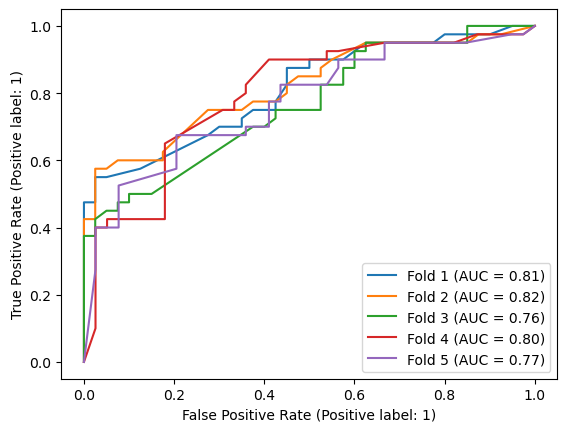

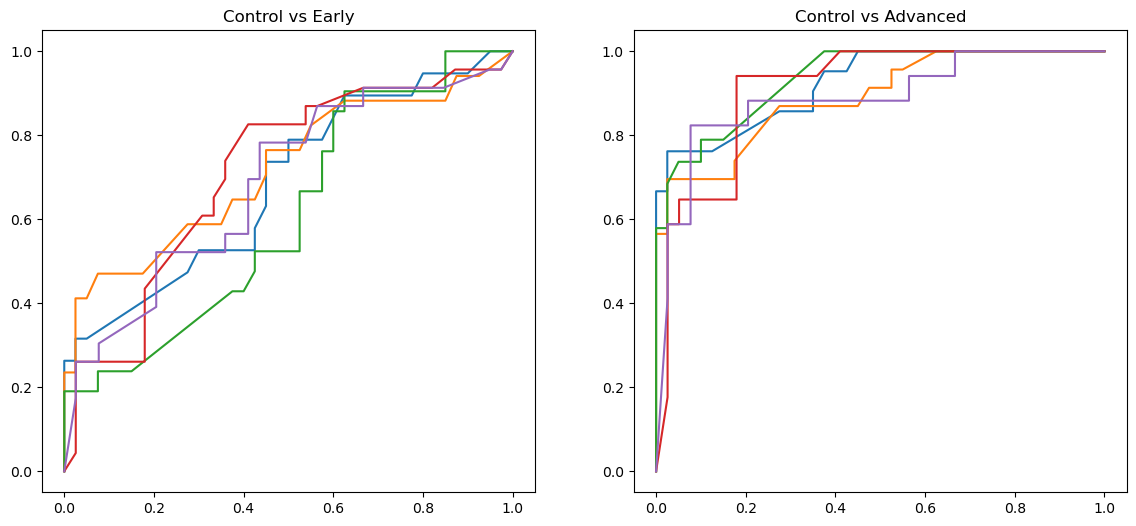

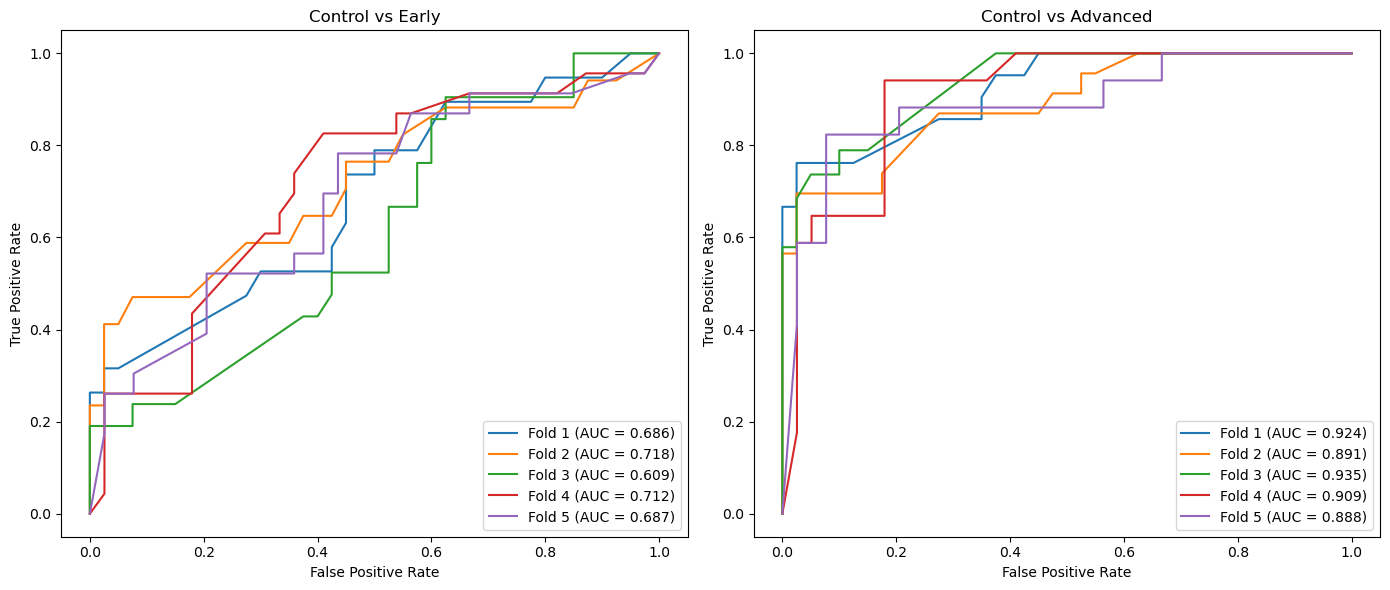


Control vs Early
各foldのAUC: [0.6855 0.7184 0.6089 0.7118 0.6873]
平均AUC: 0.6824
標準偏差: 0.0436

Control vs Advanced
各foldのAUC: [0.9238 0.8913 0.9349 0.9087 0.8876]
平均AUC: 0.9093
標準偏差: 0.0204


,Fold,AUC,Accuracy,Sensitivity,Specificity,False Positive Rate,False Negative Rate,PPV,NPV
0,1,0.8106,0.7250,0.575,0.8750,0.1250,0.425,0.8214,0.6731
1,2,0.8178,0.7375,0.600,0.8750,0.1250,0.400,0.8276,0.6863
2,3,0.7638,0.6875,0.475,0.9000,0.1000,0.525,0.8261,0.6316
3,4,0.7955,0.7215,0.625,0.8205,0.1795,0.375,0.7812,0.6809
4,5,0.7724,0.7215,0.525,0.9231,0.0769,0.475,0.8750,0.6545


,Metric,Mean,SD
0,AUC,0.7920,0.0235
1,Accuracy,0.7186,0.0186
2,Sensitivity,0.5600,0.0602
3,Specificity,0.8787,0.0382
4,False Positive Rate,0.1213,0.0382
5,False Negative Rate,0.4400,0.0602
6,PPV,0.8263,0.0333
7,NPV,0.6653,0.0223


,Protein,Importance,SD_Importance
0,logvalue,1.0,0.0


結果を保存しました: ./RF_Data/RF_status_ca199


In [91]:
import time
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=123)
aucs = []
fig, ax = plt.subplots()

# ==========================================
# progress_group別ROC用の図
# ==========================================
fig_progress, axes_progress = plt.subplots(1, 2, figsize=(14, 6))

axes_progress[0].set_title("Control vs Early")
axes_progress[1].set_title("Control vs Advanced")

progress_auc = {
    "Early": [],
    "Advanced": []
}

# 各foldの予測結果を保存
y_prob_all = np.full(len(y), np.nan)
y_true_all = np.full(len(y), np.nan)
feature_importances = []

# 追加：各foldの評価指標・最適パラメータを保存
fold_metrics = []
best_params_all = []

save_dir = "./RF_Data/RF_status_ca199"
os.makedirs(save_dir, exist_ok=True)

for i, (train_index, test_index) in enumerate(skf.split(X, y)):

    X_train, X_test = X.iloc[train_index], X.iloc[test_index]
    y_train, y_test = y.iloc[train_index], y.iloc[test_index]

    param_grid = {
        'n_estimators': [50, 100, 300, 500],
        "max_depth": [None, 3, 5, 10, 15],
        'min_samples_leaf': [1, 2, 4],
        'max_features': [None, 'sqrt'],
        'class_weight': ['balanced']
    }
    # param_grid = {
    #     'n_estimators': [50],
    #     "max_depth": [10],
    #     'min_samples_leaf': [4],
    #     'max_features': ['sqrt'],
    #     'class_weight': ['balanced']
    # }

    model = RandomForestClassifier(
        criterion='gini',
        random_state=123,
        n_jobs=1
    )

    cv_gen = StratifiedKFold(n_splits=5, shuffle=True, random_state=123)

    modelcv = GridSearchCV(
        model,
        param_grid=param_grid,
        scoring='roc_auc',
        n_jobs=1,
        refit=True,
        cv=cv_gen,
        verbose=0,
        pre_dispatch='2*n_jobs',
        error_score=np.nan,
        return_train_score=False
    )

    start = time.time()
    modelcv.fit(X_train, y_train)
    elapsed = time.time() - start

    print(f"1回のGridSearchCV: {elapsed / 60:.2f} 分")
    print(f"全5 foldの推定時間: {elapsed * 5 / 60:.2f} 分")
    print('Best score: ', modelcv.best_score_)
    print('Best hyperparameters: ', modelcv.best_params_)

    # 追加：各foldの最適パラメータを保存
    best_params_all.append({
        "Fold": i + 1,
        "Best_Params": modelcv.best_params_
    })

    dataframe = pd.DataFrame(
        modelcv.cv_results_
    ).sort_values('mean_test_score', ascending=False)
    display(dataframe)

    model = modelcv.best_estimator_


    # Foldごとの学習済みモデルを保存
    joblib.dump(
        model,
        f"{save_dir}/rf_model_fold_{i+1}.joblib"
    )
    
    # Foldごとのテストデータを保存
    X_test.to_csv(
        f"{save_dir}/X_test_fold_{i+1}.csv",
        index=True
    )
    
    # テストデータの正解ラベルを保存
    y_test.to_csv(
        f"{save_dir}/y_test_fold_{i+1}.csv",
        index=True
    )
    
    # 特徴量名を保存
    pd.Series(X.columns).to_csv(
        f"{save_dir}/feature_names.csv",
        index=False,
        header=["Feature"]
    )

    # 予測確率とAUC
    y_prob = model.predict_proba(X_test)[:, 1]
    score = roc_auc_score(y_test, y_prob)
    aucs.append(score)


    # ==========================================
    # progress_group別ROC曲線
    # ==========================================

    # テストデータのprogress_groupを取得
    # pro_sampleとXは同じ行順であることを前提とする
    progress_test = (
        pro_sample["progress_group"]
        .iloc[test_index]
        .astype(str)
        .str.strip()
        .str.lower()
    )
    comparisons = [
        {"name": "Early", "positive": ["1", "early"], "ax": axes_progress[0]},
        {"name": "Advanced", "positive": ["2", "advanced", "advanced/metastatic"], "ax": axes_progress[1]}
    ]
    
    for comp in comparisons:
        mask = (
            progress_test.isin(["0", "control"]) |
            progress_test.isin(comp["positive"])
        )
    
        progress_labels = (
            progress_test[mask].isin(comp["positive"]).astype(int)
        )
        prob_subset = y_prob[mask.to_numpy()]
    
        if progress_labels.nunique() == 2:
            fpr, tpr, thresholds = roc_curve(
                progress_labels, prob_subset
            )
            auc_progress = roc_auc_score(
                progress_labels, prob_subset
            )
    
            # 各foldのAUCをlegendに表示
            comp["ax"].plot(
                fpr,
                tpr,
                label=f"Fold {i+1} (AUC = {auc_progress:.3f})"
            )
    
            progress_auc[comp["name"]].append(auc_progress)


    # OOF予測を保存
    y_prob_all[test_index] = y_prob
    y_true_all[test_index] = np.asarray(y_test)

    # 各foldの特徴量重要度
    feature_importances.append(model.feature_importances_)

    # 追加：各foldの評価指標を計算
    y_pred = (y_prob >= 0.5).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        y_test, y_pred, labels=[0, 1]
    ).ravel()

    fold_metrics.append({
        "Fold": i + 1,
        "AUC": score,
        "Accuracy": (tp + tn) / (tp + tn + fp + fn),
        "Sensitivity": tp / (tp + fn) if tp + fn else np.nan,
        "Specificity": tn / (tn + fp) if tn + fp else np.nan,
        "False Positive Rate": fp / (fp + tn) if fp + tn else np.nan,
        "False Negative Rate": fn / (fn + tp) if fn + tp else np.nan,
        "PPV": tp / (tp + fp) if tp + fp else np.nan,
        "NPV": tn / (tn + fn) if tn + fn else np.nan
    })

    print('AUC: ', score)

    RocCurveDisplay.from_predictions(
        y_test,
        y_prob,
        name=f"Fold {i+1}",
        ax=ax
    )

print(f"5-Fold平均AUC: {np.mean(aucs):.4f} ± {np.std(aucs, ddof=1):.4f}")
plt.show()
# ==========================================
# progress_group別ROC曲線を表示
# ==========================================

for ax in axes_progress:
    # ax.plot(
    #     [0, 1], [0, 1],
    #     linestyle="--",
    #     color="gray",
    #     label="Chance"
    # )
    # ax.set_xlim(0, 1)
    # ax.set_ylim(0, 1)
    ax.set_xlabel("False Positive Rate")
    ax.set_ylabel("True Positive Rate")
    ax.legend(loc="lower right")
    # ax.grid(alpha=0.3)

fig_progress.tight_layout()
display(fig_progress)
# ==========================================
# 各比較のfold別AUCと平均・標準偏差
# ==========================================

for group, values in progress_auc.items():

    print(f"\nControl vs {group}")

    if len(values) > 0:
        print("各foldのAUC:", np.round(values, 4))
        print(f"平均AUC: {np.mean(values):.4f}")
        print(
            f"標準偏差: "
            f"{np.std(values, ddof=1):.4f}"
            if len(values) > 1
            else "標準偏差: 算出不可（有効なfoldが1つ）"
        )
    else:
        print("ROCを計算できるfoldがありません。")
# ==========================================
# 全foldの予測結果を保存
# ==========================================
y_true_all = y_true_all.astype(int)
y_pred_all = (y_prob_all >= 0.5).astype(int)

oof_df = pd.DataFrame({
    "TrueClass": y_true_all,
    "PredictedProbability": y_prob_all,
    "PredictedClass": y_pred_all
}, index=X.index)

oof_df.index.name = "SampleID"
oof_df.to_csv(f"{save_dir}/oof_predictions.csv")

# ==========================================
# 各foldの評価指標と平均・標準偏差を保存
# ==========================================
fold_metrics_df = pd.DataFrame(fold_metrics)

# 各foldの結果
display(fold_metrics_df.round(4))
fold_metrics_df.to_csv(
    f"{save_dir}/metrics_each_fold.csv",
    index=False
)

# 5-foldの平均と標準偏差
metrics_df = pd.DataFrame({
    "Metric": fold_metrics_df.columns.drop("Fold"),
    "Mean": [
        fold_metrics_df[col].mean()
        for col in fold_metrics_df.columns.drop("Fold")
    ],
    "SD": [
        fold_metrics_df[col].std(ddof=1)
        for col in fold_metrics_df.columns.drop("Fold")
    ]
})

display(metrics_df.round(4))
metrics_df.to_csv(f"{save_dir}/metrics.csv", index=False)

# ==========================================
# foldごとの特徴量重要度の平均を保存
# ==========================================
importance_df = pd.DataFrame({
    "Protein": X.columns,
    "Importance": np.mean(feature_importances, axis=0),
    "SD_Importance": np.std(feature_importances, axis=0, ddof=1)
}).sort_values("Importance", ascending=False)

importance_df.to_csv(
    f"{save_dir}/feature_importance.csv",
    index=False
)

display(importance_df.head(20))

# ==========================================
# 各foldの最適パラメータ5つを保存
# ==========================================
with open(f"{save_dir}/best_parameters.json", "w") as f:
    json.dump(
        best_params_all,
        f,
        indent=2,
        default=str
    )

print("結果を保存しました:", save_dir)

In [96]:
import os
import joblib
import numpy as np
import pandas as pd
from sklearn.metrics import confusion_matrix, accuracy_score, roc_auc_score

save_dir = "./RF_Data/RF_status_ca199"

fold_metrics = []

for i in range(1, 6):

    # ==========================================
    # 保存済みファイルを読み込む
    # ==========================================
    model = joblib.load(
        f"{save_dir}/rf_model_fold_{i}.joblib"
    )

    X_test = pd.read_csv(
        f"{save_dir}/X_test_fold_{i}.csv",
        index_col=0
    )

    y_test = pd.read_csv(
        f"{save_dir}/y_test_fold_{i}.csv",
        index_col=0
    ).iloc[:, 0]

    # X_testのサンプル順に合わせてprogress_groupを取得
    progress_test = (
        pro_sample.loc[X_test.index, "progress_group"]
        .astype(str)
        .str.strip()
        .str.lower()
    )

    # ControlとEarlyだけを抽出
    control_mask = progress_test.isin(["0", "control"])
    early_mask = progress_test.isin(["1", "early"])
    mask = control_mask | early_mask

    X_sub = X_test.loc[mask]
    progress_sub = progress_test.loc[mask]

    # Control=0、Early=1
    y_true = early_mask.loc[mask].astype(int).to_numpy()

    # 保存済みモデルで予測（再学習なし）
    y_prob = model.predict_proba(X_sub)[:, 1]
    y_pred = (y_prob >= 0.5).astype(int)

    # ==========================================
    # 評価指標を計算
    # ==========================================
    tn, fp, fn, tp = confusion_matrix(
        y_true, y_pred, labels=[0, 1]
    ).ravel()

    fold_metrics.append({
        "Fold": i,
        "AUC": roc_auc_score(y_true, y_prob),
        "Accuracy": accuracy_score(y_true, y_pred),
        "Sensitivity": tp / (tp + fn) if tp + fn else np.nan,
        "Specificity": tn / (tn + fp) if tn + fp else np.nan
    })

# ==========================================
# Foldごとの結果
# ==========================================
metrics_df = pd.DataFrame(fold_metrics)
display(metrics_df.round(4))

# ==========================================
# 平均 ± SD
# ==========================================
summary = pd.DataFrame({
    "Mean": metrics_df.drop(columns="Fold").mean(),
    "SD": metrics_df.drop(columns="Fold").std(ddof=1)
})

summary["Mean ± SD"] = summary.apply(
    lambda row: f"{row['Mean']:.3f} ± {row['SD']:.3f}",
    axis=1
)

display(summary[["Mean ± SD"]])

,Fold,AUC,Accuracy,Sensitivity,Specificity
0,1,0.6855,0.7119,0.3684,0.8750
1,2,0.7184,0.7544,0.4706,0.8750
2,3,0.6089,0.6721,0.2381,0.9000
3,4,0.7118,0.6613,0.3913,0.8205
4,5,0.6873,0.6935,0.3043,0.9231


,Mean ± SD
AUC,0.682 ± 0.044
Accuracy,0.699 ± 0.037
Sensitivity,0.355 ± 0.088
Specificity,0.879 ± 0.038


### 120人の方で検証

In [ ]:
X = ca199_dis[['logvalue']]

y = pro_sample_dis['groupset2']
print(X.shape)
print(y.shape)

print(X.index[:5])
print(y.index[:5])

In [ ]:
val_probs = []
val_aucs = []

fig, ax = plt.subplots()

for i, model in enumerate(modelsets_HER_ca199):

    y_val = model.predict_proba(X)[:, 1]
    val_probs.append(y_val)

    auc_val = roc_auc_score(y, y_val)
    val_aucs.append(auc_val)

    print(f"Fold {i+1} Validation AUC: {auc_val:.4f}")

    RocCurveDisplay.from_predictions(
        y,
        y_val,
        name=f"Fold {i+1} (AUC = {auc_val:.3f})",
        ax=ax
    )

# 5モデルの予測確率を平均
val_probs = np.array(val_probs)
y_val_mean = val_probs.mean(axis=0)

# Ensemble AUC
auc_mean = roc_auc_score(y, y_val_mean)

# 平均予測のROC
RocCurveDisplay.from_predictions(
    y,
    y_val_mean,
    name=f"Mean prediction (AUC = {auc_mean:.3f})",
    ax=ax
)

# 5モデルのAUCの平均 ± SD
auc_val_mean = np.mean(val_aucs)
auc_val_sd = np.std(val_aucs, ddof=1)

print(f"Validation AUC: {auc_val_mean:.4f} ± {auc_val_sd:.4f}")

ax.plot([0, 1], [0, 1], linestyle="--")

ax.set_title("Validation ROC curves")
plt.show()

print(f"Ensemble Validation AUC: {auc_mean:.4f}")

## IL2RA単独

In [ ]:
X = il2ra[["logvalue"]]
y = pro_sample["CaCo_Status"]

print(X.shape)
print(y.shape)

print(X.index[:5])
print(y.index[:5])

In [ ]:
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=123)
aucs = []
fig, ax = plt.subplots()

for i, (train_index, test_index) in enumerate(skf.split(X, y)):
    
    X_train, X_test = X.iloc[train_index], X.iloc[test_index]
    y_train, y_test = y.iloc[train_index], y.iloc[test_index]

# X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=123)
    param_grid = {
        'n_estimators': [100, 200, 300],
        'max_depth': [None, 20, 30,40],
        'min_samples_split': [2, 3, 4],
        'min_samples_leaf': [1, 2, 3]
    }
    
    model = RandomForestClassifier(
        criterion='gini',
        random_state=123,
        class_weight='balanced',
        n_jobs=-1 
    )
    
    cv_gen = StratifiedKFold(n_splits=5, shuffle=True, random_state=123)
    
    modelcv = GridSearchCV(
        model, 
        param_grid=param_grid,
        scoring='roc_auc',
        n_jobs=-1, 
        refit=True, 
        cv=cv_gen,
        verbose=0, 
        pre_dispatch='2*n_jobs', 
        error_score=np.nan, 
        return_train_score=False
    )
    
    # 実行
    modelcv.fit(X_train, y_train)
    
    print('Best score: ', modelcv.best_score_)
    print('Best hyperparameters: ', modelcv.best_params_)
    dataframe = pd.DataFrame(modelcv.cv_results_).sort_values('mean_test_score', ascending=False)
    display(dataframe)
    
    model = modelcv.best_estimator_
    y_prob = model.predict_proba(X_test)[:, 1]
    score = roc_auc_score(y_test, y_prob)
    aucs.append(score)

    print('AUC: ', score)
    
    RocCurveDisplay.from_predictions(
        y_test,
        y_prob,
        name=f"Fold {i+1}", ax=ax
    )
    
print(f"5-Fold平均AUC: {np.mean(aucs):.4f} ± {np.std(aucs)}")
plt.show()

saved_assets = {
    'model': modelcv.best_estimator_
}
name = 'mdl_il2ra'
save_dir = "./Data"
path = os.path.join(save_dir, name)
joblib.dump(saved_assets, path)

## DEPlist + CA19-9

In [92]:
dep = pro_data.loc[:, pro_data.columns.isin(DEPlist.index)]
X = pd.concat([
    ca199[['logvalue']],
    dep
], axis=1)

y = pro_sample['CaCo_Status']
print(X.shape)
print(y.shape)

print(X.index[:5])
print(y.index[:5])

(398, 25)
(398,)
Index(['PE_R478_001', 'PE_R478_002', 'PE_R478_003', 'PE_R478_004',
       'PE_R478_005'],
      dtype='object', name='SampleID')
Index(['PE_R478_001', 'PE_R478_002', 'PE_R478_003', 'PE_R478_004',
       'PE_R478_005'],
      dtype='object')


1回のGridSearchCV: 4.09 分
全5 foldの推定時間: 20.47 分
Best score:  0.859702620967742
Best hyperparameters:  {'class_weight': 'balanced', 'max_depth': 10, 'max_features': 'sqrt', 'min_samples_leaf': 2, 'n_estimators': 100}


,mean_fit_time,std_fit_time,mean_score_time,std_score_time,param_class_weight,param_max_depth,param_max_features,param_min_samples_leaf,param_n_estimators,params,split0_test_score,split1_test_score,split2_test_score,split3_test_score,split4_test_score,mean_test_score,std_test_score,rank_test_score
89,0.108501,0.000326,0.005815,0.000067,balanced,10,sqrt,2,100,"{'class_weight': 'balanced', 'max_depth': 10, ...",0.886719,0.777344,0.894531,0.878024,0.861895,0.859703,0.042583,1
17,0.112775,0.003744,0.005976,0.000312,balanced,None,sqrt,2,100,"{'class_weight': 'balanced', 'max_depth': None...",0.881836,0.772461,0.901367,0.878024,0.860887,0.858915,0.045102,2
113,0.111595,0.002815,0.006141,0.000447,balanced,15,sqrt,2,100,"{'class_weight': 'balanced', 'max_depth': 15, ...",0.881836,0.772461,0.900391,0.878024,0.860887,0.858720,0.044919,3
16,0.055640,0.000651,0.003769,0.000048,balanced,None,sqrt,2,50,"{'class_weight': 'balanced', 'max_depth': None...",0.890625,0.755859,0.876953,0.887097,0.867944,0.855696,0.050548,4
112,0.055357,0.000458,0.003768,0.000036,balanced,15,sqrt,2,50,"{'class_weight': 'balanced', 'max_depth': 15, ...",0.890625,0.755859,0.876953,0.887097,0.867944,0.855696,0.050548,4
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1,0.276682,0.003753,0.005804,0.000070,balanced,None,None,1,100,"{'class_weight': 'balanced', 'max_depth': None...",0.855469,0.766113,0.876465,0.874496,0.816532,0.837815,0.041821,116
97,0.284519,0.010740,0.005900,0.000116,balanced,15,None,1,100,"{'class_weight': 'balanced', 'max_depth': 15, ...",0.855469,0.766113,0.876465,0.873992,0.816532,0.837714,0.041733,117
36,0.045692,0.000236,0.003685,0.000032,balanced,3,sqrt,1,50,"{'class_weight': 'balanced', 'max_depth': 3, '...",0.867188,0.722656,0.876953,0.860887,0.858871,0.837311,0.057672,118
40,0.045829,0.000528,0.003733,0.000087,balanced,3,sqrt,2,50,"{'class_weight': 'balanced', 'max_depth': 3, '...",0.866211,0.722656,0.873047,0.866935,0.855847,0.836939,0.057408,119


AUC:  0.895
1回のGridSearchCV: 4.07 分
全5 foldの推定時間: 20.37 分
Best score:  0.85390625
Best hyperparameters:  {'class_weight': 'balanced', 'max_depth': None, 'max_features': 'sqrt', 'min_samples_leaf': 2, 'n_estimators': 500}


,mean_fit_time,std_fit_time,mean_score_time,std_score_time,param_class_weight,param_max_depth,param_max_features,param_min_samples_leaf,param_n_estimators,params,split0_test_score,split1_test_score,split2_test_score,split3_test_score,split4_test_score,mean_test_score,std_test_score,rank_test_score
19,0.551216,0.008928,0.021797,0.000318,balanced,None,sqrt,2,500,"{'class_weight': 'balanced', 'max_depth': None...",0.867188,0.896484,0.912109,0.877016,0.716734,0.853906,0.070324,1
115,0.550713,0.005905,0.021965,0.000195,balanced,15,sqrt,2,500,"{'class_weight': 'balanced', 'max_depth': 15, ...",0.867188,0.896484,0.912109,0.877016,0.715726,0.853705,0.070717,2
18,0.330787,0.005270,0.014237,0.000660,balanced,None,sqrt,2,300,"{'class_weight': 'balanced', 'max_depth': None...",0.871094,0.897461,0.909180,0.873992,0.713710,0.853087,0.071138,3
114,0.332092,0.007303,0.014172,0.000538,balanced,15,sqrt,2,300,"{'class_weight': 'balanced', 'max_depth': 15, ...",0.870117,0.897461,0.909180,0.873992,0.713710,0.852892,0.071089,4
90,0.323265,0.001891,0.013771,0.000126,balanced,10,sqrt,2,300,"{'class_weight': 'balanced', 'max_depth': 10, ...",0.869141,0.898438,0.911133,0.873992,0.711694,0.852879,0.072267,5
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
35,0.832384,0.012626,0.020919,0.000275,balanced,3,None,4,500,"{'class_weight': 'balanced', 'max_depth': 3, '...",0.869141,0.877930,0.879883,0.850806,0.666331,0.828818,0.081892,116
25,0.169243,0.001267,0.005664,0.000122,balanced,3,None,1,100,"{'class_weight': 'balanced', 'max_depth': 3, '...",0.859375,0.875977,0.875977,0.844758,0.680444,0.827306,0.074349,117
29,0.170039,0.002200,0.005726,0.000113,balanced,3,None,2,100,"{'class_weight': 'balanced', 'max_depth': 3, '...",0.863281,0.879883,0.873047,0.844758,0.674395,0.827073,0.077249,118
53,0.215910,0.008124,0.005927,0.000277,balanced,5,None,2,100,"{'class_weight': 'balanced', 'max_depth': 5, '...",0.864258,0.882812,0.870117,0.847782,0.670363,0.827067,0.079157,119


AUC:  0.9025000000000001
1回のGridSearchCV: 4.13 分
全5 foldの推定時間: 20.66 分
Best score:  0.8633001512096774
Best hyperparameters:  {'class_weight': 'balanced', 'max_depth': None, 'max_features': 'sqrt', 'min_samples_leaf': 1, 'n_estimators': 100}


,mean_fit_time,std_fit_time,mean_score_time,std_score_time,param_class_weight,param_max_depth,param_max_features,param_min_samples_leaf,param_n_estimators,params,split0_test_score,split1_test_score,split2_test_score,split3_test_score,split4_test_score,mean_test_score,std_test_score,rank_test_score
13,0.120219,0.002120,0.006160,0.000249,balanced,None,sqrt,1,100,"{'class_weight': 'balanced', 'max_depth': None...",0.883789,0.880371,0.849609,0.840332,0.862399,0.863300,0.016894,1
109,0.113644,0.001127,0.005757,0.000062,balanced,15,sqrt,1,100,"{'class_weight': 'balanced', 'max_depth': 15, ...",0.880859,0.880371,0.849121,0.840820,0.863407,0.862916,0.016158,2
14,0.343297,0.006865,0.013771,0.000229,balanced,None,sqrt,1,300,"{'class_weight': 'balanced', 'max_depth': None...",0.878906,0.881348,0.841797,0.849121,0.853831,0.861001,0.016099,3
110,0.360851,0.033148,0.014030,0.000465,balanced,15,sqrt,1,300,"{'class_weight': 'balanced', 'max_depth': 15, ...",0.878906,0.881348,0.840332,0.849121,0.853327,0.860607,0.016499,4
22,0.317007,0.008454,0.013703,0.000125,balanced,None,sqrt,4,300,"{'class_weight': 'balanced', 'max_depth': None...",0.875000,0.882812,0.846680,0.850586,0.844758,0.859967,0.015772,5
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
104,0.117825,0.002420,0.003683,0.000038,balanced,15,None,4,50,"{'class_weight': 'balanced', 'max_depth': 15, ...",0.857422,0.836914,0.822266,0.827148,0.847782,0.838306,0.012953,116
80,0.117382,0.002762,0.003765,0.000035,balanced,10,None,4,50,"{'class_weight': 'balanced', 'max_depth': 10, ...",0.857422,0.836914,0.822266,0.827148,0.847782,0.838306,0.012953,116
8,0.117249,0.002885,0.003765,0.000046,balanced,None,None,4,50,"{'class_weight': 'balanced', 'max_depth': None...",0.857422,0.836914,0.822266,0.827148,0.847782,0.838306,0.012953,116
48,0.108328,0.001562,0.003742,0.000080,balanced,5,None,1,50,"{'class_weight': 'balanced', 'max_depth': 5, '...",0.837402,0.839844,0.811523,0.857422,0.841734,0.837585,0.014799,119


AUC:  0.8525641025641025
1回のGridSearchCV: 4.02 分
全5 foldの推定時間: 20.08 分
Best score:  0.8693233366935484
Best hyperparameters:  {'class_weight': 'balanced', 'max_depth': 10, 'max_features': 'sqrt', 'min_samples_leaf': 4, 'n_estimators': 300}


,mean_fit_time,std_fit_time,mean_score_time,std_score_time,param_class_weight,param_max_depth,param_max_features,param_min_samples_leaf,param_n_estimators,params,split0_test_score,split1_test_score,split2_test_score,split3_test_score,split4_test_score,mean_test_score,std_test_score,rank_test_score
94,0.309086,0.003619,0.013827,0.000487,balanced,10,sqrt,4,300,"{'class_weight': 'balanced', 'max_depth': 10, ...",0.907227,0.836914,0.866211,0.832031,0.904234,0.869323,0.031957,1
91,0.543333,0.010758,0.021951,0.000959,balanced,10,sqrt,2,500,"{'class_weight': 'balanced', 'max_depth': 10, ...",0.904297,0.844727,0.868164,0.833984,0.895161,0.869267,0.027371,2
22,0.311211,0.005591,0.014043,0.000553,balanced,None,sqrt,4,300,"{'class_weight': 'balanced', 'max_depth': None...",0.910156,0.836914,0.862305,0.832031,0.904234,0.869128,0.032791,3
118,0.313383,0.009437,0.013565,0.000240,balanced,15,sqrt,4,300,"{'class_weight': 'balanced', 'max_depth': 15, ...",0.910156,0.836914,0.862305,0.832031,0.904234,0.869128,0.032791,3
46,0.269450,0.006184,0.013325,0.000208,balanced,3,sqrt,4,300,"{'class_weight': 'balanced', 'max_depth': 3, '...",0.924805,0.832031,0.846680,0.821289,0.918347,0.868630,0.044022,5
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
0,0.137584,0.009023,0.004031,0.000336,balanced,None,None,1,50,"{'class_weight': 'balanced', 'max_depth': None...",0.906738,0.797363,0.875488,0.798340,0.846270,0.844840,0.042870,116
96,0.133182,0.003927,0.003734,0.000041,balanced,15,None,1,50,"{'class_weight': 'balanced', 'max_depth': 15, ...",0.906738,0.797363,0.875488,0.798340,0.846270,0.844840,0.042870,116
24,0.088926,0.003761,0.003999,0.000343,balanced,3,None,1,50,"{'class_weight': 'balanced', 'max_depth': 3, '...",0.925781,0.769531,0.847656,0.803223,0.876512,0.844541,0.054709,118
32,0.085274,0.002954,0.004069,0.000392,balanced,3,None,4,50,"{'class_weight': 'balanced', 'max_depth': 3, '...",0.916992,0.775391,0.842773,0.808594,0.877016,0.844153,0.049760,119


AUC:  0.7993589743589744
5-Fold平均AUC: 0.8515 ± 0.0477


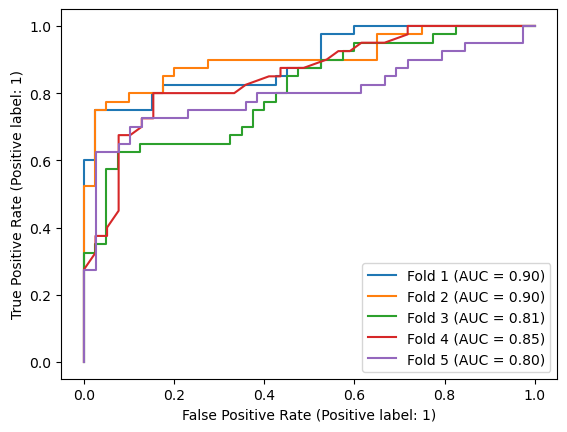

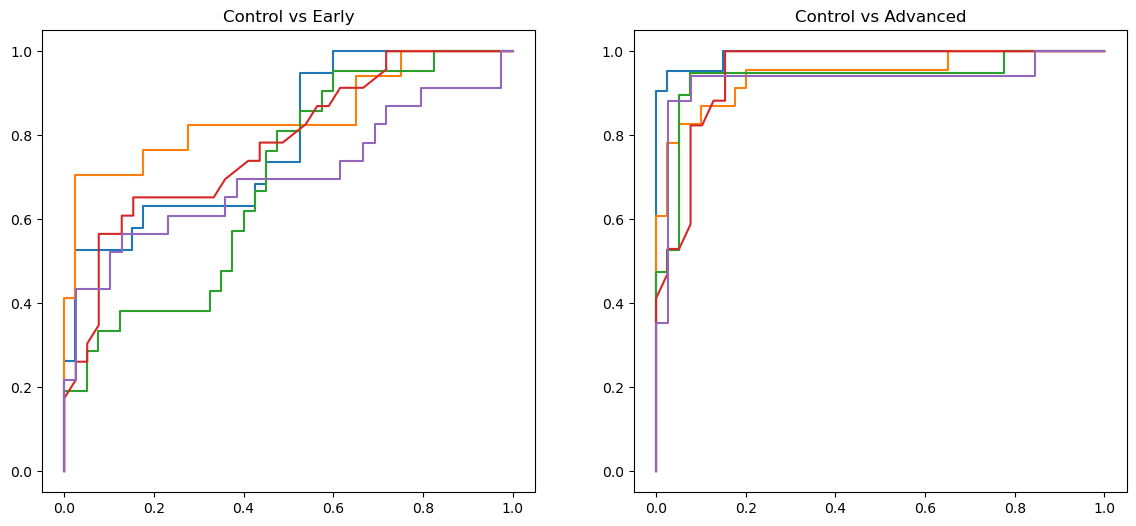

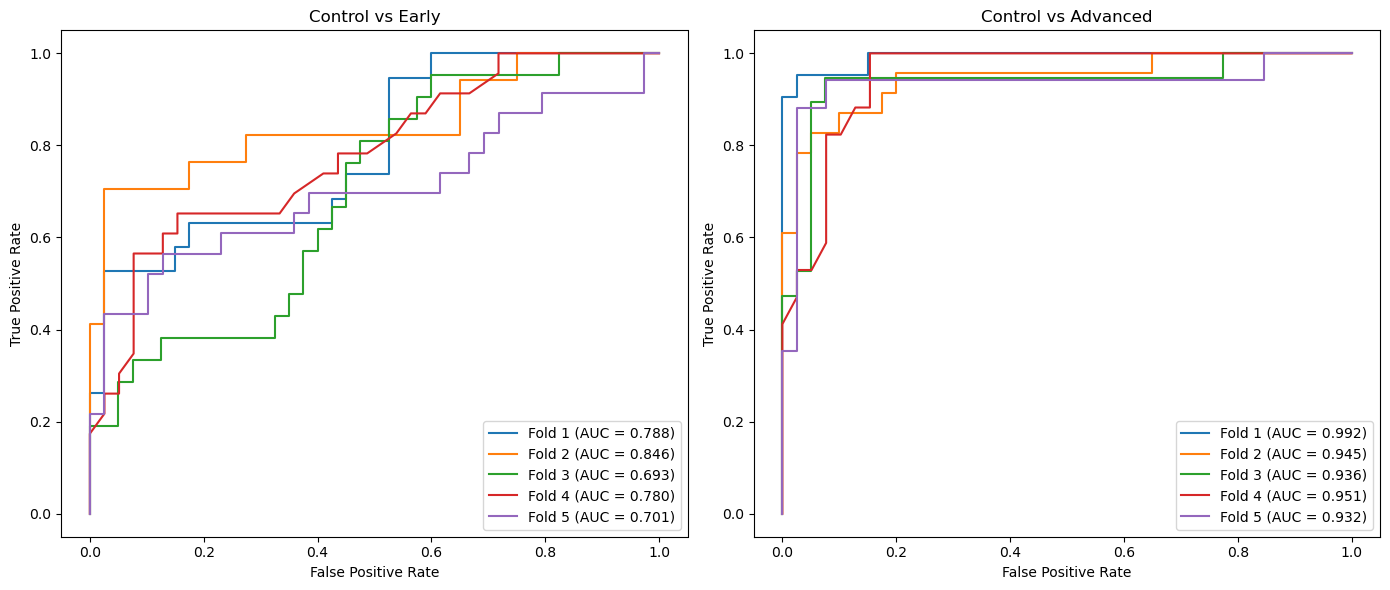


Control vs Early
各foldのAUC: [0.7882 0.8456 0.6929 0.7798 0.7012]
平均AUC: 0.7615
標準偏差: 0.0642

Control vs Advanced
各foldのAUC: [0.9917 0.9446 0.9355 0.951  0.9321]
平均AUC: 0.9510
標準偏差: 0.0239


,Fold,AUC,Accuracy,Sensitivity,Specificity,False Positive Rate,False Negative Rate,PPV,NPV
0,1,0.8950,0.8625,0.750,0.9750,0.0250,0.250,0.9677,0.7959
1,2,0.9025,0.8250,0.800,0.8500,0.1500,0.200,0.8421,0.8095
2,3,0.8081,0.7750,0.625,0.9250,0.0750,0.375,0.8929,0.7115
3,4,0.8526,0.7848,0.800,0.7692,0.2308,0.200,0.7805,0.7895
4,5,0.7994,0.7975,0.725,0.8718,0.1282,0.275,0.8529,0.7556


,Metric,Mean,SD
0,AUC,0.8515,0.0477
1,Accuracy,0.8090,0.0353
2,Sensitivity,0.7400,0.0720
3,Specificity,0.8782,0.0779
4,False Positive Rate,0.1218,0.0779
5,False Negative Rate,0.2600,0.0720
6,PPV,0.8672,0.0691
7,NPV,0.7724,0.0394


,Protein,Importance,SD_Importance
0,logvalue,0.184590,0.038522
14,GP2,0.086885,0.011061
11,CTRL,0.062385,0.012250
18,MUC16,0.060215,0.013840
19,PNLIPRP1,0.054841,0.010199
7,ANXA10,0.047609,0.011244
21,S100A12,0.038233,0.012577
8,CCL20,0.037059,0.006054
22,SERPINI2,0.035026,0.004724
23,TMPRSS15,0.034031,0.011373


結果を保存しました: ./RF_Data/RF_status_DEPca199


In [72]:
import time
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=123)
aucs = []
fig, ax = plt.subplots()

# ==========================================
# progress_group別ROC用の図
# ==========================================
fig_progress, axes_progress = plt.subplots(1, 2, figsize=(14, 6))

axes_progress[0].set_title("Control vs Early")
axes_progress[1].set_title("Control vs Advanced")

progress_auc = {
    "Early": [],
    "Advanced": []
}

# 各foldの予測結果を保存
y_prob_all = np.full(len(y), np.nan)
y_true_all = np.full(len(y), np.nan)
feature_importances = []

# 追加：各foldの評価指標・最適パラメータを保存
fold_metrics = []
best_params_all = []

save_dir = "./RF_Data/RF_status_DEPca199"
os.makedirs(save_dir, exist_ok=True)

for i, (train_index, test_index) in enumerate(skf.split(X, y)):

    X_train, X_test = X.iloc[train_index], X.iloc[test_index]
    y_train, y_test = y.iloc[train_index], y.iloc[test_index]

    param_grid = {
        'n_estimators': [50, 100, 300, 500],
        "max_depth": [None, 3, 5, 10, 15],
        'min_samples_leaf': [1, 2, 4],
        'max_features': [None, 'sqrt'],
        'class_weight': ['balanced']
    }
    # param_grid = {
    #     'n_estimators': [50],
    #     "max_depth": [10],
    #     'min_samples_leaf': [4],
    #     'max_features': ['sqrt'],
    #     'class_weight': ['balanced']
    # }

    model = RandomForestClassifier(
        criterion='gini',
        random_state=123,
        n_jobs=1
    )

    cv_gen = StratifiedKFold(n_splits=5, shuffle=True, random_state=123)

    modelcv = GridSearchCV(
        model,
        param_grid=param_grid,
        scoring='roc_auc',
        n_jobs=1,
        refit=True,
        cv=cv_gen,
        verbose=0,
        pre_dispatch='2*n_jobs',
        error_score=np.nan,
        return_train_score=False
    )

    start = time.time()
    modelcv.fit(X_train, y_train)
    elapsed = time.time() - start

    print(f"1回のGridSearchCV: {elapsed / 60:.2f} 分")
    print(f"全5 foldの推定時間: {elapsed * 5 / 60:.2f} 分")
    print('Best score: ', modelcv.best_score_)
    print('Best hyperparameters: ', modelcv.best_params_)

    # 追加：各foldの最適パラメータを保存
    best_params_all.append({
        "Fold": i + 1,
        "Best_Params": modelcv.best_params_
    })

    dataframe = pd.DataFrame(
        modelcv.cv_results_
    ).sort_values('mean_test_score', ascending=False)
    display(dataframe)

    model = modelcv.best_estimator_

    # 予測確率とAUC
    y_prob = model.predict_proba(X_test)[:, 1]
    score = roc_auc_score(y_test, y_prob)
    aucs.append(score)


    # ==========================================
    # progress_group別ROC曲線
    # ==========================================

    # テストデータのprogress_groupを取得
    # pro_sampleとXは同じ行順であることを前提とする
    progress_test = (
        pro_sample["progress_group"]
        .iloc[test_index]
        .astype(str)
        .str.strip()
        .str.lower()
    )
    comparisons = [
        {"name": "Early", "positive": ["1", "early"], "ax": axes_progress[0]},
        {"name": "Advanced", "positive": ["2", "advanced", "advanced/metastatic"], "ax": axes_progress[1]}
    ]
    
    for comp in comparisons:
        mask = (
            progress_test.isin(["0", "control"]) |
            progress_test.isin(comp["positive"])
        )
    
        progress_labels = (
            progress_test[mask].isin(comp["positive"]).astype(int)
        )
        prob_subset = y_prob[mask.to_numpy()]
    
        if progress_labels.nunique() == 2:
            fpr, tpr, thresholds = roc_curve(
                progress_labels, prob_subset
            )
            auc_progress = roc_auc_score(
                progress_labels, prob_subset
            )
    
            # 各foldのAUCをlegendに表示
            comp["ax"].plot(
                fpr,
                tpr,
                label=f"Fold {i+1} (AUC = {auc_progress:.3f})"
            )
    
            progress_auc[comp["name"]].append(auc_progress)


    # OOF予測を保存
    y_prob_all[test_index] = y_prob
    y_true_all[test_index] = np.asarray(y_test)

    # 各foldの特徴量重要度
    feature_importances.append(model.feature_importances_)

    # 追加：各foldの評価指標を計算
    y_pred = (y_prob >= 0.5).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        y_test, y_pred, labels=[0, 1]
    ).ravel()

    fold_metrics.append({
        "Fold": i + 1,
        "AUC": score,
        "Accuracy": (tp + tn) / (tp + tn + fp + fn),
        "Sensitivity": tp / (tp + fn) if tp + fn else np.nan,
        "Specificity": tn / (tn + fp) if tn + fp else np.nan,
        "False Positive Rate": fp / (fp + tn) if fp + tn else np.nan,
        "False Negative Rate": fn / (fn + tp) if fn + tp else np.nan,
        "PPV": tp / (tp + fp) if tp + fp else np.nan,
        "NPV": tn / (tn + fn) if tn + fn else np.nan
    })

    print('AUC: ', score)

    RocCurveDisplay.from_predictions(
        y_test,
        y_prob,
        name=f"Fold {i+1}",
        ax=ax
    )

print(f"5-Fold平均AUC: {np.mean(aucs):.4f} ± {np.std(aucs, ddof=1):.4f}")
plt.show()
# ==========================================
# progress_group別ROC曲線を表示
# ==========================================

for ax in axes_progress:
    # ax.plot(
    #     [0, 1], [0, 1],
    #     linestyle="--",
    #     color="gray",
    #     label="Chance"
    # )
    # ax.set_xlim(0, 1)
    # ax.set_ylim(0, 1)
    ax.set_xlabel("False Positive Rate")
    ax.set_ylabel("True Positive Rate")
    ax.legend(loc="lower right")
    # ax.grid(alpha=0.3)

fig_progress.tight_layout()
display(fig_progress)
# ==========================================
# 各比較のfold別AUCと平均・標準偏差
# ==========================================

for group, values in progress_auc.items():

    print(f"\nControl vs {group}")

    if len(values) > 0:
        print("各foldのAUC:", np.round(values, 4))
        print(f"平均AUC: {np.mean(values):.4f}")
        print(
            f"標準偏差: "
            f"{np.std(values, ddof=1):.4f}"
            if len(values) > 1
            else "標準偏差: 算出不可（有効なfoldが1つ）"
        )
    else:
        print("ROCを計算できるfoldがありません。")
# ==========================================
# 全foldの予測結果を保存
# ==========================================
y_true_all = y_true_all.astype(int)
y_pred_all = (y_prob_all >= 0.5).astype(int)

oof_df = pd.DataFrame({
    "TrueClass": y_true_all,
    "PredictedProbability": y_prob_all,
    "PredictedClass": y_pred_all
}, index=X.index)

oof_df.index.name = "SampleID"
oof_df.to_csv(f"{save_dir}/oof_predictions.csv")

# ==========================================
# 各foldの評価指標と平均・標準偏差を保存
# ==========================================
fold_metrics_df = pd.DataFrame(fold_metrics)

# 各foldの結果
display(fold_metrics_df.round(4))
fold_metrics_df.to_csv(
    f"{save_dir}/metrics_each_fold.csv",
    index=False
)

# 5-foldの平均と標準偏差
metrics_df = pd.DataFrame({
    "Metric": fold_metrics_df.columns.drop("Fold"),
    "Mean": [
        fold_metrics_df[col].mean()
        for col in fold_metrics_df.columns.drop("Fold")
    ],
    "SD": [
        fold_metrics_df[col].std(ddof=1)
        for col in fold_metrics_df.columns.drop("Fold")
    ]
})

display(metrics_df.round(4))
metrics_df.to_csv(f"{save_dir}/metrics.csv", index=False)

# ==========================================
# foldごとの特徴量重要度の平均を保存
# ==========================================
importance_df = pd.DataFrame({
    "Protein": X.columns,
    "Importance": np.mean(feature_importances, axis=0),
    "SD_Importance": np.std(feature_importances, axis=0, ddof=1)
}).sort_values("Importance", ascending=False)

importance_df.to_csv(
    f"{save_dir}/feature_importance.csv",
    index=False
)

display(importance_df.head(20))

# ==========================================
# 各foldの最適パラメータ5つを保存
# ==========================================
with open(f"{save_dir}/best_parameters.json", "w") as f:
    json.dump(
        best_params_all,
        f,
        indent=2,
        default=str
    )

print("結果を保存しました:", save_dir)

1回のGridSearchCV: 4.09 分
全5 foldの推定時間: 20.43 分
Best score:  0.859702620967742
Best hyperparameters:  {'class_weight': 'balanced', 'max_depth': 10, 'max_features': 'sqrt', 'min_samples_leaf': 2, 'n_estimators': 100}


,mean_fit_time,std_fit_time,mean_score_time,std_score_time,param_class_weight,param_max_depth,param_max_features,param_min_samples_leaf,param_n_estimators,params,split0_test_score,split1_test_score,split2_test_score,split3_test_score,split4_test_score,mean_test_score,std_test_score,rank_test_score
89,0.112681,0.004201,0.006175,0.000400,balanced,10,sqrt,2,100,"{'class_weight': 'balanced', 'max_depth': 10, ...",0.886719,0.777344,0.894531,0.878024,0.861895,0.859703,0.042583,1
17,0.111054,0.002874,0.005830,0.000201,balanced,None,sqrt,2,100,"{'class_weight': 'balanced', 'max_depth': None...",0.881836,0.772461,0.901367,0.878024,0.860887,0.858915,0.045102,2
113,0.108891,0.000854,0.005804,0.000106,balanced,15,sqrt,2,100,"{'class_weight': 'balanced', 'max_depth': 15, ...",0.881836,0.772461,0.900391,0.878024,0.860887,0.858720,0.044919,3
16,0.058561,0.001573,0.004176,0.000223,balanced,None,sqrt,2,50,"{'class_weight': 'balanced', 'max_depth': None...",0.890625,0.755859,0.876953,0.887097,0.867944,0.855696,0.050548,4
112,0.055446,0.000613,0.003796,0.000049,balanced,15,sqrt,2,50,"{'class_weight': 'balanced', 'max_depth': 15, ...",0.890625,0.755859,0.876953,0.887097,0.867944,0.855696,0.050548,4
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1,0.284662,0.011726,0.005870,0.000106,balanced,None,None,1,100,"{'class_weight': 'balanced', 'max_depth': None...",0.855469,0.766113,0.876465,0.874496,0.816532,0.837815,0.041821,116
97,0.281647,0.007296,0.005854,0.000104,balanced,15,None,1,100,"{'class_weight': 'balanced', 'max_depth': 15, ...",0.855469,0.766113,0.876465,0.873992,0.816532,0.837714,0.041733,117
36,0.047998,0.002098,0.003848,0.000276,balanced,3,sqrt,1,50,"{'class_weight': 'balanced', 'max_depth': 3, '...",0.867188,0.722656,0.876953,0.860887,0.858871,0.837311,0.057672,118
40,0.048053,0.001138,0.004122,0.000191,balanced,3,sqrt,2,50,"{'class_weight': 'balanced', 'max_depth': 3, '...",0.866211,0.722656,0.873047,0.866935,0.855847,0.836939,0.057408,119


AUC:  0.895
1回のGridSearchCV: 4.06 分
全5 foldの推定時間: 20.32 分
Best score:  0.85390625
Best hyperparameters:  {'class_weight': 'balanced', 'max_depth': None, 'max_features': 'sqrt', 'min_samples_leaf': 2, 'n_estimators': 500}


,mean_fit_time,std_fit_time,mean_score_time,std_score_time,param_class_weight,param_max_depth,param_max_features,param_min_samples_leaf,param_n_estimators,params,split0_test_score,split1_test_score,split2_test_score,split3_test_score,split4_test_score,mean_test_score,std_test_score,rank_test_score
19,0.544497,0.008741,0.021666,0.000750,balanced,None,sqrt,2,500,"{'class_weight': 'balanced', 'max_depth': None...",0.867188,0.896484,0.912109,0.877016,0.716734,0.853906,0.070324,1
115,0.548114,0.006332,0.021714,0.000069,balanced,15,sqrt,2,500,"{'class_weight': 'balanced', 'max_depth': 15, ...",0.867188,0.896484,0.912109,0.877016,0.715726,0.853705,0.070717,2
18,0.332899,0.010183,0.013615,0.000229,balanced,None,sqrt,2,300,"{'class_weight': 'balanced', 'max_depth': None...",0.871094,0.897461,0.909180,0.873992,0.713710,0.853087,0.071138,3
114,0.331268,0.010381,0.013833,0.000253,balanced,15,sqrt,2,300,"{'class_weight': 'balanced', 'max_depth': 15, ...",0.870117,0.897461,0.909180,0.873992,0.713710,0.852892,0.071089,4
90,0.327741,0.006195,0.013742,0.000132,balanced,10,sqrt,2,300,"{'class_weight': 'balanced', 'max_depth': 10, ...",0.869141,0.898438,0.911133,0.873992,0.711694,0.852879,0.072267,5
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
35,0.828623,0.014761,0.021044,0.000400,balanced,3,None,4,500,"{'class_weight': 'balanced', 'max_depth': 3, '...",0.869141,0.877930,0.879883,0.850806,0.666331,0.828818,0.081892,116
25,0.175488,0.007334,0.006042,0.000316,balanced,3,None,1,100,"{'class_weight': 'balanced', 'max_depth': 3, '...",0.859375,0.875977,0.875977,0.844758,0.680444,0.827306,0.074349,117
29,0.166441,0.001279,0.005686,0.000311,balanced,3,None,2,100,"{'class_weight': 'balanced', 'max_depth': 3, '...",0.863281,0.879883,0.873047,0.844758,0.674395,0.827073,0.077249,118
53,0.211532,0.001499,0.005714,0.000243,balanced,5,None,2,100,"{'class_weight': 'balanced', 'max_depth': 5, '...",0.864258,0.882812,0.870117,0.847782,0.670363,0.827067,0.079157,119


AUC:  0.9025000000000001
1回のGridSearchCV: 4.07 分
全5 foldの推定時間: 20.34 分
Best score:  0.8680443548387096
Best hyperparameters:  {'class_weight': 'balanced', 'max_depth': 3, 'max_features': 'sqrt', 'min_samples_leaf': 2, 'n_estimators': 500}


...

AUC:  0.808125
1回のGridSearchCV: 4.12 分
全5 foldの推定時間: 20.61 分
Best score:  0.8633001512096774
Best hyperparameters:  {'class_weight': 'balanced', 'max_depth': None, 'max_features': 'sqrt', 'min_samples_leaf': 1, 'n_estimators': 100}


,mean_fit_time,std_fit_time,mean_score_time,std_score_time,param_class_weight,param_max_depth,param_max_features,param_min_samples_leaf,param_n_estimators,params,split0_test_score,split1_test_score,split2_test_score,split3_test_score,split4_test_score,mean_test_score,std_test_score,rank_test_score
13,0.113999,0.001259,0.005782,0.000078,balanced,None,sqrt,1,100,"{'class_weight': 'balanced', 'max_depth': None...",0.883789,0.880371,0.849609,0.840332,0.862399,0.863300,0.016894,1
109,0.114996,0.002616,0.005836,0.000103,balanced,15,sqrt,1,100,"{'class_weight': 'balanced', 'max_depth': 15, ...",0.880859,0.880371,0.849121,0.840820,0.863407,0.862916,0.016158,2
14,0.340564,0.005570,0.013554,0.000062,balanced,None,sqrt,1,300,"{'class_weight': 'balanced', 'max_depth': None...",0.878906,0.881348,0.841797,0.849121,0.853831,0.861001,0.016099,3
110,0.345585,0.008350,0.013964,0.000532,balanced,15,sqrt,1,300,"{'class_weight': 'balanced', 'max_depth': 15, ...",0.878906,0.881348,0.840332,0.849121,0.853327,0.860607,0.016499,4
22,0.312404,0.004236,0.013466,0.000069,balanced,None,sqrt,4,300,"{'class_weight': 'balanced', 'max_depth': None...",0.875000,0.882812,0.846680,0.850586,0.844758,0.859967,0.015772,5
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
104,0.117186,0.002588,0.003801,0.000064,balanced,15,None,4,50,"{'class_weight': 'balanced', 'max_depth': 15, ...",0.857422,0.836914,0.822266,0.827148,0.847782,0.838306,0.012953,116
80,0.116017,0.002286,0.003692,0.000034,balanced,10,None,4,50,"{'class_weight': 'balanced', 'max_depth': 10, ...",0.857422,0.836914,0.822266,0.827148,0.847782,0.838306,0.012953,116
8,0.117409,0.002110,0.003703,0.000044,balanced,None,None,4,50,"{'class_weight': 'balanced', 'max_depth': None...",0.857422,0.836914,0.822266,0.827148,0.847782,0.838306,0.012953,116
48,0.108413,0.001385,0.003671,0.000030,balanced,5,None,1,50,"{'class_weight': 'balanced', 'max_depth': 5, '...",0.837402,0.839844,0.811523,0.857422,0.841734,0.837585,0.014799,119


AUC:  0.8525641025641025
1回のGridSearchCV: 4.04 分
全5 foldの推定時間: 20.21 分
Best score:  0.8693233366935484
Best hyperparameters:  {'class_weight': 'balanced', 'max_depth': 10, 'max_features': 'sqrt', 'min_samples_leaf': 4, 'n_estimators': 300}


,mean_fit_time,std_fit_time,mean_score_time,std_score_time,param_class_weight,param_max_depth,param_max_features,param_min_samples_leaf,param_n_estimators,params,split0_test_score,split1_test_score,split2_test_score,split3_test_score,split4_test_score,mean_test_score,std_test_score,rank_test_score
94,0.313971,0.006975,0.013877,0.000574,balanced,10,sqrt,4,300,"{'class_weight': 'balanced', 'max_depth': 10, ...",0.907227,0.836914,0.866211,0.832031,0.904234,0.869323,0.031957,1
91,0.542255,0.006596,0.021389,0.000151,balanced,10,sqrt,2,500,"{'class_weight': 'balanced', 'max_depth': 10, ...",0.904297,0.844727,0.868164,0.833984,0.895161,0.869267,0.027371,2
22,0.310411,0.005336,0.013534,0.000161,balanced,None,sqrt,4,300,"{'class_weight': 'balanced', 'max_depth': None...",0.910156,0.836914,0.862305,0.832031,0.904234,0.869128,0.032791,3
118,0.309529,0.007856,0.013543,0.000203,balanced,15,sqrt,4,300,"{'class_weight': 'balanced', 'max_depth': 15, ...",0.910156,0.836914,0.862305,0.832031,0.904234,0.869128,0.032791,3
46,0.271322,0.004958,0.013580,0.000424,balanced,3,sqrt,4,300,"{'class_weight': 'balanced', 'max_depth': 3, '...",0.924805,0.832031,0.846680,0.821289,0.918347,0.868630,0.044022,5
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
0,0.136038,0.004221,0.003945,0.000184,balanced,None,None,1,50,"{'class_weight': 'balanced', 'max_depth': None...",0.906738,0.797363,0.875488,0.798340,0.846270,0.844840,0.042870,116
96,0.134268,0.004279,0.003846,0.000154,balanced,15,None,1,50,"{'class_weight': 'balanced', 'max_depth': 15, ...",0.906738,0.797363,0.875488,0.798340,0.846270,0.844840,0.042870,116
24,0.088406,0.003528,0.003813,0.000201,balanced,3,None,1,50,"{'class_weight': 'balanced', 'max_depth': 3, '...",0.925781,0.769531,0.847656,0.803223,0.876512,0.844541,0.054709,118
32,0.083163,0.001447,0.003690,0.000096,balanced,3,None,4,50,"{'class_weight': 'balanced', 'max_depth': 3, '...",0.916992,0.775391,0.842773,0.808594,0.877016,0.844153,0.049760,119


AUC:  0.7993589743589744
5-Fold平均AUC: 0.8515 ± 0.0477


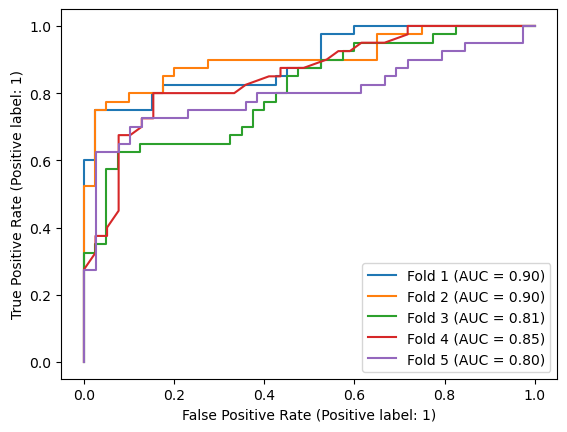

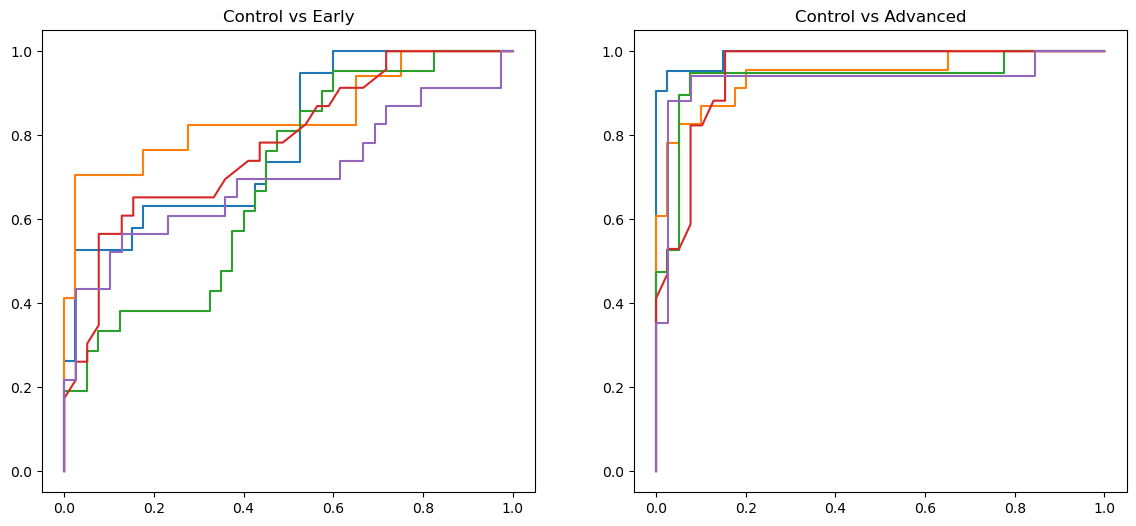

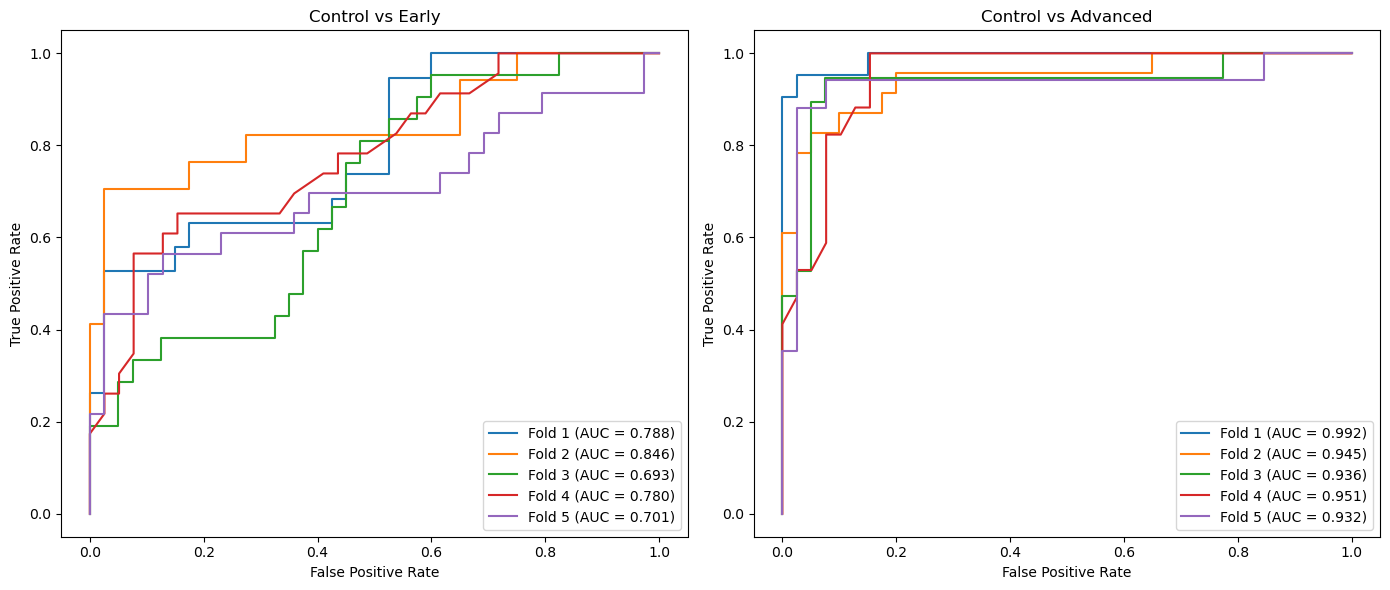


Control vs Early
各foldのAUC: [0.7882 0.8456 0.6929 0.7798 0.7012]
平均AUC: 0.7615
標準偏差: 0.0642

Control vs Advanced
各foldのAUC: [0.9917 0.9446 0.9355 0.951  0.9321]
平均AUC: 0.9510
標準偏差: 0.0239


,Fold,AUC,Accuracy,Sensitivity,Specificity,False Positive Rate,False Negative Rate,PPV,NPV
0,1,0.8950,0.8625,0.750,0.9750,0.0250,0.250,0.9677,0.7959
1,2,0.9025,0.8250,0.800,0.8500,0.1500,0.200,0.8421,0.8095
2,3,0.8081,0.7750,0.625,0.9250,0.0750,0.375,0.8929,0.7115
3,4,0.8526,0.7848,0.800,0.7692,0.2308,0.200,0.7805,0.7895
4,5,0.7994,0.7975,0.725,0.8718,0.1282,0.275,0.8529,0.7556


,Metric,Mean,SD
0,AUC,0.8515,0.0477
1,Accuracy,0.8090,0.0353
2,Sensitivity,0.7400,0.0720
3,Specificity,0.8782,0.0779
4,False Positive Rate,0.1218,0.0779
5,False Negative Rate,0.2600,0.0720
6,PPV,0.8672,0.0691
7,NPV,0.7724,0.0394


,Protein,Importance,SD_Importance
0,logvalue,0.184590,0.038522
14,GP2,0.086885,0.011061
11,CTRL,0.062385,0.012250
18,MUC16,0.060215,0.013840
19,PNLIPRP1,0.054841,0.010199
7,ANXA10,0.047609,0.011244
21,S100A12,0.038233,0.012577
8,CCL20,0.037059,0.006054
22,SERPINI2,0.035026,0.004724
23,TMPRSS15,0.034031,0.011373


結果を保存しました: ./RF_Data/RF_status_DEPca199


In [93]:
import time
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=123)
aucs = []
fig, ax = plt.subplots()

# ==========================================
# progress_group別ROC用の図
# ==========================================
fig_progress, axes_progress = plt.subplots(1, 2, figsize=(14, 6))

axes_progress[0].set_title("Control vs Early")
axes_progress[1].set_title("Control vs Advanced")

progress_auc = {
    "Early": [],
    "Advanced": []
}

# 各foldの予測結果を保存
y_prob_all = np.full(len(y), np.nan)
y_true_all = np.full(len(y), np.nan)
feature_importances = []

# 追加：各foldの評価指標・最適パラメータを保存
fold_metrics = []
best_params_all = []

save_dir = "./RF_Data/RF_status_DEPca199"
os.makedirs(save_dir, exist_ok=True)

for i, (train_index, test_index) in enumerate(skf.split(X, y)):

    X_train, X_test = X.iloc[train_index], X.iloc[test_index]
    y_train, y_test = y.iloc[train_index], y.iloc[test_index]

    param_grid = {
        'n_estimators': [50, 100, 300, 500],
        "max_depth": [None, 3, 5, 10, 15],
        'min_samples_leaf': [1, 2, 4],
        'max_features': [None, 'sqrt'],
        'class_weight': ['balanced']
    }
    # param_grid = {
    #     'n_estimators': [50],
    #     "max_depth": [10],
    #     'min_samples_leaf': [4],
    #     'max_features': ['sqrt'],
    #     'class_weight': ['balanced']
    # }

    model = RandomForestClassifier(
        criterion='gini',
        random_state=123,
        n_jobs=1
    )

    cv_gen = StratifiedKFold(n_splits=5, shuffle=True, random_state=123)

    modelcv = GridSearchCV(
        model,
        param_grid=param_grid,
        scoring='roc_auc',
        n_jobs=1,
        refit=True,
        cv=cv_gen,
        verbose=0,
        pre_dispatch='2*n_jobs',
        error_score=np.nan,
        return_train_score=False
    )

    start = time.time()
    modelcv.fit(X_train, y_train)
    elapsed = time.time() - start

    print(f"1回のGridSearchCV: {elapsed / 60:.2f} 分")
    print(f"全5 foldの推定時間: {elapsed * 5 / 60:.2f} 分")
    print('Best score: ', modelcv.best_score_)
    print('Best hyperparameters: ', modelcv.best_params_)

    # 追加：各foldの最適パラメータを保存
    best_params_all.append({
        "Fold": i + 1,
        "Best_Params": modelcv.best_params_
    })

    dataframe = pd.DataFrame(
        modelcv.cv_results_
    ).sort_values('mean_test_score', ascending=False)
    display(dataframe)

    model = modelcv.best_estimator_


    # Foldごとの学習済みモデルを保存
    joblib.dump(
        model,
        f"{save_dir}/rf_model_fold_{i+1}.joblib"
    )
    
    # Foldごとのテストデータを保存
    X_test.to_csv(
        f"{save_dir}/X_test_fold_{i+1}.csv",
        index=True
    )
    
    # テストデータの正解ラベルを保存
    y_test.to_csv(
        f"{save_dir}/y_test_fold_{i+1}.csv",
        index=True
    )
    
    # 特徴量名を保存
    pd.Series(X.columns).to_csv(
        f"{save_dir}/feature_names.csv",
        index=False,
        header=["Feature"]
    )

    # 予測確率とAUC
    y_prob = model.predict_proba(X_test)[:, 1]
    score = roc_auc_score(y_test, y_prob)
    aucs.append(score)


    # ==========================================
    # progress_group別ROC曲線
    # ==========================================

    # テストデータのprogress_groupを取得
    # pro_sampleとXは同じ行順であることを前提とする
    progress_test = (
        pro_sample["progress_group"]
        .iloc[test_index]
        .astype(str)
        .str.strip()
        .str.lower()
    )
    comparisons = [
        {"name": "Early", "positive": ["1", "early"], "ax": axes_progress[0]},
        {"name": "Advanced", "positive": ["2", "advanced", "advanced/metastatic"], "ax": axes_progress[1]}
    ]
    
    for comp in comparisons:
        mask = (
            progress_test.isin(["0", "control"]) |
            progress_test.isin(comp["positive"])
        )
    
        progress_labels = (
            progress_test[mask].isin(comp["positive"]).astype(int)
        )
        prob_subset = y_prob[mask.to_numpy()]
    
        if progress_labels.nunique() == 2:
            fpr, tpr, thresholds = roc_curve(
                progress_labels, prob_subset
            )
            auc_progress = roc_auc_score(
                progress_labels, prob_subset
            )
    
            # 各foldのAUCをlegendに表示
            comp["ax"].plot(
                fpr,
                tpr,
                label=f"Fold {i+1} (AUC = {auc_progress:.3f})"
            )
    
            progress_auc[comp["name"]].append(auc_progress)


    # OOF予測を保存
    y_prob_all[test_index] = y_prob
    y_true_all[test_index] = np.asarray(y_test)

    # 各foldの特徴量重要度
    feature_importances.append(model.feature_importances_)

    # 追加：各foldの評価指標を計算
    y_pred = (y_prob >= 0.5).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        y_test, y_pred, labels=[0, 1]
    ).ravel()

    fold_metrics.append({
        "Fold": i + 1,
        "AUC": score,
        "Accuracy": (tp + tn) / (tp + tn + fp + fn),
        "Sensitivity": tp / (tp + fn) if tp + fn else np.nan,
        "Specificity": tn / (tn + fp) if tn + fp else np.nan,
        "False Positive Rate": fp / (fp + tn) if fp + tn else np.nan,
        "False Negative Rate": fn / (fn + tp) if fn + tp else np.nan,
        "PPV": tp / (tp + fp) if tp + fp else np.nan,
        "NPV": tn / (tn + fn) if tn + fn else np.nan
    })

    print('AUC: ', score)

    RocCurveDisplay.from_predictions(
        y_test,
        y_prob,
        name=f"Fold {i+1}",
        ax=ax
    )

print(f"5-Fold平均AUC: {np.mean(aucs):.4f} ± {np.std(aucs, ddof=1):.4f}")
plt.show()
# ==========================================
# progress_group別ROC曲線を表示
# ==========================================

for ax in axes_progress:
    # ax.plot(
    #     [0, 1], [0, 1],
    #     linestyle="--",
    #     color="gray",
    #     label="Chance"
    # )
    # ax.set_xlim(0, 1)
    # ax.set_ylim(0, 1)
    ax.set_xlabel("False Positive Rate")
    ax.set_ylabel("True Positive Rate")
    ax.legend(loc="lower right")
    # ax.grid(alpha=0.3)

fig_progress.tight_layout()
display(fig_progress)
# ==========================================
# 各比較のfold別AUCと平均・標準偏差
# ==========================================

for group, values in progress_auc.items():

    print(f"\nControl vs {group}")

    if len(values) > 0:
        print("各foldのAUC:", np.round(values, 4))
        print(f"平均AUC: {np.mean(values):.4f}")
        print(
            f"標準偏差: "
            f"{np.std(values, ddof=1):.4f}"
            if len(values) > 1
            else "標準偏差: 算出不可（有効なfoldが1つ）"
        )
    else:
        print("ROCを計算できるfoldがありません。")
# ==========================================
# 全foldの予測結果を保存
# ==========================================
y_true_all = y_true_all.astype(int)
y_pred_all = (y_prob_all >= 0.5).astype(int)

oof_df = pd.DataFrame({
    "TrueClass": y_true_all,
    "PredictedProbability": y_prob_all,
    "PredictedClass": y_pred_all
}, index=X.index)

oof_df.index.name = "SampleID"
oof_df.to_csv(f"{save_dir}/oof_predictions.csv")

# ==========================================
# 各foldの評価指標と平均・標準偏差を保存
# ==========================================
fold_metrics_df = pd.DataFrame(fold_metrics)

# 各foldの結果
display(fold_metrics_df.round(4))
fold_metrics_df.to_csv(
    f"{save_dir}/metrics_each_fold.csv",
    index=False
)

# 5-foldの平均と標準偏差
metrics_df = pd.DataFrame({
    "Metric": fold_metrics_df.columns.drop("Fold"),
    "Mean": [
        fold_metrics_df[col].mean()
        for col in fold_metrics_df.columns.drop("Fold")
    ],
    "SD": [
        fold_metrics_df[col].std(ddof=1)
        for col in fold_metrics_df.columns.drop("Fold")
    ]
})

display(metrics_df.round(4))
metrics_df.to_csv(f"{save_dir}/metrics.csv", index=False)

# ==========================================
# foldごとの特徴量重要度の平均を保存
# ==========================================
importance_df = pd.DataFrame({
    "Protein": X.columns,
    "Importance": np.mean(feature_importances, axis=0),
    "SD_Importance": np.std(feature_importances, axis=0, ddof=1)
}).sort_values("Importance", ascending=False)

importance_df.to_csv(
    f"{save_dir}/feature_importance.csv",
    index=False
)

display(importance_df.head(20))

# ==========================================
# 各foldの最適パラメータ5つを保存
# ==========================================
with open(f"{save_dir}/best_parameters.json", "w") as f:
    json.dump(
        best_params_all,
        f,
        indent=2,
        default=str
    )

print("結果を保存しました:", save_dir)

In [97]:
import os
import joblib
import numpy as np
import pandas as pd
from sklearn.metrics import confusion_matrix, accuracy_score, roc_auc_score

save_dir = "./RF_Data/RF_status_DEPca199"

fold_metrics = []

for i in range(1, 6):

    # ==========================================
    # 保存済みファイルを読み込む
    # ==========================================
    model = joblib.load(
        f"{save_dir}/rf_model_fold_{i}.joblib"
    )

    X_test = pd.read_csv(
        f"{save_dir}/X_test_fold_{i}.csv",
        index_col=0
    )

    y_test = pd.read_csv(
        f"{save_dir}/y_test_fold_{i}.csv",
        index_col=0
    ).iloc[:, 0]

    # X_testのサンプル順に合わせてprogress_groupを取得
    progress_test = (
        pro_sample.loc[X_test.index, "progress_group"]
        .astype(str)
        .str.strip()
        .str.lower()
    )

    # ControlとEarlyだけを抽出
    control_mask = progress_test.isin(["0", "control"])
    early_mask = progress_test.isin(["1", "early"])
    mask = control_mask | early_mask

    X_sub = X_test.loc[mask]
    progress_sub = progress_test.loc[mask]

    # Control=0、Early=1
    y_true = early_mask.loc[mask].astype(int).to_numpy()

    # 保存済みモデルで予測（再学習なし）
    y_prob = model.predict_proba(X_sub)[:, 1]
    y_pred = (y_prob >= 0.5).astype(int)

    # ==========================================
    # 評価指標を計算
    # ==========================================
    tn, fp, fn, tp = confusion_matrix(
        y_true, y_pred, labels=[0, 1]
    ).ravel()

    fold_metrics.append({
        "Fold": i,
        "AUC": roc_auc_score(y_true, y_prob),
        "Accuracy": accuracy_score(y_true, y_pred),
        "Sensitivity": tp / (tp + fn) if tp + fn else np.nan,
        "Specificity": tn / (tn + fp) if tn + fp else np.nan
    })

# ==========================================
# Foldごとの結果
# ==========================================
metrics_df = pd.DataFrame(fold_metrics)
display(metrics_df.round(4))

# ==========================================
# 平均 ± SD
# ==========================================
summary = pd.DataFrame({
    "Mean": metrics_df.drop(columns="Fold").mean(),
    "SD": metrics_df.drop(columns="Fold").std(ddof=1)
})

summary["Mean ± SD"] = summary.apply(
    lambda row: f"{row['Mean']:.3f} ± {row['SD']:.3f}",
    axis=1
)

display(summary[["Mean ± SD"]])

,Fold,AUC,Accuracy,Sensitivity,Specificity
0,1,0.7882,0.8305,0.5263,0.9750
1,2,0.8456,0.8070,0.7059,0.8500
2,3,0.6929,0.7213,0.3333,0.9250
3,4,0.7798,0.7258,0.6522,0.7692
4,5,0.7012,0.7581,0.5652,0.8718


,Mean ± SD
AUC,0.762 ± 0.064
Accuracy,0.769 ± 0.049
Sensitivity,0.557 ± 0.143
Specificity,0.878 ± 0.078


### 120人の方で検証

In [ ]:
display(pro_data_dis)

In [ ]:
dep = pro_data_dis.loc[:, pro_data_dis.columns.isin(DEPlist.index)]
X = pd.concat([
    ca199_dis[['logvalue']],
    dep
], axis=1)

y = pro_sample_dis['groupset2']
print(X.shape)
print(y.shape)

print(X.index[:5])
print(y.index[:5])

In [ ]:
display(X)

In [ ]:
val_probs = []
val_aucs = []

fig, ax = plt.subplots()

for i, model in enumerate(modelsets_HER_DEP_ca199):

    y_val = model.predict_proba(X)[:, 1]
    val_probs.append(y_val)

    auc_val = roc_auc_score(y, y_val)
    val_aucs.append(auc_val)

    print(f"Fold {i+1} Validation AUC: {auc_val:.4f}")

    RocCurveDisplay.from_predictions(
        y,
        y_val,
        name=f"Fold {i+1} (AUC = {auc_val:.3f})",
        ax=ax
    )

# 5モデルの予測確率を平均
val_probs = np.array(val_probs)
y_val_mean = val_probs.mean(axis=0)

# Ensemble AUC
auc_mean = roc_auc_score(y, y_val_mean)

# 平均予測のROC
RocCurveDisplay.from_predictions(
    y,
    y_val_mean,
    name=f"Mean prediction (AUC = {auc_mean:.3f})",
    ax=ax
)

# 5モデルのAUCの平均と標準偏差
auc_val_mean = np.mean(val_aucs)
auc_val_sd = np.std(val_aucs, ddof=1)

print(f"Validation AUC: {auc_val_mean:.4f} ± {auc_val_sd:.4f}")

ax.plot([0, 1], [0, 1], linestyle="--")

ax.set_title("Validation ROC curves")
plt.show()

print(f"Ensemble Validation AUC: {auc_mean:.4f}")

## All + CA19-9

In [83]:
dep = pro_data.loc[:, pro_data.columns.isin(DEPlist.index)]
X = pd.concat([
    ca199[['logvalue']],
    pro_data
], axis=1)

y = pro_sample['CaCo_Status']
print(X.shape)
print(y.shape)

print(X.index[:5])
print(y.index[:5])

(398, 1034)
(398,)
Index(['PE_R478_001', 'PE_R478_002', 'PE_R478_003', 'PE_R478_004',
       'PE_R478_005'],
      dtype='object', name='SampleID')
Index(['PE_R478_001', 'PE_R478_002', 'PE_R478_003', 'PE_R478_004',
       'PE_R478_005'],
      dtype='object')


1回のGridSearchCV: 75.54 分
全5 foldの推定時間: 377.70 分
Best score:  0.840297379032258
Best hyperparameters:  {'class_weight': 'balanced', 'max_depth': 5, 'max_features': None, 'min_samples_leaf': 2, 'n_estimators': 100}


,mean_fit_time,std_fit_time,mean_score_time,std_score_time,param_class_weight,param_max_depth,param_max_features,param_min_samples_leaf,param_n_estimators,params,split0_test_score,split1_test_score,split2_test_score,split3_test_score,split4_test_score,mean_test_score,std_test_score,rank_test_score
53,5.813873,0.087374,0.008606,0.000102,balanced,5,None,2,100,"{'class_weight': 'balanced', 'max_depth': 5, '...",0.801758,0.802734,0.836914,0.856855,0.903226,0.840297,0.037794,1
57,5.481307,0.039215,0.008699,0.000210,balanced,5,None,4,100,"{'class_weight': 'balanced', 'max_depth': 5, '...",0.811523,0.801758,0.837891,0.853831,0.896169,0.840234,0.033538,2
49,5.927994,0.090575,0.008789,0.000173,balanced,5,None,1,100,"{'class_weight': 'balanced', 'max_depth': 5, '...",0.804688,0.811523,0.833984,0.848790,0.899194,0.839636,0.033688,3
51,29.630028,0.376312,0.023842,0.000140,balanced,5,None,1,500,"{'class_weight': 'balanced', 'max_depth': 5, '...",0.793945,0.806641,0.831055,0.860887,0.897177,0.837941,0.037412,4
25,4.195469,0.040446,0.008519,0.000062,balanced,3,None,1,100,"{'class_weight': 'balanced', 'max_depth': 3, '...",0.781250,0.786133,0.843750,0.855847,0.919355,0.837267,0.050751,5
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
68,0.133635,0.005388,0.006849,0.000319,balanced,5,sqrt,4,50,"{'class_weight': 'balanced', 'max_depth': 5, '...",0.794922,0.676758,0.853516,0.816532,0.804435,0.789233,0.059652,116
84,0.165058,0.002083,0.006628,0.000071,balanced,10,sqrt,1,50,"{'class_weight': 'balanced', 'max_depth': 10, ...",0.834961,0.638672,0.800293,0.840726,0.829133,0.788757,0.076321,117
44,0.103197,0.002895,0.006858,0.000355,balanced,3,sqrt,4,50,"{'class_weight': 'balanced', 'max_depth': 3, '...",0.852539,0.630859,0.817383,0.843750,0.790323,0.786971,0.081031,118
12,0.163695,0.003418,0.006763,0.000213,balanced,None,sqrt,1,50,"{'class_weight': 'balanced', 'max_depth': None...",0.831055,0.643066,0.792969,0.843750,0.820565,0.786281,0.073536,119


AUC:  0.8537500000000001
1回のGridSearchCV: 76.81 分
全5 foldの推定時間: 384.06 分
Best score:  0.852280745967742
Best hyperparameters:  {'class_weight': 'balanced', 'max_depth': 5, 'max_features': None, 'min_samples_leaf': 1, 'n_estimators': 500}


,mean_fit_time,std_fit_time,mean_score_time,std_score_time,param_class_weight,param_max_depth,param_max_features,param_min_samples_leaf,param_n_estimators,params,split0_test_score,split1_test_score,split2_test_score,split3_test_score,split4_test_score,mean_test_score,std_test_score,rank_test_score
51,29.415336,0.234002,0.024779,0.000864,balanced,5,None,1,500,"{'class_weight': 'balanced', 'max_depth': 5, '...",0.855469,0.902344,0.919922,0.856855,0.726815,0.852281,0.067608,1
59,27.397925,0.143534,0.024782,0.001074,balanced,5,None,4,500,"{'class_weight': 'balanced', 'max_depth': 5, '...",0.851562,0.902344,0.921875,0.856855,0.726815,0.851890,0.067988,2
50,17.732620,0.223039,0.016346,0.000122,balanced,5,None,1,300,"{'class_weight': 'balanced', 'max_depth': 5, '...",0.855469,0.897461,0.916992,0.850806,0.731855,0.850517,0.064386,3
103,35.485039,1.031084,0.024743,0.000784,balanced,15,None,2,500,"{'class_weight': 'balanced', 'max_depth': 15, ...",0.848633,0.889648,0.926758,0.860887,0.723790,0.849943,0.068576,4
7,35.439647,1.075988,0.025156,0.001041,balanced,None,None,2,500,"{'class_weight': 'balanced', 'max_depth': None...",0.848633,0.889648,0.926758,0.860887,0.723790,0.849943,0.068576,4
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
37,0.201429,0.000919,0.008471,0.000102,balanced,3,sqrt,1,100,"{'class_weight': 'balanced', 'max_depth': 3, '...",0.803711,0.812500,0.921875,0.767137,0.626008,0.786246,0.095321,116
45,0.196997,0.001237,0.008541,0.000104,balanced,3,sqrt,4,100,"{'class_weight': 'balanced', 'max_depth': 3, '...",0.782227,0.815430,0.912109,0.777218,0.632056,0.783808,0.090040,117
36,0.103403,0.000520,0.006582,0.000077,balanced,3,sqrt,1,50,"{'class_weight': 'balanced', 'max_depth': 3, '...",0.791992,0.784180,0.919922,0.760081,0.614919,0.774219,0.097181,118
40,0.102308,0.000528,0.006580,0.000047,balanced,3,sqrt,2,50,"{'class_weight': 'balanced', 'max_depth': 3, '...",0.785156,0.771484,0.923828,0.756048,0.623992,0.772102,0.095274,119


AUC:  0.8849999999999999
1回のGridSearchCV: 74.79 分
全5 foldの推定時間: 373.96 分
Best score:  0.846811995967742
Best hyperparameters:  {'class_weight': 'balanced', 'max_depth': None, 'max_features': None, 'min_samples_leaf': 2, 'n_estimators': 300}


...

AUC:  0.81
1回のGridSearchCV: 75.67 分
全5 foldの推定時間: 378.34 分
Best score:  0.8645602318548388
Best hyperparameters:  {'class_weight': 'balanced', 'max_depth': 5, 'max_features': None, 'min_samples_leaf': 4, 'n_estimators': 300}


,mean_fit_time,std_fit_time,mean_score_time,std_score_time,param_class_weight,param_max_depth,param_max_features,param_min_samples_leaf,param_n_estimators,params,split0_test_score,split1_test_score,split2_test_score,split3_test_score,split4_test_score,mean_test_score,std_test_score,rank_test_score
58,16.231872,0.122238,0.016319,0.000164,balanced,5,None,4,300,"{'class_weight': 'balanced', 'max_depth': 5, '...",0.896484,0.847656,0.829102,0.888672,0.860887,0.864560,0.025128,1
54,17.078399,0.155343,0.016774,0.000456,balanced,5,None,2,300,"{'class_weight': 'balanced', 'max_depth': 5, '...",0.895508,0.856445,0.830078,0.884766,0.853831,0.864126,0.023388,2
50,17.345925,0.176075,0.016281,0.000046,balanced,5,None,1,300,"{'class_weight': 'balanced', 'max_depth': 5, '...",0.894531,0.851562,0.830078,0.892578,0.851815,0.864113,0.025309,3
55,28.438861,0.229757,0.024575,0.000809,balanced,5,None,2,500,"{'class_weight': 'balanced', 'max_depth': 5, '...",0.895508,0.861328,0.823242,0.891602,0.848790,0.864094,0.027034,4
51,28.913349,0.260543,0.024303,0.000271,balanced,5,None,1,500,"{'class_weight': 'balanced', 'max_depth': 5, '...",0.894531,0.860352,0.825195,0.892578,0.845766,0.863684,0.026833,5
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
40,0.104374,0.002987,0.006773,0.000281,balanced,3,sqrt,2,50,"{'class_weight': 'balanced', 'max_depth': 3, '...",0.839844,0.841797,0.885742,0.779297,0.681452,0.805626,0.070725,116
16,0.157655,0.003478,0.006612,0.000052,balanced,None,sqrt,2,50,"{'class_weight': 'balanced', 'max_depth': None...",0.877930,0.802734,0.856445,0.831055,0.659778,0.805588,0.077119,117
112,0.159025,0.002594,0.006770,0.000192,balanced,15,sqrt,2,50,"{'class_weight': 'balanced', 'max_depth': 15, ...",0.877930,0.802734,0.856445,0.831055,0.659778,0.805588,0.077119,117
44,0.102658,0.003130,0.006594,0.000134,balanced,3,sqrt,4,50,"{'class_weight': 'balanced', 'max_depth': 3, '...",0.849609,0.828125,0.875977,0.787109,0.677419,0.803648,0.069498,119


AUC:  0.8320512820512822
1回のGridSearchCV: 74.47 分
全5 foldの推定時間: 372.35 分
Best score:  0.852183089717742
Best hyperparameters:  {'class_weight': 'balanced', 'max_depth': 5, 'max_features': None, 'min_samples_leaf': 1, 'n_estimators': 50}


,mean_fit_time,std_fit_time,mean_score_time,std_score_time,param_class_weight,param_max_depth,param_max_features,param_min_samples_leaf,param_n_estimators,params,split0_test_score,split1_test_score,split2_test_score,split3_test_score,split4_test_score,mean_test_score,std_test_score,rank_test_score
48,2.885981,0.027973,0.006749,0.000050,balanced,5,None,1,50,"{'class_weight': 'balanced', 'max_depth': 5, '...",0.940430,0.838379,0.839844,0.792969,0.849294,0.852183,0.048260,1
52,2.828357,0.022291,0.006718,0.000068,balanced,5,None,2,50,"{'class_weight': 'balanced', 'max_depth': 5, '...",0.936523,0.832031,0.848633,0.789062,0.838710,0.848992,0.048263,2
50,17.453242,0.187840,0.016531,0.000297,balanced,5,None,1,300,"{'class_weight': 'balanced', 'max_depth': 5, '...",0.934570,0.829102,0.823242,0.820312,0.834677,0.848381,0.043377,3
28,2.026895,0.022720,0.006939,0.000415,balanced,3,None,2,50,"{'class_weight': 'balanced', 'max_depth': 3, '...",0.948242,0.811523,0.826172,0.783203,0.869960,0.847820,0.057509,4
8,3.060227,0.041659,0.006726,0.000085,balanced,None,None,4,50,"{'class_weight': 'balanced', 'max_depth': None...",0.958984,0.821289,0.837891,0.761719,0.856855,0.847348,0.064271,5
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
44,0.104512,0.004876,0.006846,0.000371,balanced,3,sqrt,4,50,"{'class_weight': 'balanced', 'max_depth': 3, '...",0.854492,0.811523,0.796875,0.762695,0.856855,0.816488,0.035712,116
92,0.143478,0.005748,0.006930,0.000455,balanced,10,sqrt,4,50,"{'class_weight': 'balanced', 'max_depth': 10, ...",0.868164,0.799805,0.770508,0.747070,0.895161,0.816142,0.056693,117
20,0.139721,0.001189,0.006658,0.000065,balanced,None,sqrt,4,50,"{'class_weight': 'balanced', 'max_depth': None...",0.867188,0.800781,0.770508,0.747070,0.895161,0.816142,0.056461,117
116,0.140603,0.001294,0.006643,0.000048,balanced,15,sqrt,4,50,"{'class_weight': 'balanced', 'max_depth': 15, ...",0.867188,0.800781,0.770508,0.747070,0.895161,0.816142,0.056461,117


AUC:  0.841025641025641
5-Fold平均AUC: 0.8444 ± 0.0278


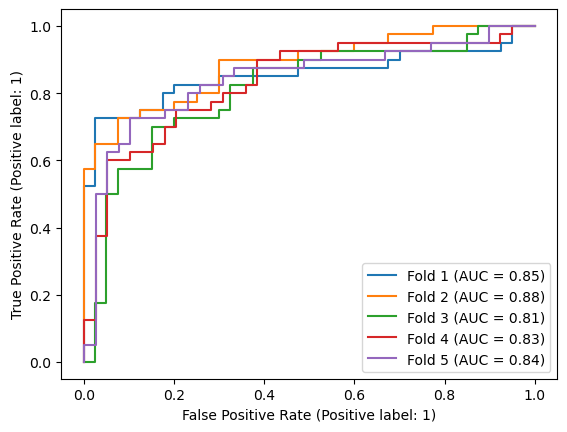

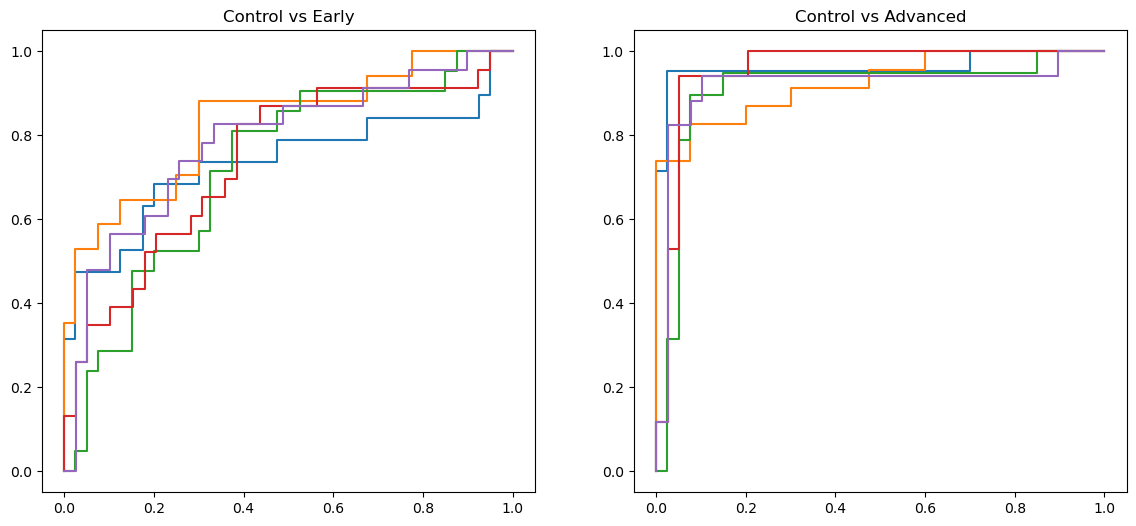

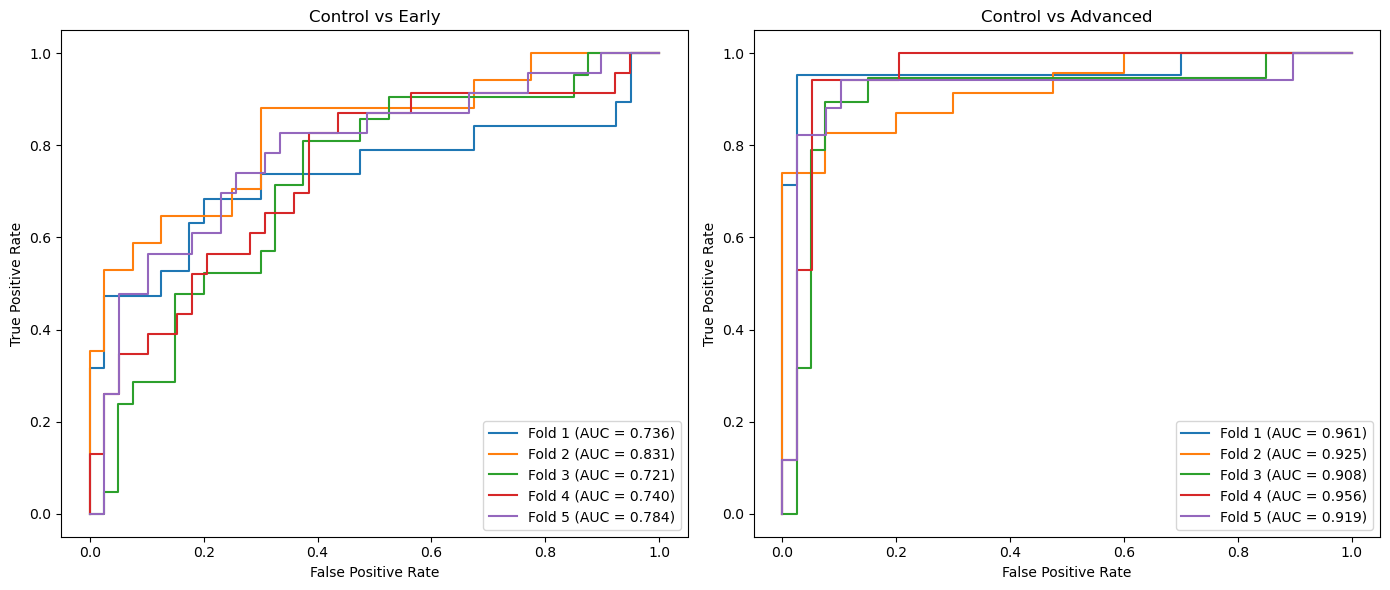


Control vs Early
各foldのAUC: [0.7355 0.8309 0.7214 0.7402 0.7837]
平均AUC: 0.7624
標準偏差: 0.0448

Control vs Advanced
各foldのAUC: [0.9607 0.925  0.9079 0.9563 0.9186]
平均AUC: 0.9337
標準偏差: 0.0235


,Fold,AUC,Accuracy,Sensitivity,Specificity,False Positive Rate,False Negative Rate,PPV,NPV
0,1,0.8538,0.8500,0.725,0.9750,0.0250,0.275,0.9667,0.7800
1,2,0.8850,0.8000,0.725,0.8750,0.1250,0.275,0.8529,0.7609
2,3,0.8100,0.7250,0.600,0.8500,0.1500,0.400,0.8000,0.6800
3,4,0.8321,0.7468,0.750,0.7436,0.2564,0.250,0.7500,0.7436
4,5,0.8410,0.7722,0.650,0.8974,0.1026,0.350,0.8667,0.7143


,Metric,Mean,SD
0,AUC,0.8444,0.0278
1,Accuracy,0.7788,0.0487
2,Sensitivity,0.6900,0.0627
3,Specificity,0.8682,0.0839
4,False Positive Rate,0.1318,0.0839
5,False Negative Rate,0.3100,0.0627
6,PPV,0.8473,0.0812
7,NPV,0.7357,0.0394


,Protein,Importance,SD_Importance
0,logvalue,0.340921,0.020046
596,GP2,0.048040,0.021066
114,CFC1,0.043399,0.018505
499,CTRL,0.018229,0.015559
422,CCL20,0.014201,0.014230
940,TXLNA,0.011149,0.004495
735,MSTN,0.010945,0.010467
178,IL17A,0.009097,0.007266
796,PNLIPRP1,0.008155,0.002168
737,MUC16,0.007160,0.008784


結果を保存しました: ./RF_Data/RF_status_Allca199


In [84]:
import time
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=123)
aucs = []
fig, ax = plt.subplots()

# ==========================================
# progress_group別ROC用の図
# ==========================================
fig_progress, axes_progress = plt.subplots(1, 2, figsize=(14, 6))

axes_progress[0].set_title("Control vs Early")
axes_progress[1].set_title("Control vs Advanced")

progress_auc = {
    "Early": [],
    "Advanced": []
}

# 各foldの予測結果を保存
y_prob_all = np.full(len(y), np.nan)
y_true_all = np.full(len(y), np.nan)
feature_importances = []

# 追加：各foldの評価指標・最適パラメータを保存
fold_metrics = []
best_params_all = []

save_dir = "./RF_Data/RF_status_Allca199"
os.makedirs(save_dir, exist_ok=True)

for i, (train_index, test_index) in enumerate(skf.split(X, y)):

    X_train, X_test = X.iloc[train_index], X.iloc[test_index]
    y_train, y_test = y.iloc[train_index], y.iloc[test_index]

    param_grid = {
        'n_estimators': [50, 100, 300, 500],
        "max_depth": [None, 3, 5, 10, 15],
        'min_samples_leaf': [1, 2, 4],
        'max_features': [None, 'sqrt'],
        'class_weight': ['balanced']
    }
    # param_grid = {
    #     'n_estimators': [50],
    #     "max_depth": [10],
    #     'min_samples_leaf': [4],
    #     'max_features': ['sqrt'],
    #     'class_weight': ['balanced']
    # }

    model = RandomForestClassifier(
        criterion='gini',
        random_state=123,
        n_jobs=1
    )

    cv_gen = StratifiedKFold(n_splits=5, shuffle=True, random_state=123)

    modelcv = GridSearchCV(
        model,
        param_grid=param_grid,
        scoring='roc_auc',
        n_jobs=1,
        refit=True,
        cv=cv_gen,
        verbose=0,
        pre_dispatch='2*n_jobs',
        error_score=np.nan,
        return_train_score=False
    )

    start = time.time()
    modelcv.fit(X_train, y_train)
    elapsed = time.time() - start

    print(f"1回のGridSearchCV: {elapsed / 60:.2f} 分")
    print(f"全5 foldの推定時間: {elapsed * 5 / 60:.2f} 分")
    print('Best score: ', modelcv.best_score_)
    print('Best hyperparameters: ', modelcv.best_params_)

    # 追加：各foldの最適パラメータを保存
    best_params_all.append({
        "Fold": i + 1,
        "Best_Params": modelcv.best_params_
    })

    dataframe = pd.DataFrame(
        modelcv.cv_results_
    ).sort_values('mean_test_score', ascending=False)
    display(dataframe)

    model = modelcv.best_estimator_

    # 予測確率とAUC
    y_prob = model.predict_proba(X_test)[:, 1]
    score = roc_auc_score(y_test, y_prob)
    aucs.append(score)


    # ==========================================
    # progress_group別ROC曲線
    # ==========================================

    # テストデータのprogress_groupを取得
    # pro_sampleとXは同じ行順であることを前提とする
    progress_test = (
        pro_sample["progress_group"]
        .iloc[test_index]
        .astype(str)
        .str.strip()
        .str.lower()
    )
    comparisons = [
        {"name": "Early", "positive": ["1", "early"], "ax": axes_progress[0]},
        {"name": "Advanced", "positive": ["2", "advanced", "advanced/metastatic"], "ax": axes_progress[1]}
    ]
    
    for comp in comparisons:
        mask = (
            progress_test.isin(["0", "control"]) |
            progress_test.isin(comp["positive"])
        )
    
        progress_labels = (
            progress_test[mask].isin(comp["positive"]).astype(int)
        )
        prob_subset = y_prob[mask.to_numpy()]
    
        if progress_labels.nunique() == 2:
            fpr, tpr, thresholds = roc_curve(
                progress_labels, prob_subset
            )
            auc_progress = roc_auc_score(
                progress_labels, prob_subset
            )
    
            # 各foldのAUCをlegendに表示
            comp["ax"].plot(
                fpr,
                tpr,
                label=f"Fold {i+1} (AUC = {auc_progress:.3f})"
            )
    
            progress_auc[comp["name"]].append(auc_progress)


    # OOF予測を保存
    y_prob_all[test_index] = y_prob
    y_true_all[test_index] = np.asarray(y_test)

    # 各foldの特徴量重要度
    feature_importances.append(model.feature_importances_)

    # 追加：各foldの評価指標を計算
    y_pred = (y_prob >= 0.5).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        y_test, y_pred, labels=[0, 1]
    ).ravel()

    fold_metrics.append({
        "Fold": i + 1,
        "AUC": score,
        "Accuracy": (tp + tn) / (tp + tn + fp + fn),
        "Sensitivity": tp / (tp + fn) if tp + fn else np.nan,
        "Specificity": tn / (tn + fp) if tn + fp else np.nan,
        "False Positive Rate": fp / (fp + tn) if fp + tn else np.nan,
        "False Negative Rate": fn / (fn + tp) if fn + tp else np.nan,
        "PPV": tp / (tp + fp) if tp + fp else np.nan,
        "NPV": tn / (tn + fn) if tn + fn else np.nan
    })

    print('AUC: ', score)

    RocCurveDisplay.from_predictions(
        y_test,
        y_prob,
        name=f"Fold {i+1}",
        ax=ax
    )

print(f"5-Fold平均AUC: {np.mean(aucs):.4f} ± {np.std(aucs, ddof=1):.4f}")
plt.show()
# ==========================================
# progress_group別ROC曲線を表示
# ==========================================

for ax in axes_progress:
    # ax.plot(
    #     [0, 1], [0, 1],
    #     linestyle="--",
    #     color="gray",
    #     label="Chance"
    # )
    # ax.set_xlim(0, 1)
    # ax.set_ylim(0, 1)
    ax.set_xlabel("False Positive Rate")
    ax.set_ylabel("True Positive Rate")
    ax.legend(loc="lower right")
    # ax.grid(alpha=0.3)

fig_progress.tight_layout()
display(fig_progress)
# ==========================================
# 各比較のfold別AUCと平均・標準偏差
# ==========================================

for group, values in progress_auc.items():

    print(f"\nControl vs {group}")

    if len(values) > 0:
        print("各foldのAUC:", np.round(values, 4))
        print(f"平均AUC: {np.mean(values):.4f}")
        print(
            f"標準偏差: "
            f"{np.std(values, ddof=1):.4f}"
            if len(values) > 1
            else "標準偏差: 算出不可（有効なfoldが1つ）"
        )
    else:
        print("ROCを計算できるfoldがありません。")
# ==========================================
# 全foldの予測結果を保存
# ==========================================
y_true_all = y_true_all.astype(int)
y_pred_all = (y_prob_all >= 0.5).astype(int)

oof_df = pd.DataFrame({
    "TrueClass": y_true_all,
    "PredictedProbability": y_prob_all,
    "PredictedClass": y_pred_all
}, index=X.index)

oof_df.index.name = "SampleID"
oof_df.to_csv(f"{save_dir}/oof_predictions.csv")

# ==========================================
# 各foldの評価指標と平均・標準偏差を保存
# ==========================================
fold_metrics_df = pd.DataFrame(fold_metrics)

# 各foldの結果
display(fold_metrics_df.round(4))
fold_metrics_df.to_csv(
    f"{save_dir}/metrics_each_fold.csv",
    index=False
)

# 5-foldの平均と標準偏差
metrics_df = pd.DataFrame({
    "Metric": fold_metrics_df.columns.drop("Fold"),
    "Mean": [
        fold_metrics_df[col].mean()
        for col in fold_metrics_df.columns.drop("Fold")
    ],
    "SD": [
        fold_metrics_df[col].std(ddof=1)
        for col in fold_metrics_df.columns.drop("Fold")
    ]
})

display(metrics_df.round(4))
metrics_df.to_csv(f"{save_dir}/metrics.csv", index=False)

# ==========================================
# foldごとの特徴量重要度の平均を保存
# ==========================================
importance_df = pd.DataFrame({
    "Protein": X.columns,
    "Importance": np.mean(feature_importances, axis=0),
    "SD_Importance": np.std(feature_importances, axis=0, ddof=1)
}).sort_values("Importance", ascending=False)

importance_df.to_csv(
    f"{save_dir}/feature_importance.csv",
    index=False
)

display(importance_df.head(20))

# ==========================================
# 各foldの最適パラメータ5つを保存
# ==========================================
with open(f"{save_dir}/best_parameters.json", "w") as f:
    json.dump(
        best_params_all,
        f,
        indent=2,
        default=str
    )

print("結果を保存しました:", save_dir)

## CA-19-9とIL2RAの複合

In [ ]:

X = pd.concat(
    [
        ca199[["logvalue"]].rename(columns={"logvalue": "ca199_logvalue"}),
        il2ra[["logvalue"]].rename(columns={"logvalue": "il2ra_logvalue"})
    ],
    axis=1
)
y = pro_sample["CaCo_Status"]

print(X.shape)
print(y.shape)

print(X.index[:5])
print(y.index[:5])

### 2つの変数の「差」や「和」を新たな特徴量として加える

In [ ]:
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=123)
aucs = []
fig, ax = plt.subplots()

for i, (train_index, test_index) in enumerate(skf.split(X, y)):
    
    X_train, X_test = X.iloc[train_index], X.iloc[test_index]
    y_train, y_test = y.iloc[train_index], y.iloc[test_index]

# X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=123)
    pipe = Pipeline([
        ('scaler', StandardScaler()),
        ('classifier', LogisticRegression(class_weight='balanced', random_state=123, max_iter=1000))
    ])
    
    param_grid = {
        'classifier__C': [0.001, 0.01, 0.1, 1.0, 10.0, 100.0], # 正則化の強さ（小さいほど強力に過学習を防ぐ）
        'classifier__penalty': ['l2'] # Ridge正則化（変数を程よく残す設定）
    }
    
   
    
    cv_gen = StratifiedKFold(n_splits=5, shuffle=True, random_state=123)
    
    modelcv = GridSearchCV(
        pipe, 
        param_grid=param_grid,
        scoring='roc_auc',
        n_jobs=-1, 
        refit=True, 
        cv=cv_gen,
        verbose=0, 
        error_score=np.nan, 
        return_train_score=False
    )
    
    # 実行
    modelcv.fit(X_train, y_train)
    
    print(f'--- Fold {i+1} ---')
    print('Best score: ', modelcv.best_score_)
    print('Best hyperparameters: ', modelcv.best_params_)
    
    best_pipe = modelcv.best_estimator_
    coefficients = best_pipe.named_steps['classifier'].coef_[0]
    print(f"ca199の重み: {coefficients[0]:.4f}")
    print(f"il2raの重み: {coefficients[1]:.4f}")
    
    y_prob = best_pipe.predict_proba(X_test)[:, 1]
    score = roc_auc_score(y_test, y_prob)
    aucs.append(score)

    print('AUC: ', score)
    RocCurveDisplay.from_predictions(
        y_test,
        y_prob,
        name=f"Fold {i+1}", ax=ax
    )
    
print(f"5-Fold平均AUC: {np.mean(aucs):.4f} ± {np.std(aucs)}")
plt.show()



# CA-19-9の値を予想するモデル作成

## IL2RAとプロテオミクスデータを結合したものを作成

In [15]:
display(pro_data)
display(ca199)
display(il2ra)

,CCND1,CENPS,ERG,EVL,FBXO40,GSDMD,HDAC5,IFNB1,IFNL4,IL11RA,...,DUT,NDRG1,PDGFC,TRIP11,CBS,PTPRK,DNAJB1,PPME1,ANKRD11,FHIT
PE_R478_001,-0.250458,-0.391125,-0.252621,0.150167,-0.047767,-0.316298,-0.044654,0.516400,1.150911,-0.027801,...,0.734304,0.110696,0.058819,-0.250565,-0.145040,-0.262231,-0.306965,-0.328111,0.216998,-0.101624
PE_R478_002,0.650528,1.724016,0.550598,2.128050,-0.040240,1.335081,0.269637,-0.182468,-0.071227,-0.251168,...,3.043780,0.944960,-0.074905,-0.028470,-0.112292,0.009771,0.605862,1.732763,0.050603,-0.070623
PE_R478_003,-0.391076,0.827442,0.564473,0.000000,2.602543,0.168998,-0.149231,0.027239,1.254693,1.006632,...,-0.175562,0.927932,0.247506,1.032951,-0.320810,0.012949,0.187431,-0.014972,-0.272747,0.060313
PE_R478_004,0.070462,-0.096654,-0.382649,0.026322,0.003985,0.493930,-0.002798,-0.114333,-0.118398,1.043088,...,-0.603477,-0.421595,0.008789,-0.258851,1.877652,0.111118,0.459926,0.325601,3.782591,-0.063099
PE_R478_005,0.378868,0.522751,2.066188,1.183532,0.329253,1.291015,1.488711,1.123200,0.775145,-0.163659,...,2.440574,0.711782,0.082763,1.664001,1.675150,0.773179,0.788874,0.492789,0.191108,0.228033
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
PE_R478_396,2.090906,0.937016,0.432914,0.422205,-0.034455,0.301893,-0.417816,0.567447,-0.038375,0.396514,...,-0.318979,0.567542,-0.176940,-1.468123,0.858104,0.097731,-0.573343,-0.164230,0.004873,-0.195060
PE_R478_397,0.652913,-0.084482,0.471556,0.067670,0.048786,1.311366,0.047220,-0.000537,-0.037272,0.503015,...,0.953380,2.234465,0.233921,-0.020321,3.746860,0.025703,0.553025,0.145132,0.019710,2.857327
PE_R478_398,0.025657,-0.369096,-0.940943,-0.833491,-0.035938,-0.282643,0.902980,-0.354449,-0.378662,0.830012,...,0.373973,-0.330692,0.003094,0.760417,-0.094866,-0.042590,0.295296,0.252283,-0.597332,0.102647
PE_R478_399,0.115515,0.252649,0.799482,-0.555303,-0.095176,0.147232,-0.232622,0.275772,-0.090074,-0.284806,...,-0.294149,2.978748,-0.111313,-0.910355,0.684876,-0.089939,-0.454858,-0.286652,-0.528971,-0.131158


NameError: name 'ca199' is not defined

In [19]:
temp = pro_data.copy()
temp["IL2RA"] = il2ra["logvalue"]
display(temp["IL2RA"])
pro_data_il2ra = temp


PE_R478_001    2.127105
PE_R478_002    3.740363
PE_R478_003    2.413300
PE_R478_004    2.318063
PE_R478_005    3.072250
                 ...   
PE_R478_396    2.419956
PE_R478_397    2.409933
PE_R478_398    2.409933
PE_R478_399    2.334454
PE_R478_400    2.120574
Name: IL2RA, Length: 398, dtype: float64

## LASSO回帰

### 全プロテオミクス

In [ ]:
X = pro_data_il2ra
y = ca199[["logvalue"]]

print(X.shape)
print(y.shape)

print(X.index[:5])
print(y.index[:5])

In [ ]:
kf = KFold(n_splits=5, shuffle=True, random_state=123)
r2_list = []

for train_idx, test_idx in kf.split(X):
    X_train, X_test = X.iloc[train_idx], X.iloc[test_idx]
    y_train, y_test = y.iloc[train_idx], y.iloc[test_idx]
    
    #標準化
    scaler = StandardScaler()
    X_train = scaler.fit_transform(X_train)
    X_test = scaler.transform(X_test)
    
    lasso_model = LassoCV(cv=5, random_state=123, n_jobs=-1)
    lasso_model.fit(X_train, y_train)
    
    r2_list.append(r2_score(y_test, lasso_model.predict(X_test)))

    # 3. 予測と評価
    y_pred = lasso_model.predict(X_test)
    print(f"Test R2 Score: {r2_score(y_test, y_pred):.3f}")
    print(f"Test MAE: {mean_absolute_error(y_test, y_pred):.3f}")
    
    # 4. どのタンパク質がCA19-9の予測に貢献したか確認
    y_pred = lasso_model.predict(X_test)
    
    
    print("=== モデル評価結果 ===")
    print(f"Alpha: {lasso_model.alpha_:.5f}")
    print(f"R2 Score: {r2_score(y_test, y_pred):.3f}")
    print(f"MAE: {mean_absolute_error(y_test, y_pred):.3f}")

    # 残差プロットの描画
    residuals = y_test.values.flatten() - y_pred
    plt.figure(figsize=(8, 5))
    plt.scatter(y_pred, residuals, alpha=0.5, color='purple')
    plt.axhline(y=0, color='r', linestyle='--')
    plt.title("Residual Plot")
    plt.xlabel("Predicted Values")
    plt.ylabel("Residuals (Actual - Predicted)")
    plt.show()

print(f"平均R2スコア: {np.mean(r2_list):.3f}")

# # 各特徴量（タンパク質）の係数（重み）を取得
# coefs = pd.Series(lasso_model.coef_, index=X.columns)

# # 係数が 0 でない（＝LASSOによって選ばれた）タンパク質だけを抽出
# selected_features = coefs[coefs != 0].sort_values(key=abs, ascending=False)

# print(f"\n全 {len(X.columns)} 個中、{len(selected_features)} 個のタンパク質が選択されました。")

# # 上位20個をグラフで可視化
# plt.figure(figsize=(10, 6))
# selected_features.head(20).sort_values().plot(kind='barh', color='salmon')
# plt.title("Top 20 Proteins Predicting CA19-9 (LASSO Coefficients)")
# plt.xlabel("Coefficient Value (Weight)")
# plt.ylabel("Proteins")
# plt.tight_layout()
# plt.show()

# print("\n--- 選択された上位タンパク質の一覧 ---")
# print(selected_features.head(20))



### DEPlist+IL2RAのみ

In [ ]:
display(DEPlist)

In [ ]:
dep = pro_data.loc[:, pro_data.columns.isin(DEPlist.index)]

X = pd.concat([
    il2ra[['logvalue']],
    dep
], axis=1)

y = ca199[["logvalue"]]

print(X.shape)
print(y.shape)

print(X.index[:5])
print(y.index[:5])

In [ ]:
kf = KFold(n_splits=5, shuffle=True, random_state=123)
r2_list = []

for train_idx, test_idx in kf.split(X):
    X_train, X_test = X.iloc[train_idx], X.iloc[test_idx]
    y_train, y_test = y.iloc[train_idx], y.iloc[test_idx]
    
    #標準化
    scaler = StandardScaler()
    X_train = scaler.fit_transform(X_train)
    X_test = scaler.transform(X_test)
    
    lasso_model = LassoCV(cv=5, random_state=123, n_jobs=-1)
    lasso_model.fit(X_train, y_train)
    
    r2_list.append(r2_score(y_test, lasso_model.predict(X_test)))

    # 3. 予測と評価
    y_pred = lasso_model.predict(X_test)
    print(f"Test R2 Score: {r2_score(y_test, y_pred):.3f}")
    print(f"Test MAE: {mean_absolute_error(y_test, y_pred):.3f}")
    
    # 4. どのタンパク質がCA19-9の予測に貢献したか確認
    y_pred = lasso_model.predict(X_test)
    
    print("=== モデル評価結果 ===")
    print(f"Alpha: {lasso_model.alpha_:.5f}")
    print(f"R2 Score: {r2_score(y_test, y_pred):.3f}")
    print(f"MAE: {mean_absolute_error(y_test, y_pred):.3f}")

        # 残差プロットの描画
    residuals = y_test.values.flatten() - y_pred
    plt.figure(figsize=(8, 5))
    plt.scatter(y_pred, residuals, alpha=0.5, color='purple')
    plt.axhline(y=0, color='r', linestyle='--')
    plt.title("Residual Plot")
    plt.xlabel("Predicted Values")
    plt.ylabel("Residuals (Actual - Predicted)")
    plt.show()

print(f"平均R2スコア: {np.mean(r2_list):.3f}")

# # 各特徴量（タンパク質）の係数（重み）を取得
# coefs = pd.Series(lasso_model.coef_, index=X.columns)

# # 係数が 0 でない（＝LASSOによって選ばれた）タンパク質だけを抽出
# selected_features = coefs[coefs != 0].sort_values(key=abs, ascending=False)

# print(f"\n全 {len(X.columns)} 個中、{len(selected_features)} 個のタンパク質が選択されました。")

# # 上位20個をグラフで可視化
# plt.figure(figsize=(10, 6))
# selected_features.head(20).sort_values().plot(kind='barh', color='salmon')
# plt.title("Top 20 Proteins Predicting CA19-9 (LASSO Coefficients)")
# plt.xlabel("Coefficient Value (Weight)")
# plt.ylabel("Proteins")
# plt.tight_layout()
# plt.show()

# print("\n--- 選択された上位タンパク質の一覧 ---")
# print(selected_features.head(20))



## ランダムフォレスト

### 全プロテオミクス

In [ ]:
X = pro_data_il2ra
y = ca199[["logvalue"]]

print(X.shape)
print(y.shape)

print(X.index[:5])
print(y.index[:5])

In [ ]:
kf = KFold(n_splits=5, shuffle=True, random_state=123)
r2_list = []
mae_list = []
# fig, ax = plt.subplots()

for i, (train_index, test_index) in enumerate(kf.split(X, y)):
    
    X_train, X_test = X.iloc[train_index], X.iloc[test_index]
    y_train, y_test = y.iloc[train_index], y.iloc[test_index]

# X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=123)
    param_grid = {
        'n_estimators': [100, 200, 300],
        'max_depth': [None, 20, 30,40],
        'min_samples_split': [2, 3, 4],
        'min_samples_leaf': [1, 2, 3]
    }
    
    model = RandomForestRegressor(
        criterion='absolute_error',
        random_state=123,
        n_jobs=-1 
    )
    
    cv_gen = KFold(n_splits=5, shuffle=True, random_state=123)
    
    modelcv = GridSearchCV(
        model, 
        param_grid=param_grid,
        scoring='r2',
        n_jobs=-1, 
        refit=True, 
        cv=cv_gen,
        verbose=0, 
        pre_dispatch='2*n_jobs', 
        error_score=np.nan, 
        return_train_score=False
    )
    
    # 実行
    model.fit(X_train, y_train.values.ravel())

    y_pred = model.predict(X_test)
    
    r2 = r2_score(y_test, y_pred)
    mae = mean_absolute_error(y_test, y_pred)
    
    r2_list.append(r2)
    mae_list.append(mae)
    

    print(f"Fold {i+1} - Test R2 Score: {r2:.3f} | Test MAE: {mae:.3f}")

print("\n=== 全体平均結果 ===")
print(f"平均R2スコア: {np.mean(r2_list):.3f}")
print(f"平均MAE: {np.mean(mae_list):.3f}")



### DEPlist+IL2RAのみ

In [ ]:
display(DEPlist)

In [ ]:
cols = list(DEPlist.index) + ["IL2RA"]
X = pro_data_il2ra.loc[:, pro_data.columns.isin(cols)]
y = ca199[["logvalue"]]

print(X.shape)
print(y.shape)

print(X.index[:5])
print(y.index[:5])

In [ ]:
kf = KFold(n_splits=5, shuffle=True, random_state=123)
r2_list = []
mae_list = []
# fig, ax = plt.subplots()

for i, (train_index, test_index) in enumerate(kf.split(X, y)):
    
    X_train, X_test = X.iloc[train_index], X.iloc[test_index]
    y_train, y_test = y.iloc[train_index], y.iloc[test_index]

# X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=123)
    param_grid = {
        'n_estimators': [100, 200, 300],
        'max_depth': [None, 20, 30,40],
        'min_samples_split': [2, 3, 4],
        'min_samples_leaf': [1, 2, 3]
    }
    
    model = RandomForestRegressor(
        criterion='absolute_error',
        random_state=123,
        n_jobs=-1 
    )
    
    cv_gen = KFold(n_splits=5, shuffle=True, random_state=123)
    
    modelcv = GridSearchCV(
        model, 
        param_grid=param_grid,
        scoring='r2',
        n_jobs=-1, 
        refit=True, 
        cv=cv_gen,
        verbose=0, 
        pre_dispatch='2*n_jobs', 
        error_score=np.nan, 
        return_train_score=False
    )
    
    # 実行
    model.fit(X_train, y_train.values.ravel())

    y_pred = model.predict(X_test)
    
    r2 = r2_score(y_test, y_pred)
    mae = mean_absolute_error(y_test, y_pred)
    
    r2_list.append(r2)
    mae_list.append(mae)
    

    print(f"Fold {i+1} - Test R2 Score: {r2:.3f} | Test MAE: {mae:.3f}")

print("\n=== 全体平均結果 ===")
print(f"平均R2スコア: {np.mean(r2_list):.3f}")
print(f"平均MAE: {np.mean(mae_list):.3f}")



## 予測されたCA-19-9の値を見る

In [31]:
display(ca199)

,CA19_9,logvalue
PE_R478_001,4.100,0.612784
PE_R478_002,1.999,0.300813
PE_R478_003,2.700,0.431364
PE_R478_004,3.800,0.579784
PE_R478_005,1200.000,3.079181
...,...,...
PE_R478_396,1.999,0.300813
PE_R478_397,1.999,0.300813
PE_R478_398,2.100,0.322219
PE_R478_399,16.900,1.227887


### 全プロテオミクス

In [48]:
X = pro_data
y = ca199[["logvalue"]]

print(X.shape)
print(y.shape)

print(X.index[:5])
print(y.index[:5])

(398, 1033)
(398, 1)
Index(['PE_R478_001', 'PE_R478_002', 'PE_R478_003', 'PE_R478_004',
       'PE_R478_005'],
      dtype='str')
Index(['PE_R478_001', 'PE_R478_002', 'PE_R478_003', 'PE_R478_004',
       'PE_R478_005'],
      dtype='str')


--- 各サンプルの実際のCA19-9 vs 予測されたCA19-9 ---
             Actual_CA19_9  Predicted_CA19_9  Abs_Diff  CancerStatus
PE_R478_248       3.079181          1.172000  1.907181             1
PE_R478_244       3.079181          1.273035  1.806146             1
PE_R478_161       3.079181          1.410651  1.668530             1
PE_R478_166       2.950754          1.337599  1.613155             1
PE_R478_369       3.079181          1.688543  1.390638             1
PE_R478_148       3.079181          1.746618  1.332563             1
PE_R478_096       2.602386          1.324573  1.277812             1
PE_R478_372       2.598024          1.374000  1.224024             1
PE_R478_396       0.300813          1.492514  1.191701             1
PE_R478_121       2.751510          1.599095  1.152415             1
PE_R478_379       2.731024          1.579587  1.151438             1
PE_R478_034       1.661813          2.802058  1.140245             1
PE_R478_092       0.518514          1.655119  1.136605          

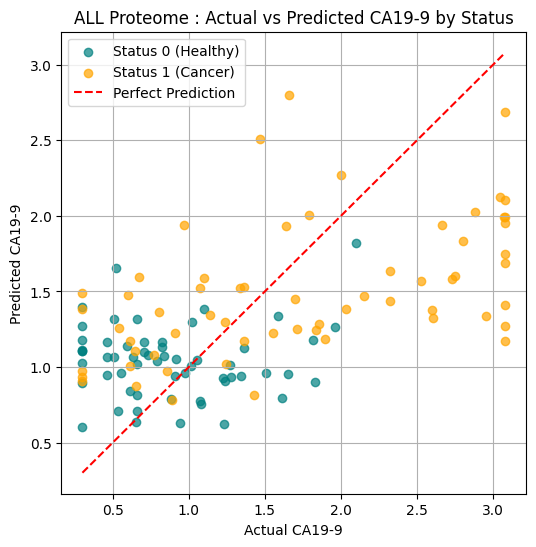

36


,Protein,Coefficient,Abs_Coef
736,MUC16,0.163074,0.163074
357,ANXA10,0.153609,0.153609
231,NEFL,0.104214,0.104214
109,CEACAM5,0.078703,0.078703
561,FAM3D,-0.070609,0.070609
681,KRT19,0.061216,0.061216
282,SFTPA2,-0.049588,0.049588
834,REG3G,0.046444,0.046444
560,FAM3B,-0.044315,0.044315
694,LIFR,0.039479,0.039479


In [36]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.3,
    random_state=123
)

tempI = X_test.index

pipeline = Pipeline([
    ('scaler', StandardScaler()),
    ('lasso', LassoCV(cv=5, random_state=123, n_jobs=-1))
])

pipeline.fit(X_train, y_train.values.ravel())


y_pred = pipeline.predict(X_test)

comparison_df = pd.DataFrame({
    'Actual_CA19_9': np.array(y_test).flatten(),
    'Predicted_CA19_9': np.array(y_pred).flatten()
}, index=tempI)
comparison_df['Abs_Diff'] = np.abs(comparison_df['Actual_CA19_9'] - comparison_df['Predicted_CA19_9'])
comparison_df['CancerStatus'] = pro_sample.loc[tempI, 'CaCo_Status']
comparison_df = comparison_df.sort_values(by='Abs_Diff', ascending=False)


# 上位50サンプルを表示
print("--- 各サンプルの実際のCA19-9 vs 予測されたCA19-9 ---")
print(comparison_df.head(50))

plt.figure(figsize=(6, 6))

# Status（0と1）でグループ分けしてプロット
colors = {0: 'teal', 1: 'orange'}
labels = {0: 'Status 0 (Healthy)', 1: 'Status 1 (Cancer)'}

for status in [0, 1]:
    subset = comparison_df[comparison_df['CancerStatus'] == status]
    plt.scatter(subset['Actual_CA19_9'], subset['Predicted_CA19_9'], 
                alpha=0.7, c=colors[status], label=labels[status])

# 完璧に予測できた場合の補助線（既存の処理）
max_val = max(comparison_df['Actual_CA19_9'].max(), comparison_df['Predicted_CA19_9'].max())
min_val = min(comparison_df['Actual_CA19_9'].min(), comparison_df['Predicted_CA19_9'].min())
plt.plot([min_val, max_val], [min_val, max_val], color='red', linestyle='--', label='Perfect Prediction')

plt.title("ALL Proteome : Actual vs Predicted CA19-9 by Status")
plt.xlabel("Actual CA19-9")
plt.ylabel("Predicted CA19-9")
plt.legend()
plt.grid(True)
plt.show()

# 1. パイプラインからLassoの係数を取り出す
coef = pipeline.named_steps['lasso'].coef_
feature_names = X.columns

# 2. データフレームにまとめて、影響度順にソート
importance_df = pd.DataFrame({
    'Protein': feature_names,
    'Coefficient': coef
}).assign(Abs_Coef = lambda x: x['Coefficient'].abs()) \
  .sort_values(by='Abs_Coef', ascending=False)

# 3. 係数が0でない（選ばれた）タンパク質のみ表示
selected_proteins = importance_df[importance_df['Coefficient'] != 0]
print(len(selected_proteins))
display(selected_proteins)

R2: 0.31649911121720575
RMSE: 0.7188298478721656
MAE: 0.5950810466706282
Pearson r: 0.5720729247539296
Spearman rho: 0.5065796221053523
--- 各サンプルの実際のCA19-9 vs 予測されたCA19-9 ---
             Actual_CA19_9  Predicted_CA19_9  Abs_Diff  progress
PE_R478_248       3.079181          1.172000  1.907181       410
PE_R478_244       3.079181          1.273035  1.806146       430
PE_R478_161       3.079181          1.410651  1.668530       430
PE_R478_166       2.950754          1.337599  1.613155       410
PE_R478_369       3.079181          1.688543  1.390638       420
PE_R478_148       3.079181          1.746618  1.332563       430
PE_R478_096       2.602386          1.324573  1.277812       410
PE_R478_372       2.598024          1.374000  1.224024       410
PE_R478_396       0.300813          1.492514  1.191701       410
PE_R478_121       2.751510          1.599095  1.152415       440
PE_R478_379       2.731024          1.579587  1.151438       410
PE_R478_034       1.661813          2.802058 

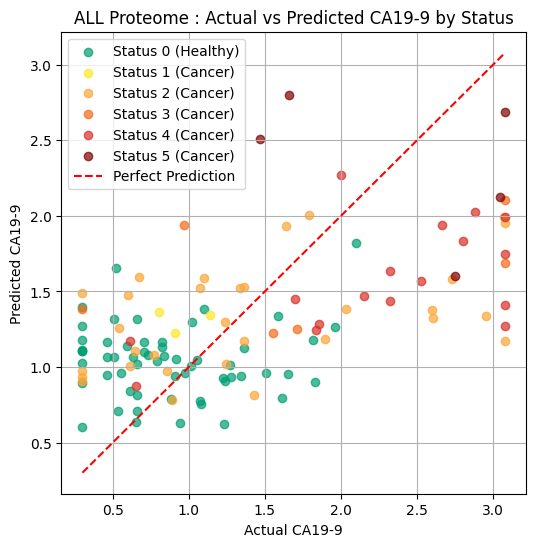

36


,Protein,Coefficient,Abs_Coef
736,MUC16,0.163074,0.163074
357,ANXA10,0.153609,0.153609
231,NEFL,0.104214,0.104214
109,CEACAM5,0.078703,0.078703
561,FAM3D,-0.070609,0.070609
681,KRT19,0.061216,0.061216
282,SFTPA2,-0.049588,0.049588
834,REG3G,0.046444,0.046444
560,FAM3B,-0.044315,0.044315
694,LIFR,0.039479,0.039479


In [51]:
from scipy.stats import pearsonr, spearmanr

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.3,
    random_state=123
)

tempI = X_test.index

pipeline = Pipeline([
    ('scaler', StandardScaler()),
    ('lasso', LassoCV(cv=5, random_state=123, n_jobs=-1))
])

pipeline.fit(X_train, y_train.values.ravel())


y_pred = pipeline.predict(X_test)

comparison_df = pd.DataFrame({
    'Actual_CA19_9': np.array(y_test).flatten(),
    'Predicted_CA19_9': np.array(y_pred).flatten()
}, index=tempI)
comparison_df['Abs_Diff'] = np.abs(comparison_df['Actual_CA19_9'] - comparison_df['Predicted_CA19_9'])
comparison_df['progress'] = pro_sample.loc[tempI, 'progress']
comparison_df = comparison_df.sort_values(by='Abs_Diff', ascending=False)

actual = np.asarray(y_test).ravel()
predicted = np.asarray(y_pred).ravel()

residual = predicted - actual

print("R2:", r2_score(actual, predicted))
print("RMSE:", np.sqrt(mean_squared_error(actual, predicted)))
print("MAE:", mean_absolute_error(actual, predicted))
print("Pearson r:", pearsonr(actual, predicted).statistic)
print("Spearman rho:", spearmanr(actual, predicted).statistic)

# 上位50サンプルを表示
print("--- 各サンプルの実際のCA19-9 vs 予測されたCA19-9 ---")
print(comparison_df.head(50))

plt.figure(figsize=(6, 6))

# Status（0と1）でグループ分けしてプロット
colors = {
    0:   '#009E73',  # Healthy：青緑
    400: '#FDE725',  # 黄色
    410: '#FCA636',  # オレンジ
    420: '#F66B19',  # 橙赤
    430: '#D73027',  # 赤
    440: '#7F0000'   # 濃い赤
}
labels = {0: 'Status 0 (Healthy)', 400: 'Status 1 (Cancer)',
          410: 'Status 2 (Cancer)',420: 'Status 3 (Cancer)',
          430: 'Status 4 (Cancer)',440: 'Status 5 (Cancer)'}

for status in [0 ,400,410,420,430,440]:
    subset = comparison_df[comparison_df['progress'] == status]
    plt.scatter(subset['Actual_CA19_9'], subset['Predicted_CA19_9'], 
                alpha=0.7, c=colors[status], label=labels[status])

# 完璧に予測できた場合の補助線（既存の処理）
max_val = max(comparison_df['Actual_CA19_9'].max(), comparison_df['Predicted_CA19_9'].max())
min_val = min(comparison_df['Actual_CA19_9'].min(), comparison_df['Predicted_CA19_9'].min())
plt.plot([min_val, max_val], [min_val, max_val], color='red', linestyle='--', label='Perfect Prediction')

plt.title("ALL Proteome : Actual vs Predicted CA19-9 by Status")
plt.xlabel("Actual CA19-9")
plt.ylabel("Predicted CA19-9")
plt.legend()
plt.grid(True)
plt.show()

# 1. パイプラインからLassoの係数を取り出す
coef = pipeline.named_steps['lasso'].coef_
feature_names = X.columns

# 2. データフレームにまとめて、影響度順にソート
importance_df = pd.DataFrame({
    'Protein': feature_names,
    'Coefficient': coef
}).assign(Abs_Coef = lambda x: x['Coefficient'].abs()) \
  .sort_values(by='Abs_Coef', ascending=False)

# 3. 係数が0でない（選ばれた）タンパク質のみ表示
selected_proteins = importance_df[importance_df['Coefficient'] != 0]
print(len(selected_proteins))
display(selected_proteins)

In [ ]:
# selected proteinの詳細を見るためエクスポート
selected_proteins.to_csv("./Data/lasso_selectedProteins.csv", index=False)

In [ ]:


X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.3,
    random_state=123
)
from sklearn.pipeline import Pipeline
from sklearn.model_selection import cross_val_score

# 1. パイプラインの定義 (標準化 + LassoCV)
pipeline = Pipeline([
    ('scaler', StandardScaler()),
    ('lasso', LassoCV(cv=5, random_state=123, n_jobs=-1))
])

# 2. 交差検証の実行 (R^2スコアを算出)
# yは.values.ravel()で1次元配列に変換します
scores = cross_val_score(pipeline, X, y.values.ravel(), cv=5, scoring='r2')

print(f"各分割のR^2スコア: {scores}")
print(f"平均R^2: {scores.mean():.4f} (+/- {scores.std() * 2:.4f})")


### DEPlistのみ

In [44]:
display(il2ra)

,sIL2R,logvalue
PE_R478_001,134.0,2.127105
PE_R478_002,5500.0,3.740363
PE_R478_003,259.0,2.413300
PE_R478_004,208.0,2.318063
PE_R478_005,1181.0,3.072250
...,...,...
PE_R478_396,263.0,2.419956
PE_R478_397,257.0,2.409933
PE_R478_398,257.0,2.409933
PE_R478_399,216.0,2.334454


In [52]:
cols = list(DEPlist.index)
temp = pro_data.loc[:, pro_data.columns.isin(cols)].copy()

X = pd.concat(
    [temp, il2ra["logvalue"].rename("IL2RA_logvalue")],
    axis=1
)
y = ca199[["logvalue"]]

print(X.shape)
print(y.shape)

print(X.index[:5])
print(y.index[:5])

(398, 25)
(398, 1)
Index(['PE_R478_001', 'PE_R478_002', 'PE_R478_003', 'PE_R478_004',
       'PE_R478_005'],
      dtype='str')
Index(['PE_R478_001', 'PE_R478_002', 'PE_R478_003', 'PE_R478_004',
       'PE_R478_005'],
      dtype='str')


R2: 0.28413759107439296
RMSE: 0.7356501687079288
MAE: 0.5868490604612145
Pearson r: 0.5395246985717217
Spearman rho: 0.5059921645210317
--- 各サンプルの実際のCA19-9 vs 予測されたCA19-9 ---
             Actual_CA19_9  Predicted_CA19_9  Abs_Diff  progress
PE_R478_248       3.079181          0.983946  2.095235       410
PE_R478_244       3.079181          1.293390  1.785792       430
PE_R478_166       2.950754          1.255749  1.695006       410
PE_R478_369       3.079181          1.403780  1.675401       420
PE_R478_161       3.079181          1.476288  1.602893       430
PE_R478_148       3.079181          1.648344  1.430838       430
PE_R478_102       3.079181          1.682912  1.396270       420
PE_R478_034       1.661813          3.031684  1.369871       440
PE_R478_143       0.300813          1.587032  1.286219         0
PE_R478_043       2.799961          1.534992  1.264969       430
PE_R478_016       1.466868          2.717808  1.250941       440
PE_R478_121       2.751510          1.508796 

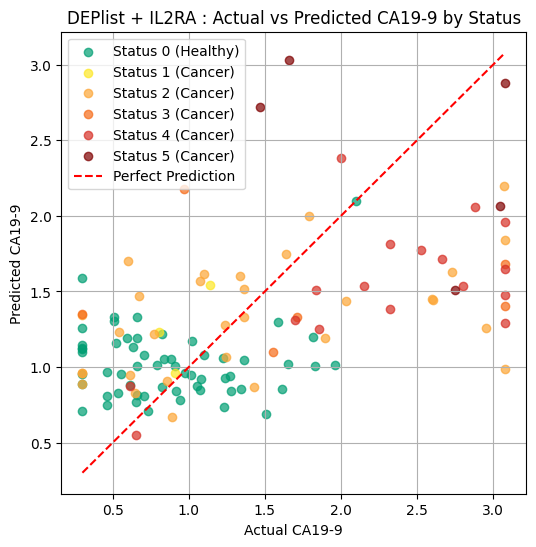

12


,Protein,Coefficient,Abs_Coef
17,MUC16,0.205014,0.205014
6,ANXA10,0.150422,0.150422
2,CEACAM5,0.120718,0.120718
16,KRT19,0.080379,0.080379
19,REG3G,0.078895,0.078895
22,TMPRSS15,-0.076860,0.076860
13,GP2,0.041923,0.041923
12,DPP10,0.019465,0.019465
8,CCL7,0.012709,0.012709
20,S100A12,0.012350,0.012350


In [47]:
from scipy.stats import pearsonr, spearmanr

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.3,
    random_state=123
)

tempI = X_test.index

pipeline = Pipeline([
    ('scaler', StandardScaler()),
    ('lasso', LassoCV(cv=5, random_state=123, n_jobs=-1))
])

pipeline.fit(X_train, y_train.values.ravel())


y_pred = pipeline.predict(X_test)

comparison_df = pd.DataFrame({
    'Actual_CA19_9': np.array(y_test).flatten(),
    'Predicted_CA19_9': np.array(y_pred).flatten()
}, index=tempI)
comparison_df['Abs_Diff'] = np.abs(comparison_df['Actual_CA19_9'] - comparison_df['Predicted_CA19_9'])
comparison_df['progress'] = pro_sample.loc[tempI, 'progress']
comparison_df = comparison_df.sort_values(by='Abs_Diff', ascending=False)

actual = np.asarray(y_test).ravel()
predicted = np.asarray(y_pred).ravel()

residual = predicted - actual

print("R2:", r2_score(actual, predicted))
print("RMSE:", np.sqrt(mean_squared_error(actual, predicted)))
print("MAE:", mean_absolute_error(actual, predicted))
print("Pearson r:", pearsonr(actual, predicted).statistic)
print("Spearman rho:", spearmanr(actual, predicted).statistic)

# 上位50サンプルを表示
print("--- 各サンプルの実際のCA19-9 vs 予測されたCA19-9 ---")
print(comparison_df.head(50))

plt.figure(figsize=(6, 6))

# Status（0と1）でグループ分けしてプロット
colors = {
    0:   '#009E73',  # Healthy：青緑
    400: '#FDE725',  # 黄色
    410: '#FCA636',  # オレンジ
    420: '#F66B19',  # 橙赤
    430: '#D73027',  # 赤
    440: '#7F0000'   # 濃い赤
}
labels = {0: 'Status 0 (Healthy)', 400: 'Status 1 (Cancer)',
          410: 'Status 2 (Cancer)',420: 'Status 3 (Cancer)',
          430: 'Status 4 (Cancer)',440: 'Status 5 (Cancer)'}

for status in [0 ,400,410,420,430,440]:
    subset = comparison_df[comparison_df['progress'] == status]
    plt.scatter(subset['Actual_CA19_9'], subset['Predicted_CA19_9'], 
                alpha=0.7, c=colors[status], label=labels[status])

# 完璧に予測できた場合の補助線（既存の処理）
max_val = max(comparison_df['Actual_CA19_9'].max(), comparison_df['Predicted_CA19_9'].max())
min_val = min(comparison_df['Actual_CA19_9'].min(), comparison_df['Predicted_CA19_9'].min())
plt.plot([min_val, max_val], [min_val, max_val], color='red', linestyle='--', label='Perfect Prediction')

plt.title("DEPlist + IL2RA : Actual vs Predicted CA19-9 by Status")
plt.xlabel("Actual CA19-9")
plt.ylabel("Predicted CA19-9")
plt.legend()
plt.grid(True)
plt.show()

# 1. パイプラインからLassoの係数を取り出す
coef = pipeline.named_steps['lasso'].coef_
feature_names = X.columns

# 2. データフレームにまとめて、影響度順にソート
importance_df = pd.DataFrame({
    'Protein': feature_names,
    'Coefficient': coef
}).assign(Abs_Coef = lambda x: x['Coefficient'].abs()) \
  .sort_values(by='Abs_Coef', ascending=False)

# 3. 係数が0でない（選ばれた）タンパク質のみ表示
selected_proteins = importance_df[importance_df['Coefficient'] != 0]
print(len(selected_proteins))
display(selected_proteins)

--- 各サンプルの実際のCA19-9 vs 予測されたCA19-9 ---
             Actual_CA19_9  Predicted_CA19_9  Abs_Diff  CancerStatus
PE_R478_248       3.079181          0.983946  2.095235             1
PE_R478_244       3.079181          1.293390  1.785792             1
PE_R478_166       2.950754          1.255749  1.695006             1
PE_R478_369       3.079181          1.403780  1.675401             1
PE_R478_161       3.079181          1.476288  1.602893             1
PE_R478_148       3.079181          1.648344  1.430838             1
PE_R478_102       3.079181          1.682912  1.396270             1
PE_R478_034       1.661813          3.031684  1.369871             1
PE_R478_143       0.300813          1.587032  1.286219             0
PE_R478_043       2.799961          1.534992  1.264969             1
PE_R478_016       1.466868          2.717808  1.250941             1
PE_R478_121       2.751510          1.508796  1.242714             1
PE_R478_186       3.079181          1.837808  1.241373          

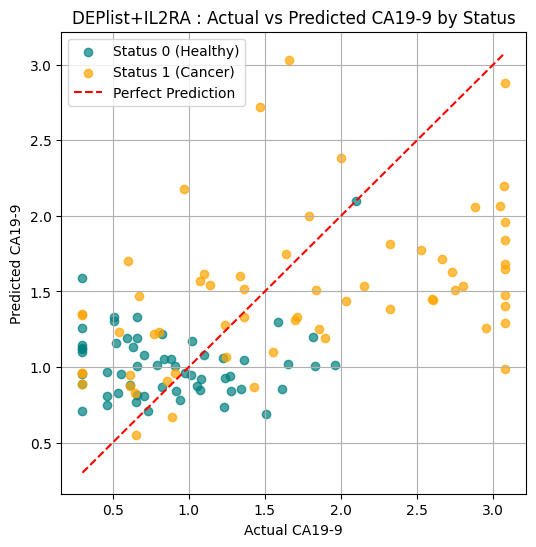

12


,Protein,Coefficient,Abs_Coef
17,MUC16,0.205014,0.205014
6,ANXA10,0.150422,0.150422
2,CEACAM5,0.120718,0.120718
16,KRT19,0.080379,0.080379
19,REG3G,0.078895,0.078895
22,TMPRSS15,-0.076860,0.076860
13,GP2,0.041923,0.041923
12,DPP10,0.019465,0.019465
8,CCL7,0.012709,0.012709
20,S100A12,0.012350,0.012350


In [53]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.3,
    random_state=123
)

tempI = X_test.index

pipeline = Pipeline([
    ('scaler', StandardScaler()),
    ('lasso', LassoCV(cv=5, random_state=123, n_jobs=-1))
])

pipeline.fit(X_train, y_train.values.ravel())


y_pred = pipeline.predict(X_test)

comparison_df = pd.DataFrame({
    'Actual_CA19_9': np.array(y_test).flatten(),
    'Predicted_CA19_9': np.array(y_pred).flatten()
}, index=tempI)
comparison_df['Abs_Diff'] = np.abs(comparison_df['Actual_CA19_9'] - comparison_df['Predicted_CA19_9'])
comparison_df['CancerStatus'] = pro_sample.loc[tempI, 'CaCo_Status']
comparison_df = comparison_df.sort_values(by='Abs_Diff', ascending=False)


# 上位50サンプルを表示
print("--- 各サンプルの実際のCA19-9 vs 予測されたCA19-9 ---")
print(comparison_df.head(50))

plt.figure(figsize=(6, 6))

# Status（0と1）でグループ分けしてプロット
colors = {0: 'teal', 1: 'orange'}
labels = {0: 'Status 0 (Healthy)', 1: 'Status 1 (Cancer)'}

for status in [0, 1]:
    subset = comparison_df[comparison_df['CancerStatus'] == status]
    plt.scatter(subset['Actual_CA19_9'], subset['Predicted_CA19_9'], 
                alpha=0.7, c=colors[status], label=labels[status])

# 完璧に予測できた場合の補助線（既存の処理）
max_val = max(comparison_df['Actual_CA19_9'].max(), comparison_df['Predicted_CA19_9'].max())
min_val = min(comparison_df['Actual_CA19_9'].min(), comparison_df['Predicted_CA19_9'].min())
plt.plot([min_val, max_val], [min_val, max_val], color='red', linestyle='--', label='Perfect Prediction')

plt.title("DEPlist+IL2RA : Actual vs Predicted CA19-9 by Status")
plt.xlabel("Actual CA19-9")
plt.ylabel("Predicted CA19-9")
plt.legend()
plt.grid(True)
plt.show()

# 1. パイプラインからLassoの係数を取り出す
coef = pipeline.named_steps['lasso'].coef_
feature_names = X.columns

# 2. データフレームにまとめて、影響度順にソート
importance_df = pd.DataFrame({
    'Protein': feature_names,
    'Coefficient': coef
}).assign(Abs_Coef = lambda x: x['Coefficient'].abs()) \
  .sort_values(by='Abs_Coef', ascending=False)

# 3. 係数が0でない（選ばれた）タンパク質のみ表示
selected_proteins = importance_df[importance_df['Coefficient'] != 0]
print(len(selected_proteins))
display(selected_proteins)

# SHAP value for each models

In [27]:
import sys
import numpy as np
import sklearn
import matplotlib
import scipy
import pandas as pd

print("Python:", sys.version)
print("NumPy:", np.__version__)
print("scikit-learn:", sklearn.__version__)
print("Matplotlib:", matplotlib.__version__)
print("SciPy:", scipy.__version__)
print("pandas:", pd.__version__)

%pip show shap pyarrow numexpr bottleneck

Python: 3.11.6 | packaged by conda-forge | (main, Oct  3 2023, 10:40:35) [GCC 12.3.0]
NumPy: 1.24.4
scikit-learn: 1.3.1
Matplotlib: 3.8.0
SciPy: 1.11.3
pandas: 2.1.1
Name: shap
Version: 0.45.1
Summary: A unified approach to explain the output of any machine learning model.
Home-page: 
Author: 
Author-email: Scott Lundberg <slund1@cs.washington.edu>
License: MIT License
Location: /opt/conda/lib/python3.11/site-packages
Requires: cloudpickle, numba, numpy, packaging, pandas, scikit-learn, scipy, slicer, tqdm
Required-by: 
---
Name: pyarrow
Version: 13.0.0
Summary: Python library for Apache Arrow
Home-page: https://arrow.apache.org/
Author: 
Author-email: 
License: Apache License, Version 2.0
Location: /opt/conda/lib/python3.11/site-packages
Requires: numpy
Required-by: 
---
Name: numexpr
Version: 2.8.7
Summary: Fast numerical expression evaluator for NumPy
Home-page: https://github.com/pydata/numexpr
Author: David M. Cooke, Francesc Alted, and others
Author-email: 
License: MIT
Location:

In [17]:
%pip install --force-reinstall --no-cache-dir "shap<0.46"

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 62.1/62.1 kB 37.3 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 79.5/79.5 kB 382.7 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 57.4/57.4 kB 396.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 540.6/540.6 kB 88.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 130.0/130.0 kB 90.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 80.2/80.2 kB 121.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.8/3.8 MB 123.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 16.9/16.9 MB 111.5 MB/s eta 0:00:00a 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 11.1/11.1 MB 70.0 MB/s eta 0:00:00 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.3/9.3 MB 115.9 MB/s eta 0:00:00a 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 35.3/35.3 MB 96.9 MB/s eta 0:00:0000:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 306.1/306.1 kB 125.9 MB/s eta 0:00:00
   ━

In [18]:
import numpy as np
print(np.__version__)

1.24.4


In [16]:
import shap


shap.initjs()

# フォント設定
plt.rcParams["font.family"] = "sans-serif"
plt.rcParams["font.sans-serif"] = ["Arial", "Liberation Sans", "DejaVu Sans"]


def calculate_cv_shap(data, sample, models, data_name):

    # DEPlistのタンパク質だけを抽出
    X = data.loc[:, data.columns.isin(DEPlist.index)]
    y = sample["Cancer"]

    # モデルと特徴量の順番を確認
    print(f"\n===== {data_name} =====")
    print("X shape:", X.shape)
    print("Number of models:", len(models))

    all_model_shap_values = []

    print("Calculating SHAP values...")

    # 5モデルすべてについてSHAPを計算
    for i, model in enumerate(models):

        explainer = shap.TreeExplainer(model)
        shap_values = explainer(X)

        # クラス1（癌）のSHAP value
        if len(shap_values.shape) == 3:
            shap_values_class1 = shap_values[:, :, 1]
        else:
            shap_values_class1 = shap_values

        all_model_shap_values.append(shap_values_class1)

        print(f"Fold {i+1} completed")

    # --------------------------------
    # 5モデルのSHAP valueを平均
    # --------------------------------

    mean_shap_values = all_model_shap_values[0]

    combined_values = np.zeros_like(mean_shap_values.values)

    for sv in all_model_shap_values:
        combined_values += sv.values

    mean_shap_values.values = (
        combined_values / len(models)
    )

    # --------------------------------
    # Mean Absolute SHAP Value
    # --------------------------------

    shap_v = np.abs(
        mean_shap_values.values
    ).mean(axis=0)

    feature_names = X.columns.tolist()

    shap_importance_df = pd.DataFrame({
        "Feature": feature_names,
        "SHAP_Importance": shap_v
    })

    sorted_shap_importance_df = (
        shap_importance_df
        .sort_values(
            by="SHAP_Importance",
            ascending=False
        )
        .reset_index(drop=True)
    )

    print("\n--- SHAP Based Feature Importance ---")
    display(sorted_shap_importance_df.head(15))

    # --------------------------------
    # SHAP Summary Plot
    # --------------------------------

    plt.figure(figsize=(7, 5))

    shap.summary_plot(
        mean_shap_values,
        X,
        max_display=15,
        show=False
    )

    plt.title(
        f"SHAP Summary Plot ({data_name})",
        fontsize=13,
        pad=15
    )

    plt.tight_layout()

    plt.savefig(
        f"shap_summary_plot_cv5_{data_name}.png",
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()

    return sorted_shap_importance_df, mean_shap_values

ModuleNotFoundError: No module named 'shap'

In [ ]:
shap_importance_main, shap_values_main = calculate_cv_shap(
    data=pro_data,
    sample=pro_sample,
    models=modelsets_HER_DEP,
    data_name="pro_data"
)

# CA19-9とメタデータの項目の関連

In [ ]:
display(pro_sample)

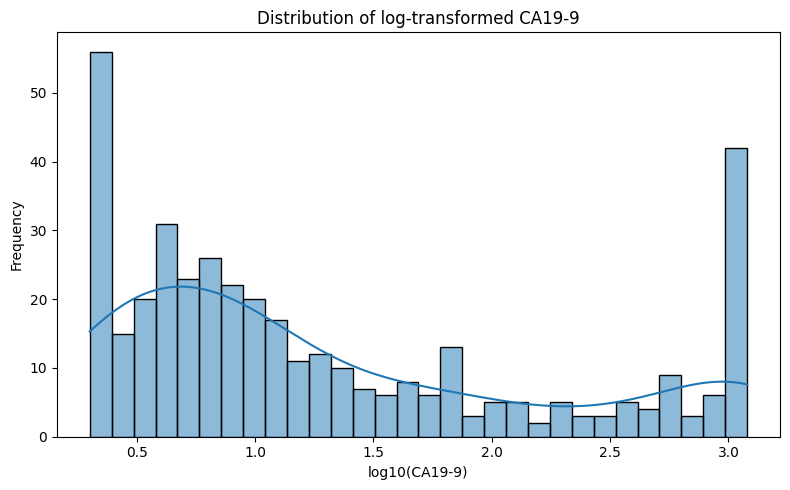

In [54]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(8, 5))

sns.histplot(
    data=ca199,
    x="logvalue",
    bins=30,
    kde=True
)

plt.xlabel("log10(CA19-9)")
plt.ylabel("Frequency")
plt.title("Distribution of log-transformed CA19-9")
plt.tight_layout()
plt.show()

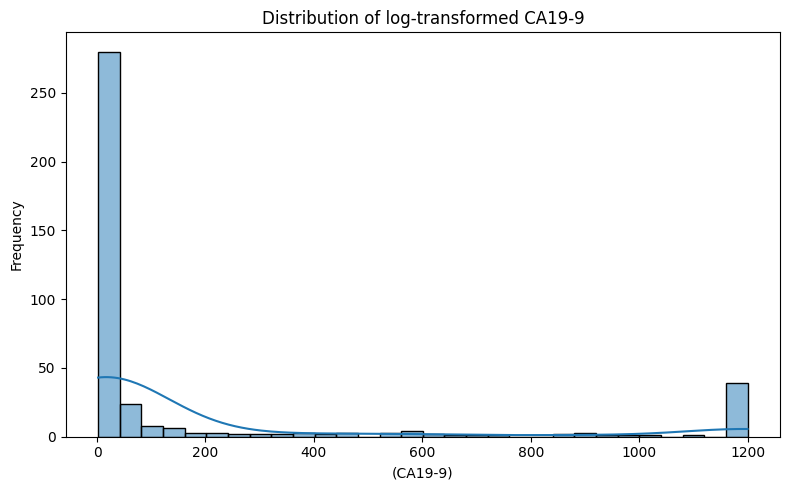

In [57]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(8, 5))

sns.histplot(
    data=ca199,
    x="CA19_9",
    bins=30,
    kde=True
)

plt.xlabel("(CA19-9)")
plt.ylabel("Frequency")
plt.title("Distribution of log-transformed CA19-9")
plt.tight_layout()
plt.show()

In [58]:
ca199.describe()

,CA19_9,logvalue
count,398.000000,398.000000
mean,187.232035,1.301890
std,380.108959,0.913603
min,1.999000,0.300813
25%,4.000000,0.602060
50%,9.400000,0.973128
75%,68.000000,1.832496
max,1200.000000,3.079181


# 4つのモデル合わせたROCcurve

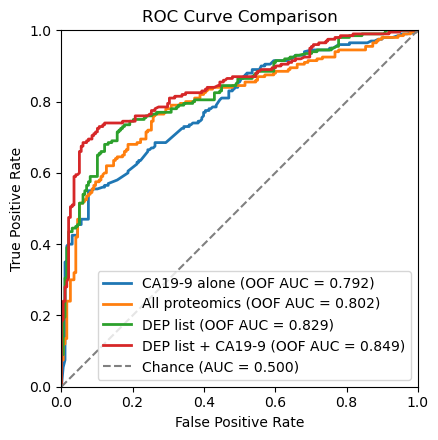

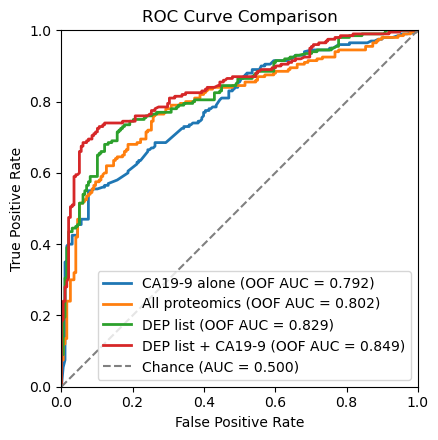

In [73]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import roc_curve, roc_auc_score

# ==========================================
# 各モデルの保存先
# ==========================================
model_files = {
    "CA19-9 alone": "./RF_Data/RF_status_ca199/oof_predictions.csv",
    "All proteomics": "./RF_Data/RF_status_all/oof_predictions.csv",
    "DEP list": "./RF_Data/RF_status_DEP/oof_predictions.csv",
    "DEP list + CA19-9": "./RF_Data/RF_status_DEPca199/oof_predictions.csv"
}

# ==========================================
# ROC曲線を描画
# ==========================================
fig, ax = plt.subplots(figsize=(4.5, 4.5))

for name, file in model_files.items():

    df = pd.read_csv(file)

    y_true = df["TrueClass"].to_numpy()
    y_prob = df["PredictedProbability"].to_numpy()

    # OOF予測値を用いたROCとAUC
    fpr, tpr, _ = roc_curve(y_true, y_prob)
    auc = roc_auc_score(y_true, y_prob)

    # 5-foldの平均AUC ± SDを別途計算している場合は、
    # その値に置き換えて凡例に表示できます
    ax.plot(
        fpr, tpr,
        label=f"{name} (OOF AUC = {auc:.3f})",
        linewidth=2
    )

# ランダム分類の基準線
ax.plot(
    [0, 1], [0, 1],
    linestyle="--",
    color="gray",
    label="Chance (AUC = 0.500)"
)

ax.set_xlabel("False Positive Rate")
ax.set_ylabel("True Positive Rate")
ax.set_title("ROC Curve Comparison")
ax.legend(loc="lower right")
ax.set_xlim(0, 1)
ax.set_ylim(0, 1)
ax.set_aspect("equal", adjustable="box")

plt.tight_layout()
display(fig)
plt.show()

fig.savefig(
    "./ExportData/ROC_comparison.png",
    dpi=600,
    transparent=True,
    bbox_inches="tight"
)

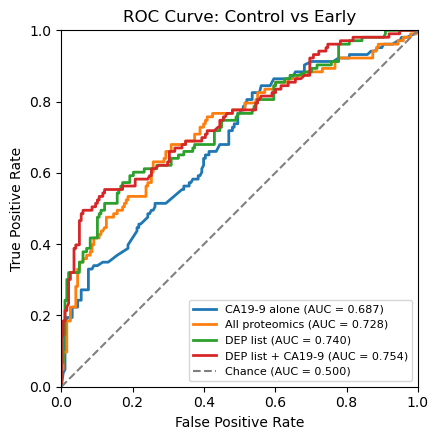

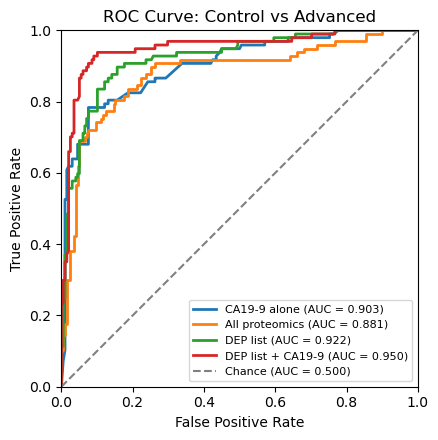

In [75]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import roc_curve, roc_auc_score

# ==========================================
# 各モデルの保存先
# ==========================================
model_files = {
    "CA19-9 alone": "./RF_Data/RF_status_ca199/oof_predictions.csv",
    "All proteomics": "./RF_Data/RF_status_all/oof_predictions.csv",
    "DEP list": "./RF_Data/RF_status_DEP/oof_predictions.csv",
    "DEP list + CA19-9": "./RF_Data/RF_status_DEPca199/oof_predictions.csv"
}

# ==========================================
# progress_groupをサンプルIDで対応させる
# ==========================================
progress = (
    pro_sample["progress_group"]
    .astype(str)
    .str.strip()
    .str.lower()
)

# Control / Early / Advanced のラベルを統一
progress = progress.replace({
    "control": "0",
    "early": "1",
    "advanced": "2"
})

# ==========================================
# 2種類のROC曲線を作成
# ==========================================
comparisons = {
    "Control vs Early": ["0", "1"],
    "Control vs Advanced": ["0", "2"]
}

for comparison_name, selected_groups in comparisons.items():

    fig, ax = plt.subplots(figsize=(4.5, 4.5))

    for name, file in model_files.items():

        df = pd.read_csv(file, index_col="SampleID")

        # サンプルIDでprogress_groupを対応させる
        df["progress_group"] = progress.reindex(df.index).to_numpy()

        # Controlと対象群だけ抽出
        df = df[
            df["progress_group"].isin(selected_groups)
        ].dropna(subset=["TrueClass", "PredictedProbability"])

        # ROC計算用の二値ラベル
        y_true = (
            df["progress_group"] == selected_groups[1]
        ).astype(int).to_numpy()

        y_prob = df["PredictedProbability"].to_numpy()

        # 両クラスが存在する場合のみ計算
        if len(np.unique(y_true)) < 2:
            print(f"{comparison_name}: {name} は両クラスが存在しません")
            continue

        fpr, tpr, _ = roc_curve(y_true, y_prob)
        auc = roc_auc_score(y_true, y_prob)

        ax.plot(
            fpr,
            tpr,
            label=f"{name} (AUC = {auc:.3f})",
            linewidth=2
        )

    # ランダム分類の基準線
    ax.plot(
        [0, 1], [0, 1],
        linestyle="--",
        color="gray",
        label="Chance (AUC = 0.500)"
    )

    ax.set_xlabel("False Positive Rate")
    ax.set_ylabel("True Positive Rate")
    ax.set_title(f"ROC Curve: {comparison_name}")
    ax.legend(loc="lower right", fontsize=8)
    ax.set_xlim(0, 1)
    ax.set_ylim(0, 1)
    ax.set_aspect("equal", adjustable="box")

    plt.tight_layout()

    # ファイル名を作成
    filename = comparison_name.replace(" ", "_").replace("/", "_")

    fig.savefig(
        f"./ExportData/ROC_{filename}.png",
        dpi=600,
        transparent=True,
        bbox_inches="tight"
    )


    plt.show()
    plt.close(fig)

# 120人での検証